# **Project Name**    - Integrated Retail Analytics for Store Optimization and Demand Forecasting

##### **Project Type**    - EDA / Regression (demand forecasting) / Unsupervised (anomaly detection, segmentation, association rules)
##### **Contribution**    - Individual
##### **Team Member 1 -** Taha Saifee

# **Project Summary -**

This project looks at three years of weekly sales of a retail chain with 45 stores and 81 departments, from February 2010 to October 2012. The data comes in three files: weekly sales per store and department (421,570 rows), weekly store features (temperature, fuel price, five types of markdowns, CPI and unemployment) and the type and size of every store. The goal was to use this data to optimise the stores, forecast demand and suggest marketing and inventory strategies.

I started by joining the three files into one table and checking the quality. There were no duplicates. The missing values were all in the features file, and they meant two different things: the markdowns were simply not recorded before November 2011, and after that an empty cell meant no markdown that week. I filled them with 0 and added a flag for the recording period. CPI and unemployment were only missing for future weeks, so I carried the last value forward. Negative weekly sales (returns) were set to 0 for modelling.

The time analysis showed that the chain lives on a short season. Sales are flat at about 46M $ a week and then jump at Thanksgiving (+43%) and especially in the week before Christmas (+70%). That week is not flagged as a holiday in the data, while the flagged Christmas week is actually below normal. An STL decomposition showed almost no growth (about 3%) and pointed to the biggest time-based anomalies: Easter, which moves between years, and the shift of Christmas Eve between weeks. Three hypothesis tests showed that holiday weeks sell more (p = 2e-11), that sales per square foot differ by store type (small C stores are the most efficient), and that regional unemployment does not set a store's sales level.

For anomaly detection I compared a z-score rule with an Isolation Forest, scored on fake anomalies I injected into a copy of the data. After tuning, the forest reached an F1 of 0.55 against 0.48. On the real data it flagged 1.5% of the store-department weeks. More than half were holiday peaks or events that come back every year, like Easter and Valentine's Day, so I kept them as real demand and only cleaned the one-off ones. Training the forecast on the cleaned data did not help, so the final forecast uses the real sales.

For segmentation I used KMeans on the stores. All 13 store features gave weak segments (silhouette 0.20), but four well-chosen features (sales volume, Q4 uplift, markdown share and regional CPI) gave four clear and stable segments (silhouette 0.415, bootstrap stability 0.82): large stores in high-CPI regions, large stores in low-CPI regions, mid-size promotion-driven stores and small steady stores. Since there are no customer receipts, I inferred product associations with Apriori on store-weeks, which found five groups of departments that gain sales together.

For demand forecasting I compared a seasonal naive baseline, Holt-Winters per series and a global LightGBM model, tuned with time-series cross-validation. The long-term model forecasts 39 weeks ahead with a WMAE of 1,533 $ (15% better than the baseline, and better than Holt-Winters), and a short-term version reaches 1,300 $ one week ahead. External factors improved the forecast by about 5%, with temperature and unemployment the most useful. The biggest markdowns did not bring extra growth except in the promotion-driven segment.

Finally, I turned the results into strategies per segment, ABC-XYZ inventory rules for the departments and cross-selling ideas, discussed the real-world challenges, and used the saved model to forecast the next 39 weeks (Nov 2012 to Jul 2013).

# **GitHub Link -**

https://github.com/Tahascommit/retail-analytics-capstone

# **Problem Statement**


**A retail chain with 45 stores in different regions sells across 81 departments. Sales move a lot from week to week: a few holiday weeks bring in far more than normal weeks, promotions (markdowns) run at different times, and the stores sit in regions with different prices, fuel costs, weather and unemployment. If the chain plans stock and staff on a flat average it runs out of stock in the busy weeks and is left with too much stock in the quiet ones.**

**The goal of this project is to use the weekly sales history (Feb 2010 to Oct 2012) together with the store and regional data to: find unusual sales weeks and decide which are real demand and which are noise, understand the seasonal and holiday patterns, group the stores into segments that can be planned differently, find departments that sell well together, forecast weekly sales for every store and department in the short and long term, measure how much the economy and markdowns really change sales, and turn all of this into practical inventory, marketing and store strategies.**

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required. 
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits. 
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule. 

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

### How this notebook covers the 10 project components

| # | Project component | Where to find it |
|---|---|---|
| 1 | Anomaly detection in sales data | Charts 5 and 6, outlier handling in 6.2, ML Model 1 (Isolation Forest) |
| 2 | Time-based anomalies, seasonality and holiday effects | Charts 1 to 4 and 6, Hypothesis 1 |
| 3 | Data preprocessing and feature engineering | Sections 3 and 6 |
| 4 | Customer (store) segmentation | ML Model 2 |
| 5 | Market basket analysis | Section 7.1 |
| 6 | Demand forecasting, short and long term | ML Model 3 and Future Work |
| 7 | Impact of external factors | Charts 11 to 15, Hypothesis 3, Section 7.2 |
| 8 | Personalization and inventory strategies | Section 7.3 |
| 9 | Segmentation quality evaluation | ML Model 2, part 5 |
| 10 | Real-world strategy and challenges | Section 7.4 and the Conclusion |

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
import lightgbm as lgb
try:
    from mlxtend.frequent_patterns import apriori, association_rules
except ImportError:   # not always preinstalled on Colab
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mlxtend"], check=True)
    from mlxtend.frequent_patterns import apriori, association_rules
from joblib import Parallel, delayed
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

SEED = 42
TYPE_COLORS = {"A": "#4C72B0", "B": "#DD8452", "C": "#55A868"}
HOLIDAY_COLORS = {"SuperBowl": "#8172B3", "LaborDay": "#55A868", "Thanksgiving": "#DD8452", "Christmas": "#C44E52"}

# every chart is also saved as a png, so the repo has the visual outputs
FIG_DIR = "outputs/figures"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs("models", exist_ok=True)


def save_fig(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=120, bbox_inches="tight")


def wmae(y_true, y_pred, is_holiday):
    """Weighted MAE: holiday weeks count 5 times (the metric used for this dataset on Kaggle)."""
    w = np.where(np.asarray(is_holiday) == 1, 5, 1)
    return np.sum(w * np.abs(np.asarray(y_true) - np.asarray(y_pred))) / np.sum(w)

### Dataset Loading

In [2]:
# Load Dataset
# the three csv files are in the repo's data folder; on Colab (no local copy) they are read from GitHub
LOCAL_DIR = "data"
GITHUB_DIR = "https://raw.githubusercontent.com/Tahascommit/retail-analytics-capstone/main/data"


def read_data(name):
    path = f"{LOCAL_DIR}/{name}" if os.path.exists(f"{LOCAL_DIR}/{name}") else f"{GITHUB_DIR}/{name}"
    try:
        return pd.read_csv(path)
    except Exception as e:
        raise RuntimeError(f"could not read {path}: {e}")


sales = read_data("sales_data.csv")
features = read_data("features_data.csv")
stores = read_data("stores_data.csv")
print("data read from:", "local data folder" if os.path.exists(f"{LOCAL_DIR}/sales_data.csv") else "GitHub")

data read from: local data folder


### Dataset First View

In [3]:
# Dataset First Look
print("sales: one row per store, department and week")
display(sales.head())
print("features: one row per store and week (weather, fuel price, markdowns, CPI, unemployment)")
display(features.head())
print("stores: type and size of each store")
display(stores.head())

sales: one row per store, department and week


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,05/02/2010,24924.50,False
1,1,1,12/02/2010,46039.49,True
2,1,1,19/02/2010,41595.55,False
3,1,1,26/02/2010,19403.54,False
4,1,1,05/03/2010,21827.90,False


features: one row per store and week (weather, fuel price, markdowns, CPI, unemployment)


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,05/02/2010,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,12/02/2010,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,19/02/2010,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,26/02/2010,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,05/03/2010,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


stores: type and size of each store


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
for name, d in [("sales", sales), ("features", features), ("stores", stores)]:
    print(f"{name:9} {d.shape[0]:>7,} rows   {d.shape[1]:>2} columns")

sales     421,570 rows    5 columns
features    8,190 rows   12 columns
stores         45 rows    3 columns


### Dataset Information

In [5]:
# Dataset Info
for name, d in [("sales", sales), ("features", features), ("stores", stores)]:
    print(f"----- {name} -----")
    d.info()
    print()

----- sales -----
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  object 
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1)
memory usage: 13.3+ MB

----- features -----
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8190 entries, 0 to 8189
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         8190 non-null   int64  
 1   Date          8190 non-null   object 
 2   Temperature   8190 non-null   float64
 3   Fuel_Price    8190 non-null   float64
 4   MarkDown1     4032 non-null   float64
 5   MarkDown2     2921 non-null   float64
 6   MarkDown3     

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("fully duplicated rows -> sales:", sales.duplicated().sum(),
      "| features:", features.duplicated().sum(), "| stores:", stores.duplicated().sum())
# a store + dept + week should appear only once in sales, and a store + week only once in features
print("duplicated keys -> sales (Store, Dept, Date):", sales.duplicated(["Store", "Dept", "Date"]).sum(),
      "| features (Store, Date):", features.duplicated(["Store", "Date"]).sum())

fully duplicated rows -> sales: 0 | features: 0 | stores: 0
duplicated keys -> sales (Store, Dept, Date): 0 | features (Store, Date): 0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
for name, d in [("sales", sales), ("features", features), ("stores", stores)]:
    m = d.isna().sum()
    print(f"{name}: {m.sum():,} missing values")
    if m.sum():
        print(pd.DataFrame({"missing": m[m > 0], "missing %": (100 * m[m > 0] / len(d)).round(1)}).to_string(), "\n")

sales: 0 missing values
features: 24,040 missing values
              missing  missing %
MarkDown1        4158       50.8
MarkDown2        5269       64.3
MarkDown3        4577       55.9
MarkDown4        4726       57.7
MarkDown5        4140       50.5
CPI               585        7.1
Unemployment      585        7.1 

stores: 0 missing values


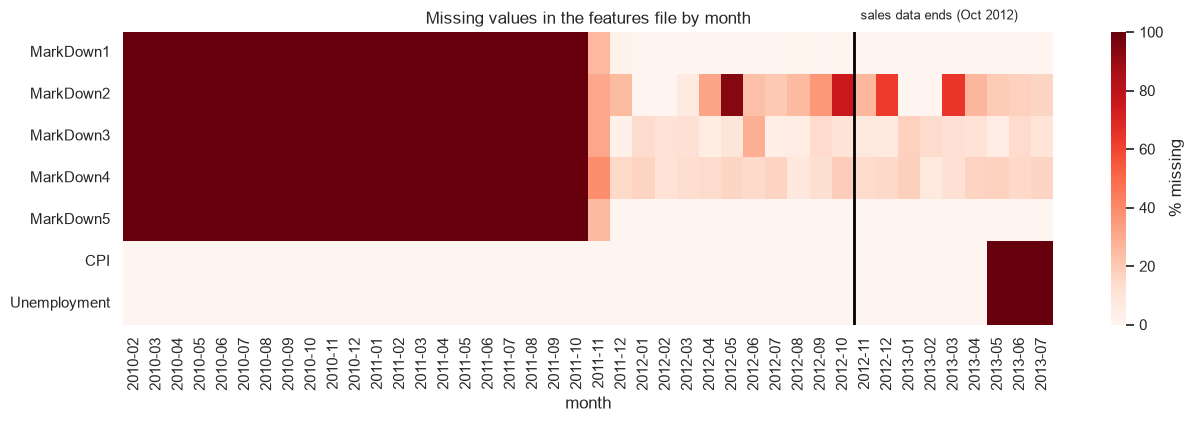

In [8]:
# Visualizing the missing values
# share of missing values per month in the features file
f_month = pd.to_datetime(features["Date"], format="%d/%m/%Y").dt.to_period("M")
miss_cols = [f"MarkDown{i}" for i in range(1, 6)] + ["CPI", "Unemployment"]
miss_by_month = features[miss_cols].isna().groupby(f_month).mean().T * 100

fig, ax = plt.subplots(figsize=(15, 3.8))
sns.heatmap(miss_by_month, cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% missing"}, ax=ax,
            xticklabels=[str(p) for p in miss_by_month.columns])
last_sales = list(miss_by_month.columns).index(pd.Period("2012-10", "M")) + 1
ax.axvline(last_sales, color="black", lw=2)
ax.text(last_sales + 0.3, -0.3, "sales data ends (Oct 2012)", fontsize=9)
ax.set_title("Missing values in the features file by month")
ax.set_xlabel("month")
ax.set_ylabel("")
save_fig(fig, "00_missing_values")
plt.show()

### What did you know about your dataset?

There are three files that fit together. The sales file has 421,570 rows: one row per store, department and week, from 5 Feb 2010 to 26 Oct 2012 (143 weeks), for 45 stores and 81 departments. Not every department exists in every store or every week, so there are 3,331 store-department series and 2,660 of them have all 143 weeks. The features file has one row per store and week (8,190 rows) and runs further, to 26 Jul 2013, so it can be used for forecasting future weeks. The stores file only has the type (A, B or C) and the size of each store.

There are no duplicated rows and no duplicated keys. The sales and stores files have no missing values. All the missing values are in the features file: the five MarkDown columns are 50-64% empty, and the heatmap shows why. Markdowns were simply not recorded before November 2011, and after that an empty cell mostly means there was no markdown of that type that week. CPI and Unemployment are missing in 585 rows (7.1%), but only for May to July 2013, which are future weeks without sales. Weekly sales are very skewed (median 7,612 $, mean 15,981 $, maximum 693,099 $) and some weeks are negative, which means returns were bigger than sales.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
for name, d in [("sales", sales), ("features", features), ("stores", stores)]:
    print(f"{name:9}", list(d.columns))

sales     ['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']
features  ['Store', 'Date', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday']
stores    ['Store', 'Type', 'Size']


In [10]:
# Dataset Describe
display(sales.describe().round(2))
display(features.describe().round(2))
display(stores.describe(include="all"))

,Store,Dept,Weekly_Sales
count,421570.00,421570.00,421570.00
mean,22.20,44.26,15981.26
std,12.79,30.49,22711.18
min,1.00,1.00,-4988.94
25%,11.00,18.00,2079.65
50%,22.00,37.00,7612.03
75%,33.00,74.00,20205.85
max,45.00,99.00,693099.36


,Store,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
count,8190.00,8190.00,8190.00,4032.00,2921.00,3613.00,3464.00,4050.00,7605.00,7605.00
mean,23.00,59.36,3.41,7032.37,3384.18,1760.10,3292.94,4132.22,172.46,7.83
std,12.99,18.68,0.43,9262.75,8793.58,11276.46,6792.33,13086.69,39.74,1.88
min,1.00,-7.29,2.47,-2781.45,-265.76,-179.26,0.22,-185.17,126.06,3.68
25%,12.00,45.90,3.04,1577.53,68.88,6.60,304.69,1440.83,132.36,6.63
50%,23.00,60.71,3.51,4743.58,364.57,36.26,1176.42,2727.14,182.76,7.81
75%,34.00,73.88,3.74,8923.31,2153.35,163.15,3310.01,4832.56,213.93,8.57
max,45.00,101.95,4.47,103184.98,104519.54,149483.31,67474.85,771448.10,228.98,14.31


,Store,Type,Size
count,45.000000,45,45.000000
unique,NaN,3,NaN
top,NaN,A,NaN
freq,NaN,22,NaN
mean,23.000000,NaN,130287.600000
std,13.133926,NaN,63825.271991
min,1.000000,NaN,34875.000000
25%,12.000000,NaN,70713.000000
50%,23.000000,NaN,126512.000000
75%,34.000000,NaN,202307.000000


### Variables Description 

| Column | File | Meaning |
|---|---|---|
| Store | all | store number, 1 to 45 |
| Dept | sales | department number (81 different ones, no names are given) |
| Date | sales, features | the Friday that ends the week |
| Weekly_Sales | sales | sales of the department in that store and week, in dollars (the target for forecasting) |
| IsHoliday | sales, features | True if the week has one of the 4 big holidays (Super Bowl, Labor Day, Thanksgiving, Christmas) |
| Temperature | features | average temperature in the store's region that week (°F) |
| Fuel_Price | features | fuel price in the region ($ per gallon) |
| MarkDown1-5 | features | 5 kinds of promotional markdowns (price cuts) running that week, in dollars. Only recorded from November 2011 |
| CPI | features | consumer price index of the region |
| Unemployment | features | unemployment rate of the region (%) |
| Type | stores | store type A, B or C |
| Size | stores | store size in square feet |

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
for name, d in [("sales", sales), ("features", features), ("stores", stores)]:
    print(f"----- {name}")
    print(d.nunique().to_string())
print("\nstore types:", stores["Type"].value_counts().to_dict())
print("IsHoliday in sales:", sales["IsHoliday"].value_counts().to_dict())

----- sales
Store               45
Dept                81
Date               143
Weekly_Sales    359464
IsHoliday            2
----- features
Store             45
Date             182
Temperature     4178
Fuel_Price      1011
MarkDown1       4023
MarkDown2       2715
MarkDown3       2885
MarkDown4       3405
MarkDown5       4045
CPI             2505
Unemployment     404
IsHoliday          2
----- stores
Store    45
Type      3
Size     40

store types: {'A': 22, 'B': 17, 'C': 6}
IsHoliday in sales: {False: 391909, True: 29661}


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.
# 1. real dates (the files use day/month/year)
sales["Date"] = pd.to_datetime(sales["Date"], format="%d/%m/%Y")
features["Date"] = pd.to_datetime(features["Date"], format="%d/%m/%Y")
print("sales weeks   :", sales["Date"].min().date(), "to", sales["Date"].max().date(), f"({sales['Date'].nunique()} weeks)")
print("features weeks:", features["Date"].min().date(), "to", features["Date"].max().date(), f"({features['Date'].nunique()} weeks)")

# 2. IsHoliday is in both files: check that they agree, then keep the one from sales
check = sales.merge(features[["Store", "Date", "IsHoliday"]], on=["Store", "Date"], suffixes=("", "_f"))
print("rows where the two IsHoliday flags differ:", (check["IsHoliday"] != check["IsHoliday_f"]).sum())

# 3. one table: every store-dept-week row gets the store's features for that week, plus store type and size
df = (sales.merge(features.drop(columns="IsHoliday"), on=["Store", "Date"], how="left")
           .merge(stores, on="Store", how="left"))
print("merged table:", df.shape, "| rows without matching features:", df["Temperature"].isna().sum())

# 4. calendar columns
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
df["IsHoliday"] = df["IsHoliday"].astype(int)

# 5. which holiday a flagged week is (dates from the dataset description)
HOLIDAYS = {
    "SuperBowl":    ["2010-02-12", "2011-02-11", "2012-02-10", "2013-02-08"],
    "LaborDay":     ["2010-09-10", "2011-09-09", "2012-09-07", "2013-09-06"],
    "Thanksgiving": ["2010-11-26", "2011-11-25", "2012-11-23", "2013-11-29"],
    "Christmas":    ["2010-12-31", "2011-12-30", "2012-12-28", "2013-12-27"],
}


def holiday_name(dates):
    name = pd.Series("None", index=dates.index)
    for h, days in HOLIDAYS.items():
        name[dates.isin(pd.to_datetime(days))] = h
    return name


df["Holiday"] = holiday_name(df["Date"])
# the week ending on the last Friday before Christmas is the busiest week of the year, but it is not flagged
PRE_CHRISTMAS = pd.to_datetime(["2010-12-24", "2011-12-23", "2012-12-21"])
df["PreChristmas"] = df["Date"].isin(PRE_CHRISTMAS).astype(int)
# Easter moves between years (between late March and late April), so it gets its own flag: the week ending on Good Friday
EASTER = pd.to_datetime(["2010-04-02", "2011-04-22", "2012-04-06", "2013-03-29"])
df["Easter"] = df["Date"].isin(EASTER).astype(int)

# 6. negative sales: weeks where returns were bigger than sales
df["Is_Return_Week"] = (df["Weekly_Sales"] < 0).astype(int)

# 7. markdowns were only recorded from November 2011 on
MARKDOWN_COLS = [f"MarkDown{i}" for i in range(1, 6)]
MD_START = features.loc[features[MARKDOWN_COLS].notna().any(axis=1), "Date"].min()
df["MarkDown_Recorded"] = (df["Date"] >= MD_START).astype(int)
print("first week with any markdown data:", MD_START.date())

df = df.sort_values(["Store", "Dept", "Date"]).reset_index(drop=True)

# 8. two smaller tables for the charts
# store_week: one row per store and week, with the store's total sales and that week's features
store_week = (df.groupby(["Store", "Date"], as_index=False)
                .agg(Sales=("Weekly_Sales", "sum"), Type=("Type", "first"), Size=("Size", "first"),
                     IsHoliday=("IsHoliday", "max"), Holiday=("Holiday", "first"), PreChristmas=("PreChristmas", "max"),
                     Temperature=("Temperature", "first"), Fuel_Price=("Fuel_Price", "first"),
                     CPI=("CPI", "first"), Unemployment=("Unemployment", "first"),
                     **{c: (c, "first") for c in MARKDOWN_COLS}))
store_week["Sales_M"] = store_week["Sales"] / 1e6
store_week["Year"] = store_week["Date"].dt.year
store_week["Week"] = store_week["Date"].dt.isocalendar().week.astype(int)
# weekly_total: all 45 stores added up
weekly_total = store_week.groupby("Date").agg(Sales=("Sales", "sum"), IsHoliday=("IsHoliday", "max"),
                                              Holiday=("Holiday", "first"), PreChristmas=("PreChristmas", "max"))

series_len = df.groupby(["Store", "Dept"]).size()
print(f"store_week: {store_week.shape}, weekly_total: {weekly_total.shape}")
print(f"store-dept series: {len(series_len):,}, with all 143 weeks: {(series_len == 143).sum():,}")
print(f"weeks with negative sales: {df['Is_Return_Week'].sum():,} ({100 * df['Is_Return_Week'].mean():.2f}% of rows)")

sales weeks   : 2010-02-05 to 2012-10-26 (143 weeks)
features weeks: 2010-02-05 to 2013-07-26 (182 weeks)
rows where the two IsHoliday flags differ: 0
merged table: (421570, 16) | rows without matching features: 0
first week with any markdown data: 2011-11-11
store_week: (6435, 20), weekly_total: (143, 4)
store-dept series: 3,331, with all 143 weeks: 2,660
weeks with negative sales: 1,285 (0.30% of rows)


### What all manipulations have you done and insights you found?

What I did:
- Turned the dates (day/month/year text) into real dates and checked that the IsHoliday flag is the same in the sales and features files (it is, 0 differences), then kept one copy.
- Joined the three files into one table of 421,570 rows: every store-department-week row gets the weather, fuel price, markdowns, CPI and unemployment of its store that week, plus the store type and size. Every row found its features.
- Added calendar columns (year, month, week of the year) and the name of each holiday week (Super Bowl, Labor Day, Thanksgiving, Christmas).
- Added a PreChristmas flag for the week ending on the last Friday before Christmas. It is not flagged as a holiday in the data, but it turns out to be the biggest week of the year.
- Added an Easter flag for the week ending on Good Friday. Easter moves between late March and late April, so it never falls in the same week number twice (charts 3 and 6 show why this matters).
- Flagged the 1,285 negative-sales weeks (0.30% of rows) as return weeks, and added MarkDown_Recorded to tell apart "no markdown" from "not recorded yet" (markdown data starts on 11 Nov 2011).
- Built two smaller tables for the analysis: store_week (each store's total per week, 6,435 rows) and weekly_total (all stores added up, 143 rows).

Insights so far: the data is long and narrow (lots of weeks, few columns), most of the useful information is in the time pattern, and the markdown columns need care because their missing values mean two different things.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Total weekly sales over time (time series)

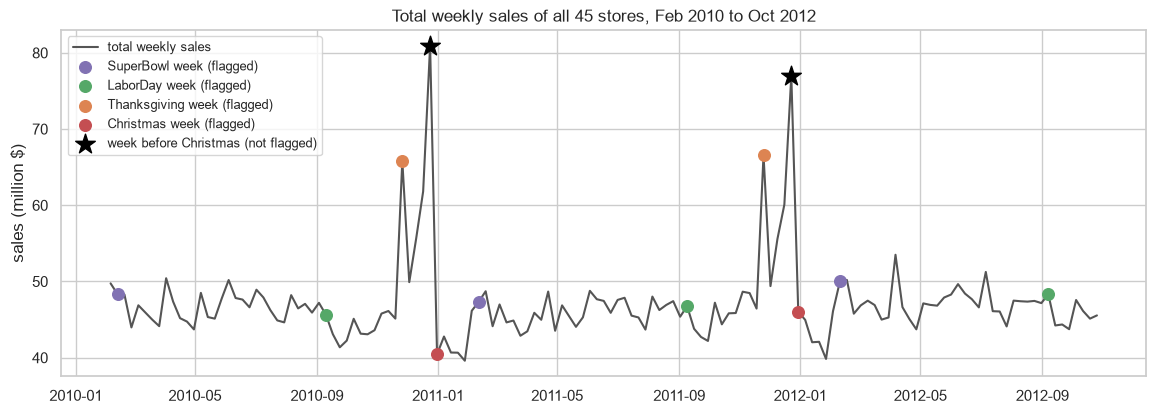

5 biggest weeks (million $): {'2010-12-24': 80.9, '2011-12-23': 77.0, '2011-11-25': 66.6, '2010-11-26': 65.8, '2010-12-17': 61.8}
median week: 46.2M, lowest week: 39.6M (2011-01-28)


In [13]:
# Chart - 1 visualization code
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(weekly_total.index, weekly_total["Sales"] / 1e6, color="#555555", lw=1.5, label="total weekly sales")
for h, color in HOLIDAY_COLORS.items():
    pts = weekly_total[weekly_total["Holiday"] == h]
    ax.scatter(pts.index, pts["Sales"] / 1e6, color=color, s=70, zorder=3, label=f"{h} week (flagged)")
pre = weekly_total[weekly_total["PreChristmas"] == 1]
ax.scatter(pre.index, pre["Sales"] / 1e6, color="black", marker="*", s=220, zorder=3,
           label="week before Christmas (not flagged)")
ax.set_title("Total weekly sales of all 45 stores, Feb 2010 to Oct 2012")
ax.set_ylabel("sales (million $)")
ax.legend(loc="upper left", fontsize=9)
save_fig(fig, "chart01_total_weekly_sales")
plt.show()

top = weekly_total["Sales"].nlargest(5) / 1e6
print("5 biggest weeks (million $):", {d.date().isoformat(): round(v, 1) for d, v in top.items()})
print(f"median week: {weekly_total['Sales'].median() / 1e6:.1f}M, lowest week: {weekly_total['Sales'].min() / 1e6:.1f}M "
      f"({weekly_total['Sales'].idxmin().date()})")

##### 1. Why did you pick the specific chart?

A line over time is the natural first chart for weekly sales. I marked the four holiday weeks and the week before Christmas so the holiday effect can be seen directly on the series.

##### 2. What is/are the insight(s) found from the chart?

Sales are flat most of the year at around 46M $ a week (median 46.2M) and then jump in November and December. The five biggest weeks are all holiday season: 24 Dec 2010 (80.9M), 23 Dec 2011 (77.0M), Thanksgiving 2011 (66.6M), Thanksgiving 2010 (65.8M) and 17 Dec 2010 (61.8M). The flagged Christmas week (the week after Christmas) is actually lower than normal, while the unflagged week before Christmas is the peak. The quietest week is right after the season, 28 Jan 2011 (39.6M).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The busy period is short and very predictable, so stock and staff can be planned weeks ahead for Thanksgiving and the two weeks before Christmas. A negative point is that the holiday flag in the data points at the wrong Christmas week. A model or a plan that trusts the flag would expect a peak in a week that is in fact below normal and miss the real peak, so I added my own PreChristmas flag.

#### Chart - 2 - Sales by week of the year, one line per year (seasonality)

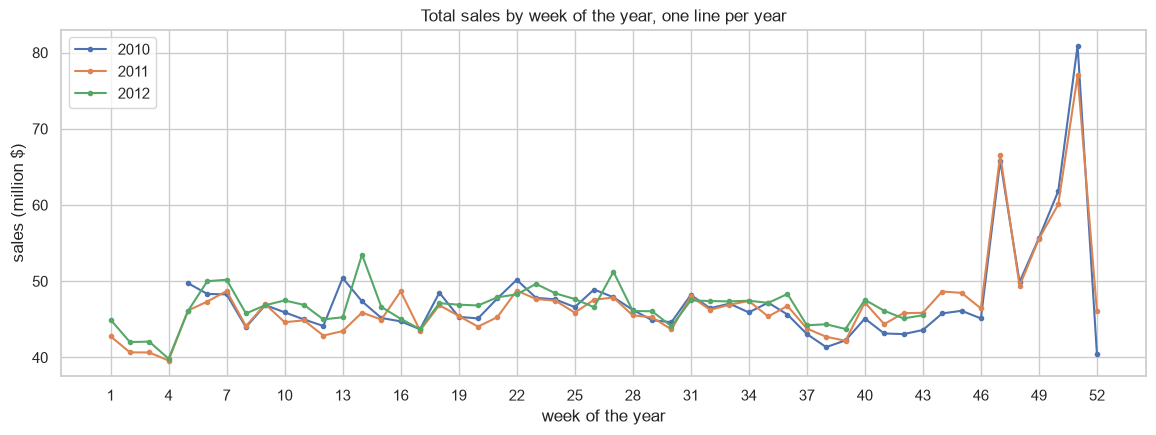

weeks in all 3 years: 5 to 43
average weekly sales in those weeks (million $): {2010: 46.08, 2011: 45.8, 2012: 46.95}
correlation of the weekly pattern between years:
Year  2010  2011  2012
Year                  
2010  1.00  0.61  0.58
2011  0.61  1.00  0.62
2012  0.58  0.62  1.00


In [14]:
# Chart - 2 visualization code
by_week = store_week.groupby(["Year", "Week"])["Sales"].sum().unstack(0) / 1e6
fig, ax = plt.subplots(figsize=(14, 4.5))
for year, color in zip(by_week.columns, ["#4C72B0", "#DD8452", "#55A868"]):
    ax.plot(by_week.index, by_week[year], marker="o", ms=3, lw=1.5, color=color, label=str(year))
ax.set_title("Total sales by week of the year, one line per year")
ax.set_xlabel("week of the year")
ax.set_ylabel("sales (million $)")
ax.set_xticks(range(1, 53, 3))
ax.legend()
save_fig(fig, "chart02_sales_by_week_of_year")
plt.show()

common = by_week.dropna()   # weeks that all three years have (Feb to Oct)
print(f"weeks in all 3 years: {common.index.min()} to {common.index.max()}")
print("average weekly sales in those weeks (million $):", common.mean().round(2).to_dict())
print("correlation of the weekly pattern between years:")
print(common.corr().round(2).to_string())

##### 1. Why did you pick the specific chart?

Putting each year on the same week-of-the-year axis shows whether the seasonal pattern repeats, which decides whether last year's same week is a good guide for this year.

##### 2. What is/are the insight(s) found from the chart?

The three years follow almost the same shape: flat from February to October with small bumps (Super Bowl, Easter, the start of each month), then the November-December peak. Over the weeks all three years have (weeks 5 to 43), the average week was 46.1M in 2010, 45.8M in 2011 and 47.0M in 2012, so there is little growth. The weekly pattern correlates about 0.6 between years, which means the big shape repeats but the smaller week-to-week moves do not always line up.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Because the yearly shape repeats, "same week last year" is a strong input for forecasting, and I used it (Lag52). The 0.6 correlation is also a warning: copying last year week by week would miss shifts like Easter moving from April 2010 to April 2011 in a different week. That would put stock in the wrong week, which is why the forecast also uses the holiday flags and the calendar.

#### Chart - 3 - STL decomposition: trend, seasonality and residual

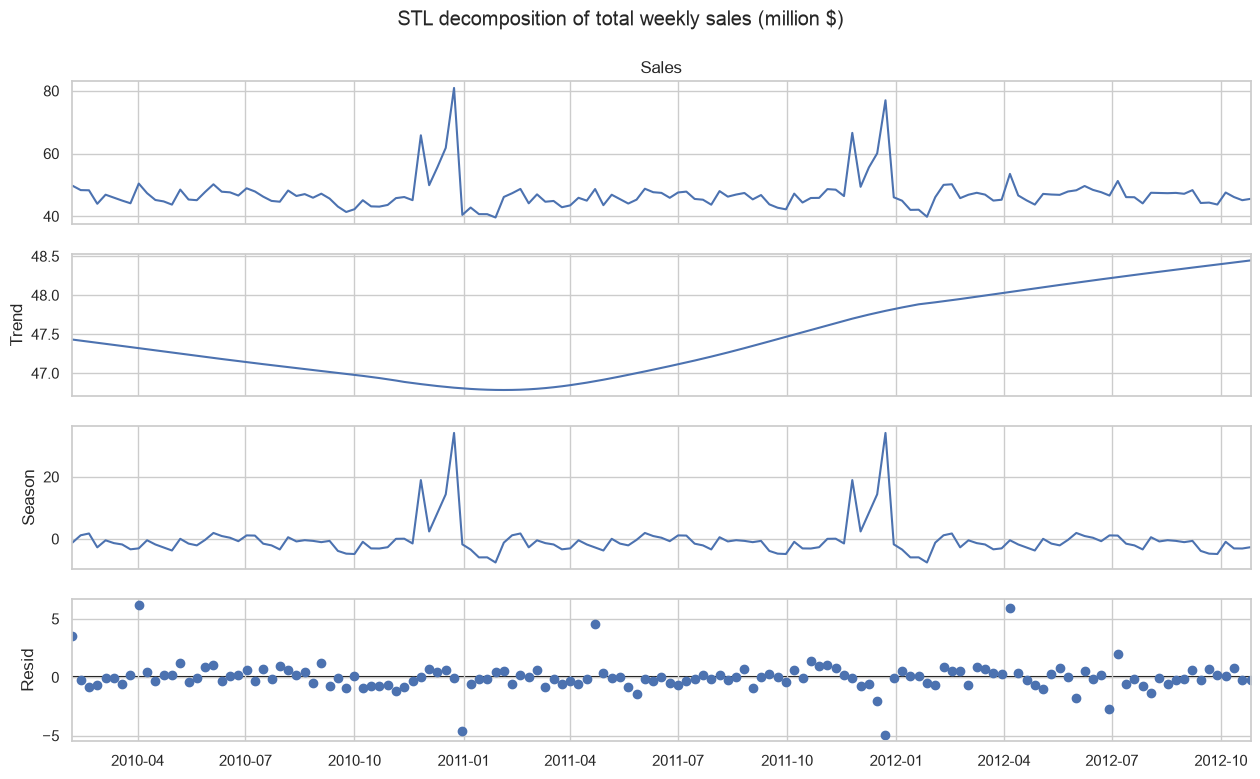

strength of the yearly seasonality: 0.95 (1 = all the week-to-week movement is seasonal)
trend: 47.4M at the start, 46.8M at the lowest, 48.4M at the end
weeks with the largest residuals (not explained by trend + seasonality), million $:
Date
2010-04-02    6.15
2012-04-06    5.89
2011-12-23   -4.94
2010-12-31   -4.62
2011-04-22    4.53


In [15]:
# Chart - 3 visualization code
# With under 3 years of data each week of the year has only 2-3 values. A flat seasonal smoother over a wide window
# (seasonal_deg=0, seasonal=53) makes the seasonal part the average of those years, so the residual shows what was
# different in one particular year. robust=True gives single odd weeks less weight when the trend is fitted.
STL_ARGS = dict(period=52, seasonal=53, seasonal_deg=0, robust=True)
stl_total = STL(weekly_total["Sales"] / 1e6, **STL_ARGS).fit()
fig = stl_total.plot()
fig.set_size_inches(14, 8)
fig.suptitle("STL decomposition of total weekly sales (million $)", y=1.01)
save_fig(fig, "chart03_stl_decomposition")
plt.show()

trend, seas, resid = stl_total.trend, stl_total.seasonal, stl_total.resid
strength = max(0, 1 - resid.var() / (seas + resid).var())
print(f"strength of the yearly seasonality: {strength:.2f} (1 = all the week-to-week movement is seasonal)")
print(f"trend: {trend.iloc[0]:.1f}M at the start, {trend.min():.1f}M at the lowest, {trend.iloc[-1]:.1f}M at the end")
print("weeks with the largest residuals (not explained by trend + seasonality), million $:")
print(resid.loc[resid.abs().sort_values(ascending=False).index[:5]].round(2).to_string())

##### 1. Why did you pick the specific chart?

STL decomposition splits the weekly sales into a slow trend, a yearly seasonal pattern and a residual. The residual is what neither the trend nor the normal yearly pattern can explain, which makes it the right place to look for time-based anomalies.

##### 2. What is/are the insight(s) found from the chart?

The yearly pattern explains most of the movement (seasonal strength 0.95). The trend is almost flat: it dipped from 47.4M to 46.8M a week in early 2011 and then rose to 48.4M by October 2012, only about 3% over almost three years. The biggest residuals are not random:
- Easter: 2 Apr 2010 (+6.2M), 6 Apr 2012 (+5.9M) and 22 Apr 2011 (+4.5M). Easter moves between years, so a fixed 52-week pattern always expects it in the wrong week.
- The Christmas calendar shift: 23 Dec 2011 (-4.9M) and 31 Dec 2010 (-4.6M). In 2010 Christmas Eve was a Friday and fell inside the week before Christmas, while in 2011 it was a Saturday and fell into the Christmas week. So the same "week before Christmas" lost last-minute shopping in 2011.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The main growth story is weak (3% in almost 3 years), so the chain's sales depend on getting the season right more than on growth. The negative insight is that planning by week number fails for moving holidays: an Easter plan copied from last year's week number lands in the wrong week, and the Christmas weeks shift every year. Stock and promotions should follow the holiday calendar, not the week number. That is why I added an Easter flag to the data and to the forecasting features.

#### Chart - 4 - Sales lift in holiday weeks

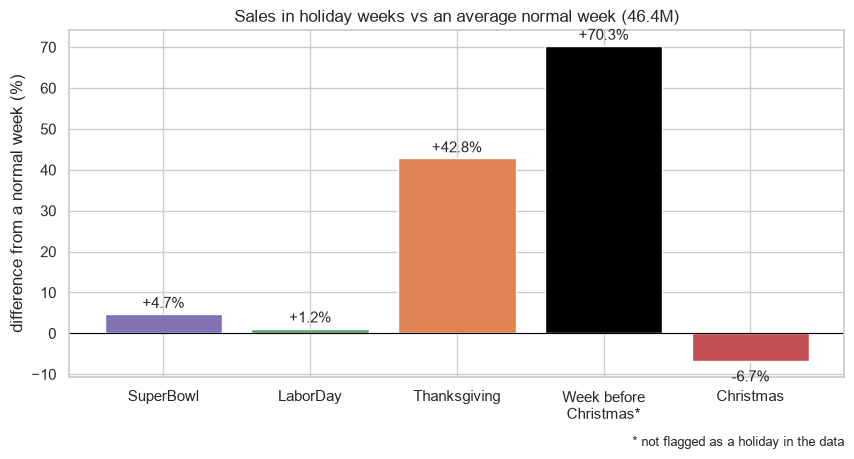

Holiday
SuperBowl                  4.7
LaborDay                   1.2
Thanksgiving              42.8
Week before Christmas*    70.3
Christmas                 -6.7


In [16]:
# Chart - 4 visualization code
normal_week = weekly_total.loc[(weekly_total["IsHoliday"] == 0) & (weekly_total["PreChristmas"] == 0), "Sales"].mean()
lift = weekly_total[weekly_total["Holiday"] != "None"].groupby("Holiday")["Sales"].mean()
lift["Week before\nChristmas*"] = weekly_total.loc[weekly_total["PreChristmas"] == 1, "Sales"].mean()
lift = (lift / normal_week - 1) * 100
lift = lift.reindex(["SuperBowl", "LaborDay", "Thanksgiving", "Week before\nChristmas*", "Christmas"])

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(lift.index, lift.values, color=[HOLIDAY_COLORS.get(h, "black") for h in lift.index])
for b, v in zip(bars, lift.values):
    ax.text(b.get_x() + b.get_width() / 2, v + (1.5 if v >= 0 else -5), f"{v:+.1f}%", ha="center", fontsize=11)
ax.axhline(0, color="black", lw=0.8)
ax.set_title(f"Sales in holiday weeks vs an average normal week ({normal_week / 1e6:.1f}M)")
ax.set_ylabel("difference from a normal week (%)")
ax.text(1, -0.2, "* not flagged as a holiday in the data", transform=ax.transAxes, ha="right", fontsize=9)
save_fig(fig, "chart04_holiday_lift")
plt.show()
print(lift.round(1).rename(lambda s: s.replace("\n", " ")).to_string())

##### 1. Why did you pick the specific chart?

A bar chart of the percentage lift compared with a normal week makes the holidays easy to compare, even though they are very different in size.

##### 2. What is/are the insight(s) found from the chart?

Thanksgiving week sells 42.8% more than an average normal week, and the unflagged week before Christmas sells 70.3% more. The Super Bowl (+4.7%) and Labor Day (+1.2%) barely move sales, even though they are flagged as holidays and count 5 times in the WMAE metric. The flagged Christmas week sells 6.7% less than a normal week because Christmas Day falls in it and shopping is already done.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The chain should treat the holidays very differently: big stock and staff increases for Thanksgiving and the weeks before Christmas, and almost nothing special for the Super Bowl and Labor Day. A negative insight is that over-stocking for the Christmas week itself would leave the shelves full when demand drops, which ties up money and leads to markdowns in January.

#### Chart - 5 - Distribution of weekly sales and the negative-sales weeks

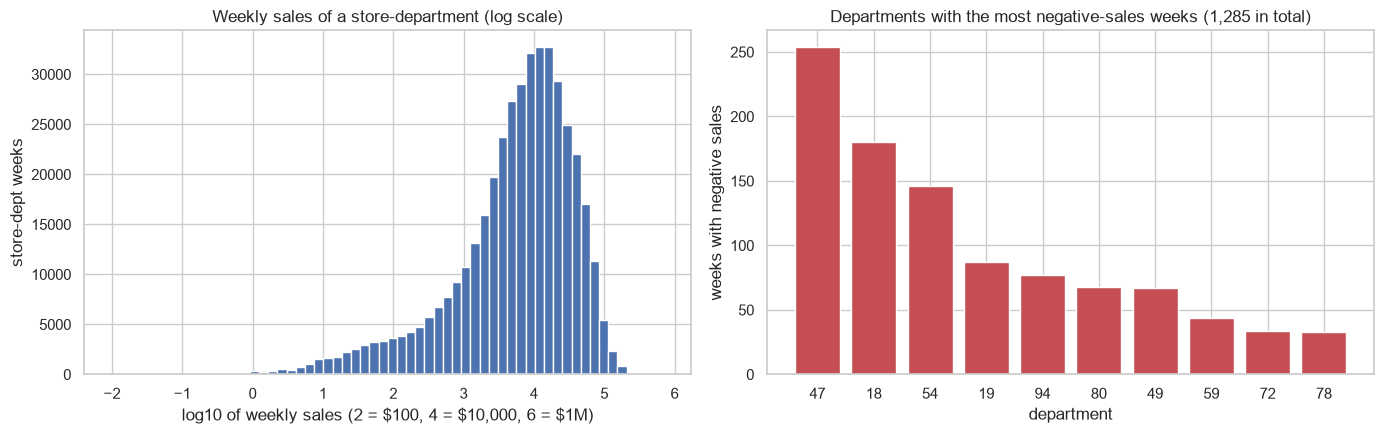

weekly sales: median 7,612, mean 15,981, max 693,099, skewness 3.3
negative weeks: 1,285, adding up to -88,162 $, smallest -4,989 $
share of negative weeks in the top 10 departments above: 77%


In [17]:
# Chart - 5 visualization code
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
positive = df.loc[df["Weekly_Sales"] > 0, "Weekly_Sales"]
axes[0].hist(np.log10(positive), bins=60, color="#4C72B0")
axes[0].set_title("Weekly sales of a store-department (log scale)")
axes[0].set_xlabel("log10 of weekly sales (2 = $100, 4 = $10,000, 6 = $1M)")
axes[0].set_ylabel("store-dept weeks")

neg = df[df["Weekly_Sales"] < 0]
top_neg = neg["Dept"].value_counts().head(10)
axes[1].bar(top_neg.index.astype(str), top_neg.values, color="#C44E52")
axes[1].set_title(f"Departments with the most negative-sales weeks ({len(neg):,} in total)")
axes[1].set_xlabel("department")
axes[1].set_ylabel("weeks with negative sales")
plt.tight_layout()
save_fig(fig, "chart05_sales_distribution_and_returns")
plt.show()

print(f"weekly sales: median {df['Weekly_Sales'].median():,.0f}, mean {df['Weekly_Sales'].mean():,.0f}, "
      f"max {df['Weekly_Sales'].max():,.0f}, skewness {df['Weekly_Sales'].skew():.1f}")
print(f"negative weeks: {len(neg):,}, adding up to {neg['Weekly_Sales'].sum():,.0f} $, smallest {neg['Weekly_Sales'].min():,.0f} $")
print(f"share of negative weeks in the top 10 departments above: {100 * top_neg.sum() / len(neg):.0f}%")

##### 1. Why did you pick the specific chart?

Weekly sales cover five orders of magnitude, so a histogram on a log scale is the only way to see the whole distribution. The bar chart next to it shows where the negative weeks come from.

##### 2. What is/are the insight(s) found from the chart?

The usual store-department week sells between about 1,000 $ and 100,000 $ (median 7,612 $), but the mean (15,981 $) is twice the median and the skewness is 3.3, so a few big departments dominate. There are 1,285 negative weeks adding up to only -88,162 $, and 77% of them come from 10 departments, led by department 47 (254 weeks), 18 (180) and 54 (146). These look like small departments where returns sometimes beat sales.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Because a few large departments make most of the money, forecast errors on those departments matter most, which is why I measure errors in dollars (WMAE) and not in percent. The negative weeks are real returns and not data errors. They are too small to hurt the totals, but a model trained on them would learn that a department can have negative demand, so I set them to 0 for modelling and kept the raw value.

#### Chart - 6 - Time-based anomalies per store (STL residuals)

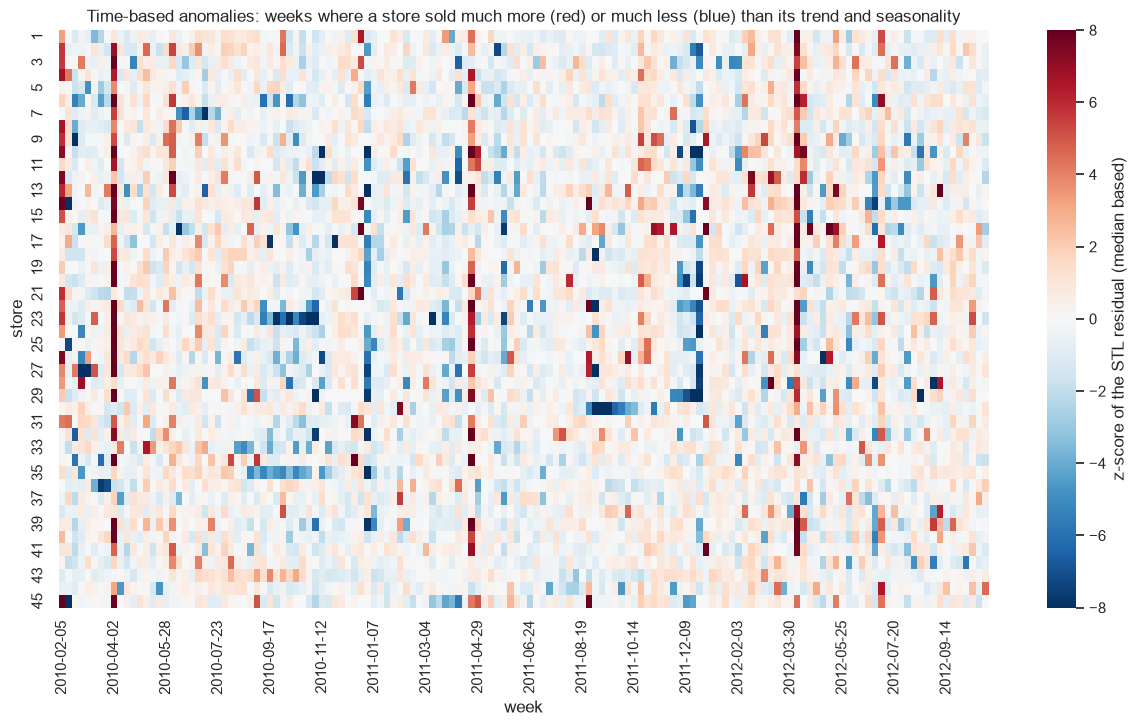

store-weeks with |z| > 4: 476 of 6,435 (7.4%)
weeks where the most stores were anomalous:
            stores  mean_z
Date                      
2012-04-06      32     8.0
2010-04-02      29     8.7
2011-04-22      23     7.3
2010-12-31      19    -6.4
2011-12-23      17    -6.7
2010-02-05      16     6.4
stores with the most anomalous weeks:
Store
23    23
26    19
13    19
28    18
16    18


In [18]:
# Chart - 6 visualization code
# time-based anomaly detection: an STL model for each store, then a median-based z-score of what it could not explain
def median_z(x):
    med = np.median(x)
    mad = np.median(np.abs(x - med)) * 1.4826
    return (x - med) / mad


store_z = {}
for s, g in store_week.groupby("Store"):
    y = g.set_index("Date")["Sales"]
    store_z[s] = median_z(STL(y, **STL_ARGS).fit().resid)
Z = pd.DataFrame(store_z).T   # rows = stores, columns = weeks

fig, ax = plt.subplots(figsize=(15, 7.5))
sns.heatmap(Z.clip(-8, 8), cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "z-score of the STL residual (median based)"},
            xticklabels=[d.strftime("%Y-%m-%d") if i % 8 == 0 else "" for i, d in enumerate(Z.columns)])
ax.set_title("Time-based anomalies: weeks where a store sold much more (red) or much less (blue) than its trend and seasonality")
ax.set_xlabel("week")
ax.set_ylabel("store")
save_fig(fig, "chart06_store_time_anomalies")
plt.show()

time_anoms = Z.stack().rename("z").reset_index()
time_anoms.columns = ["Store", "Date", "z"]
time_anoms = time_anoms[time_anoms["z"].abs() > 4]
print(f"store-weeks with |z| > 4: {len(time_anoms)} of {Z.size:,} ({100 * len(time_anoms) / Z.size:.1f}%)")
print("weeks where the most stores were anomalous:")
print(time_anoms.groupby("Date").agg(stores=("z", "size"), mean_z=("z", "mean")).sort_values("stores", ascending=False).head(6).round(1).to_string())
print("stores with the most anomalous weeks:")
print(time_anoms.groupby("Store").size().sort_values(ascending=False).head(5).to_string())

##### 1. Why did you pick the specific chart?

A heatmap with stores as rows and weeks as columns shows every store-week at once, so it is easy to see whether an anomaly hits one store (local event) or many stores in the same week (calendar or chain-wide event). I used the STL residual of each store and a median-based z-score, so one extreme week does not hide the others.

##### 2. What is/are the insight(s) found from the chart?

476 store-weeks (7.4%) are more than 4 median-based standard deviations from what the store's trend and season predict. The weeks with the most stores out of line are the Easter weeks (6 Apr 2012: 32 stores, 2 Apr 2010: 29, 22 Apr 2011: 23) and the two Christmas shift weeks (31 Dec 2010: 19 stores, 23 Dec 2011: 17). These are chain-wide calendar effects, not errors. The first week of the data also shows up (16 stores), but that is only an edge effect of the decomposition. Some stores have their own anomalies: store 23 has the most (23 weeks), including 7 weeks in a row from 24 Sep to 5 Nov 2010, so its level was really different for a while, which points to a local event such as a refit, road works or a new competitor. Stores 26, 13, 28 and 16 come next.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Separating chain-wide anomalies (calendar) from single-store anomalies (local events) tells the business what to do with each one: the calendar ones go into the planning calendar every year, and the local ones should be checked with the store manager. The negative side is that if these weeks are left in the data as normal weeks, a forecast will copy a one-off event into next year, for example expect a dip at store 23 every October.

#### Chart - 7 - Sales by store type

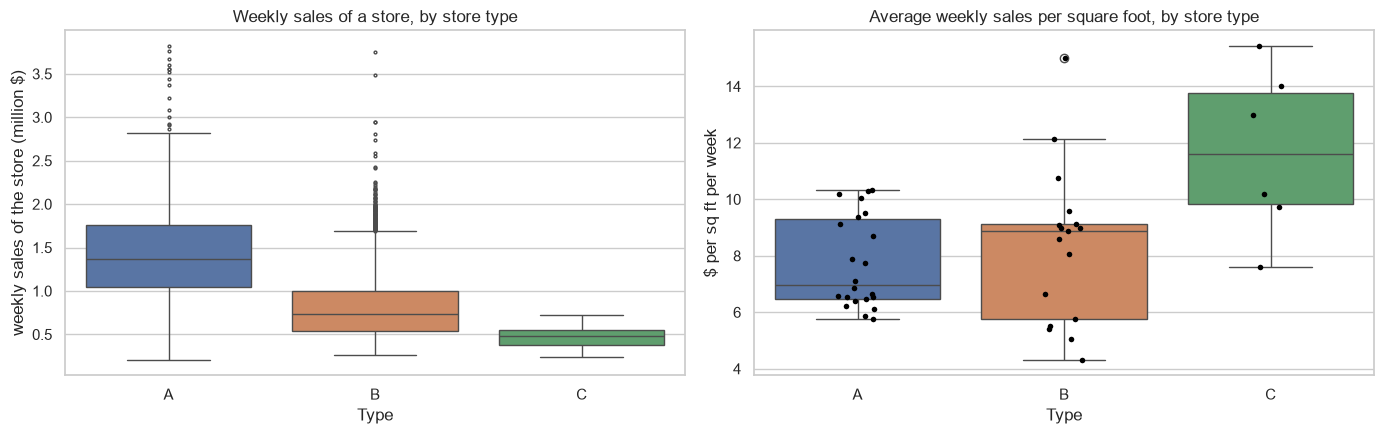

      stores  avg_weekly_sales   avg_size  sales_per_sqft
Type                                                     
A         22        1376673.47  177247.73            7.74
B         17         822994.96  101190.71            8.35
C          6         472614.83   40541.67           11.66


In [19]:
# Chart - 7 visualization code
store_avg = store_week.groupby(["Store", "Type", "Size"], as_index=False)["Sales"].mean()
store_avg["Sales_per_SqFt"] = store_avg["Sales"] / store_avg["Size"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=store_week, x="Type", y="Sales_M", hue="Type", order=["A", "B", "C"], palette=TYPE_COLORS,
            legend=False, ax=axes[0], fliersize=2)
axes[0].set_title("Weekly sales of a store, by store type")
axes[0].set_ylabel("weekly sales of the store (million $)")
sns.boxplot(data=store_avg, x="Type", y="Sales_per_SqFt", hue="Type", order=["A", "B", "C"], palette=TYPE_COLORS,
            legend=False, ax=axes[1])
sns.stripplot(data=store_avg, x="Type", y="Sales_per_SqFt", order=["A", "B", "C"], color="black", size=4, ax=axes[1])
axes[1].set_title("Average weekly sales per square foot, by store type")
axes[1].set_ylabel("$ per sq ft per week")
plt.tight_layout()
save_fig(fig, "chart07_sales_by_store_type")
plt.show()

print(store_avg.groupby("Type").agg(stores=("Store", "count"), avg_weekly_sales=("Sales", "mean"),
                                    avg_size=("Size", "mean"), sales_per_sqft=("Sales_per_SqFt", "mean")).round(2).to_string())

##### 1. Why did you pick the specific chart?

Box plots compare the spread of weekly store sales between the three store types, and sales per square foot shows how well each type uses its space.

##### 2. What is/are the insight(s) found from the chart?

Type A stores are the biggest (177k sq ft on average) and sell the most (1.38M $ a week), then B (101k sq ft, 0.82M $) and C (41k sq ft, 0.47M $). Per square foot the order flips: C stores sell 11.66 $ per sq ft per week, B 8.35 $ and A 7.74 $. Type B has the widest spread of the three.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Small type C stores turn their space into sales best, so the chain could open smaller formats in suitable areas or use the C layout ideas in big stores. The negative side is that the biggest A stores have the lowest sales per square foot, which may mean some of their space is under-used (slow departments or too much floor space for the traffic).

#### Chart - 8 - Store size vs average weekly sales

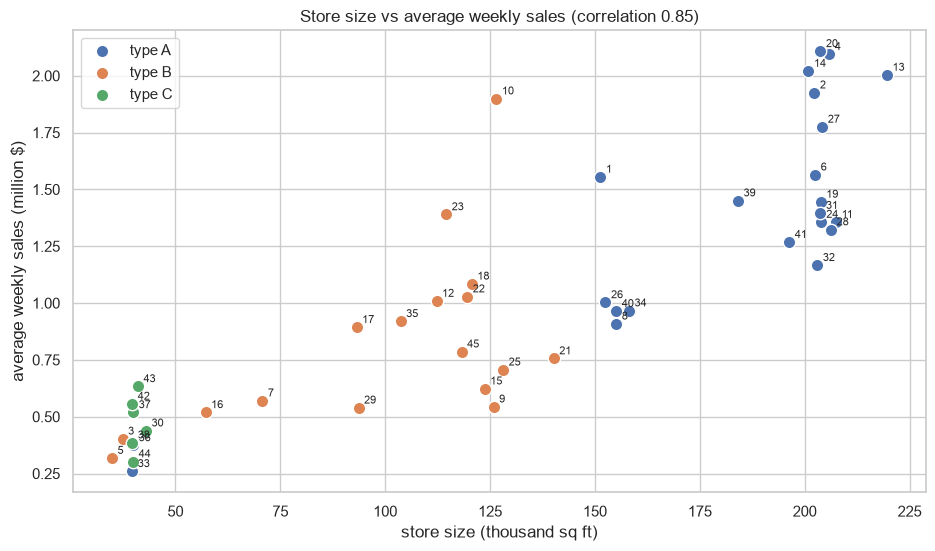

stores whose type does not match their size:
 Store Type  Size    Sales  Sales_per_SqFt
    33    A 39690 259862.0             7.0
    36    A 39910 373512.0             9.0


In [20]:
# Chart - 8 visualization code
fig, ax = plt.subplots(figsize=(11, 6))
for t, g in store_avg.groupby("Type"):
    ax.scatter(g["Size"] / 1000, g["Sales"] / 1e6, s=80, color=TYPE_COLORS[t], label=f"type {t}", edgecolor="white")
for _, r in store_avg.iterrows():
    ax.annotate(int(r["Store"]), (r["Size"] / 1000, r["Sales"] / 1e6), fontsize=8, xytext=(4, 3), textcoords="offset points")
corr_size = store_avg["Size"].corr(store_avg["Sales"])
ax.set_title(f"Store size vs average weekly sales (correlation {corr_size:.2f})")
ax.set_xlabel("store size (thousand sq ft)")
ax.set_ylabel("average weekly sales (million $)")
ax.legend()
save_fig(fig, "chart08_size_vs_sales")
plt.show()

# stores whose type does not match their size
odd = store_avg[((store_avg["Type"] == "A") & (store_avg["Size"] < 100_000)) |
                ((store_avg["Type"] != "A") & (store_avg["Size"] > 150_000))]
print("stores whose type does not match their size:")
print(odd.round(0).to_string(index=False))

##### 1. Why did you pick the specific chart?

A scatter plot shows the relationship between two numbers for every store, and colouring by type shows if the type is just a size label.

##### 2. What is/are the insight(s) found from the chart?

Size explains most of the difference between stores: the correlation between store size and average weekly sales is 0.85. The store type mostly follows size, but not always. Stores 33 and 36 are type A but only about 40k sq ft, the size of a C store, and they sell like small stores (0.26M and 0.37M $ a week). So the type is not only about size.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Store size is the first thing to use for planning budgets and stock across stores. Because a few stores do not match their type, plans should be based on the measured size and sales pattern instead of the type letter alone, and this is also why I later built my own store segments.

#### Chart - 9 - Top 20 departments by sales

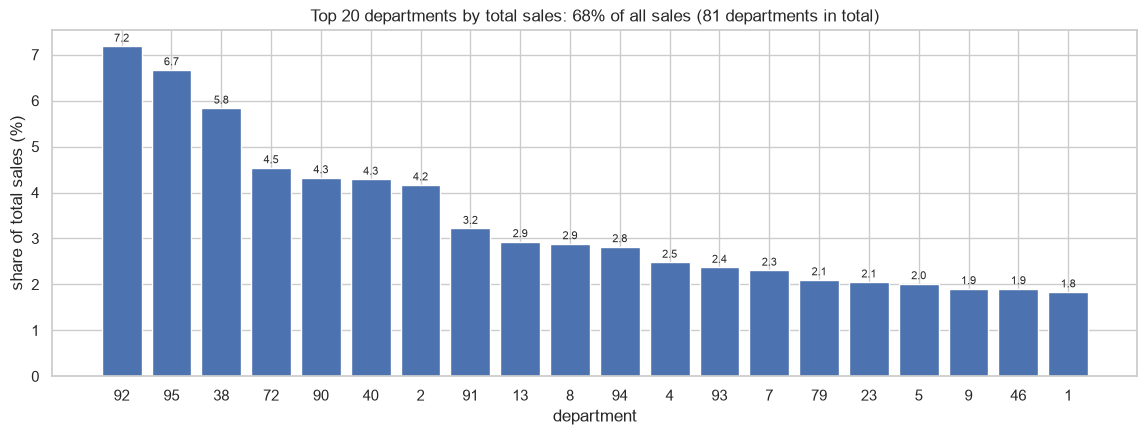

departments needed for 50% of sales: 12, for 80%: 29
stores selling each department: median 45 of 45


In [21]:
# Chart - 9 visualization code
dept_total = df.groupby("Dept")["Weekly_Sales"].sum().sort_values(ascending=False)
dept_share = 100 * dept_total / dept_total.sum()
top20 = dept_share.head(20)

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(top20.index.astype(str), top20.values, color="#4C72B0")
for i, v in enumerate(top20.values):
    ax.text(i, v + 0.1, f"{v:.1f}", ha="center", fontsize=8)
ax.set_title(f"Top 20 departments by total sales: {top20.sum():.0f}% of all sales ({df['Dept'].nunique()} departments in total)")
ax.set_xlabel("department")
ax.set_ylabel("share of total sales (%)")
save_fig(fig, "chart09_top_departments")
plt.show()

cum = dept_share.cumsum()
print(f"departments needed for 50% of sales: {(cum < 50).sum() + 1}, for 80%: {(cum < 80).sum() + 1}")
print(f"stores selling each department: median {df.groupby('Dept')['Store'].nunique().median():.0f} of 45")

##### 1. Why did you pick the specific chart?

A bar chart of the sales share of the top departments shows how concentrated the business is.

##### 2. What is/are the insight(s) found from the chart?

Sales are concentrated in a few departments. Department 92 alone makes 7.2% of all sales, then 95 (6.7%), 38 (5.8%), 72 (4.5%), 90, 40 and 2 (about 4.3% each). The top 20 departments make 68% of sales, 12 departments make half and 29 make 80%. Most departments are sold in all 45 stores (median 45).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Inventory and forecasting effort should go first to the 29 departments that make 80% of sales. Running out of stock in department 92 or 95 costs far more than in a small department. A negative point is that the long tail of 50 small departments still needs shelf space and stock, and forecasting them is harder because their sales are small and noisy.

#### Chart - 10 - Department seasonality by month

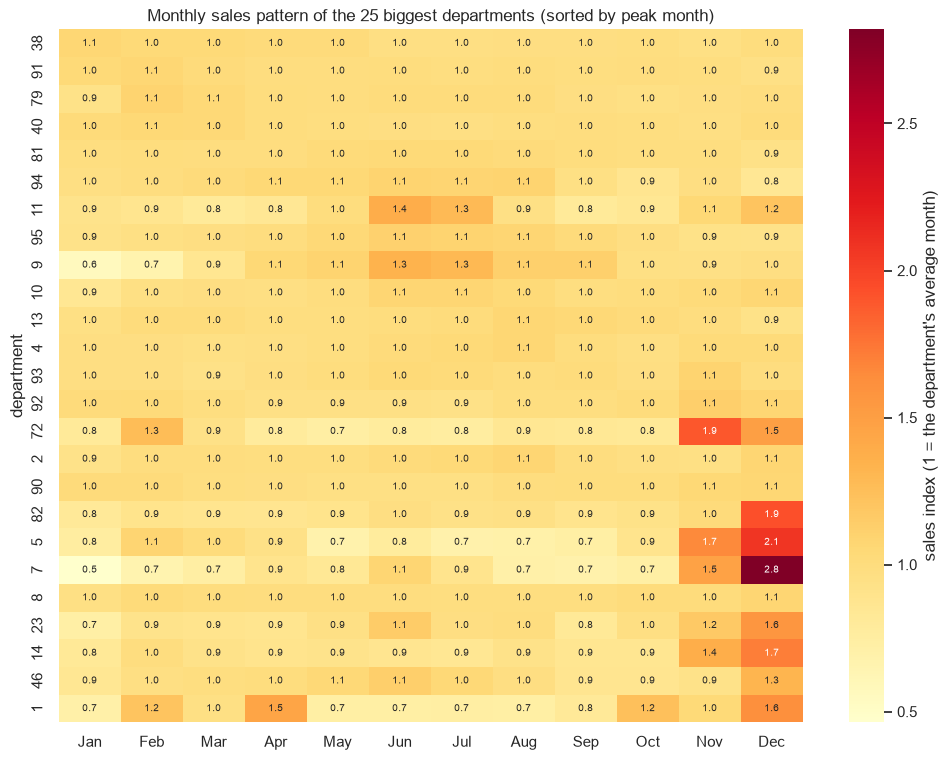

most seasonal of the top 25 (best month / worst month): {7: 6.1, 5: 3.1, 72: 2.6, 9: 2.4, 82: 2.4, 1: 2.3}
least seasonal: {38: 1.11, 90: 1.11, 81: 1.11, 40: 1.1}
peak month of each department: {38: 1, 91: 2, 79: 2, 40: 2, 81: 6, 94: 6, 11: 6, 95: 6, 9: 6, 10: 7, 13: 8, 4: 8, 93: 11, 92: 11, 72: 11, 2: 12, 90: 12, 82: 12, 5: 12, 7: 12, 8: 12, 23: 12, 14: 12, 46: 12, 1: 12}


In [22]:
# Chart - 10 visualization code
top25 = dept_total.head(25).index
dept_month = df[df["Dept"].isin(top25)].groupby(["Dept", "Month"])["Weekly_Sales"].mean().unstack()
month_index = dept_month.div(dept_month.mean(axis=1), axis=0)    # 1.0 = the department's average month
order = month_index.idxmax(axis=1).sort_values().index           # sorted by the month of the peak

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(month_index.loc[order], cmap="YlOrRd", annot=True, fmt=".1f", annot_kws={"fontsize": 7}, ax=ax,
            cbar_kws={"label": "sales index (1 = the department's average month)"})
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Monthly sales pattern of the 25 biggest departments (sorted by peak month)")
ax.set_xlabel("")
ax.set_ylabel("department")
save_fig(fig, "chart10_department_seasonality")
plt.show()

swing = (dept_month.max(axis=1) / dept_month.min(axis=1)).sort_values(ascending=False)
print("most seasonal of the top 25 (best month / worst month):", swing.head(6).round(1).to_dict())
print("least seasonal:", swing.tail(4).round(2).to_dict())
print("peak month of each department:", month_index.idxmax(axis=1).loc[order].to_dict())

##### 1. Why did you pick the specific chart?

A heatmap of each department's sales by month, divided by its own average, shows the seasonal pattern of many departments at once and makes them comparable.

##### 2. What is/are the insight(s) found from the chart?

Most big departments peak in December, but not all. Department 7 sells 6.1 times more in its best month than in its worst, department 5 3.1 times and department 72 2.6 times, so these are strongly seasonal (holiday type products). Other departments have different peaks: 38 in January, 91, 79 and 40 in February, 81, 94, 11, 95 and 9 in June, 10 in July, 13 and 4 in August (back to school), and 93, 92 and 72 in November. Departments 38, 90, 81 and 40 hardly change (best month only about 10% above the worst), so they behave like everyday necessities.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Each department needs its own stock calendar: build up department 7, 5 and 72 for November-December, 13 and 4 for August, and keep a steady supply for the flat departments. A negative risk is stocking everything for December. Departments that peak in other months would then be short at their own peak and over-stocked in December.

#### Chart - 11 - Markdowns over time

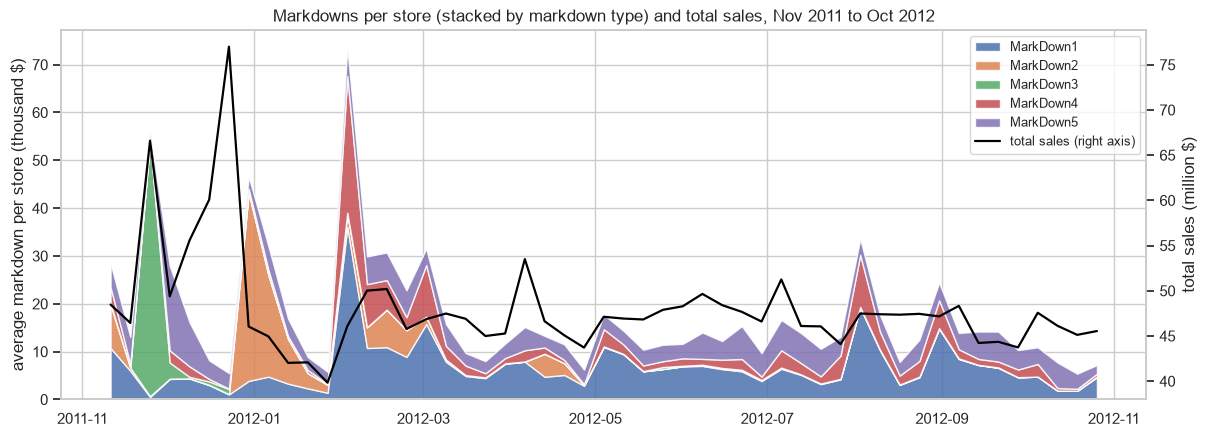

MarkDown1: average   6.8k per store-week, peak week 2012-02-03 (36.1k)
MarkDown2: average   2.3k per store-week, peak week 2011-12-30 (39.4k)
MarkDown3: average   1.2k per store-week, peak week 2011-11-25 (53.3k)
MarkDown4: average   2.8k per store-week, peak week 2012-02-03 (28.6k)
MarkDown5: average   4.4k per store-week, peak week 2011-12-02 (17.7k)


In [23]:
# Chart - 11 visualization code
md_week = (store_week[store_week["Date"] >= MD_START].fillna({c: 0 for c in MARKDOWN_COLS})
           .groupby("Date")[MARKDOWN_COLS].mean() / 1000)
sales_md = weekly_total.loc[weekly_total.index >= MD_START, "Sales"] / 1e6

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.stackplot(md_week.index, md_week.T.values, labels=MARKDOWN_COLS, alpha=0.85)
ax.set_ylabel("average markdown per store (thousand $)")
ax2 = ax.twinx()
ax2.plot(sales_md.index, sales_md.values, color="black", lw=1.6, label="total sales (right axis)")
ax2.set_ylabel("total sales (million $)")
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9)
ax.set_title("Markdowns per store (stacked by markdown type) and total sales, Nov 2011 to Oct 2012")
save_fig(fig, "chart11_markdowns_over_time")
plt.show()

for c in MARKDOWN_COLS:
    print(f"{c}: average {md_week[c].mean():5.1f}k per store-week, peak week {md_week[c].idxmax().date()} ({md_week[c].max():.1f}k)")

##### 1. Why did you pick the specific chart?

A stacked area chart shows how the five markdown types add up week by week, and the sales line on the second axis shows if markdowns line up with busy weeks.

##### 2. What is/are the insight(s) found from the chart?

Markdowns are timed around the holidays and each type has its own moment. MarkDown3 is used almost only at Thanksgiving (peak 53.3k $ per store on 25 Nov 2011), MarkDown2 peaks in the Christmas week (39.4k $ on 30 Dec 2011), and MarkDown1 and MarkDown4 peak in the Super Bowl period (36.1k $ and 28.6k $ on 3 Feb 2012). MarkDown1 is the biggest type on average (6.8k $ per store-week) and MarkDown5 the steadiest. In normal weeks the markdowns are small.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, it shows how the chain uses each markdown type, which is the starting point for planning promotions. It also shows a risk: since markdowns are concentrated in weeks that are busy anyway, a simple comparison would credit markdowns with sales that the holiday would have brought in by itself. That is why the next chart compares growth instead of raw sales.

#### Chart - 12 - Do markdown weeks grow faster? (markdowns vs year-over-year growth)

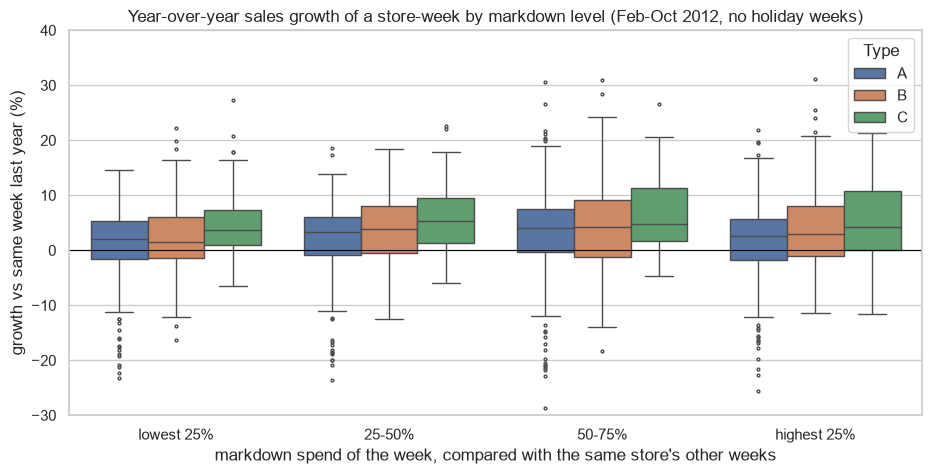

MD_Level
lowest 25%     2.19
25-50%         3.85
50-75%         4.26
highest 25%    2.74
Spearman correlation between markdown rank and growth: 0.051 (p = 0.0362)


In [24]:
# Chart - 12 visualization code
# Markdown weeks also tend to be busy weeks (holidays), so comparing sales directly is unfair.
# Instead: growth against the same week a year before, and markdown level compared within the same store.
sw_md = store_week.fillna({c: 0 for c in MARKDOWN_COLS})
sw_md["MarkDown_Total"] = sw_md[MARKDOWN_COLS].sum(axis=1)
last_year = sw_md[["Store", "Date", "Sales"]].copy()
last_year["Date"] = last_year["Date"] + pd.Timedelta(weeks=52)
sw_md = sw_md.merge(last_year.rename(columns={"Sales": "Sales_LY"}), on=["Store", "Date"], how="left")

# Feb-Oct 2012: markdowns are recorded and the same week a year earlier exists; holiday weeks left out
md_period = sw_md[(sw_md["Date"] >= "2012-02-03") & (sw_md["IsHoliday"] == 0)].copy()
md_period["YoY_Growth"] = 100 * (md_period["Sales"] / md_period["Sales_LY"] - 1)
md_period["MD_Rank"] = md_period.groupby("Store")["MarkDown_Total"].rank(pct=True)
md_period["MD_Level"] = pd.cut(md_period["MD_Rank"], [0, 0.25, 0.5, 0.75, 1],
                               labels=["lowest 25%", "25-50%", "50-75%", "highest 25%"])

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=md_period, x="MD_Level", y="YoY_Growth", hue="Type", hue_order=["A", "B", "C"],
            palette=TYPE_COLORS, fliersize=2, ax=ax)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(-30, 40)
ax.set_title("Year-over-year sales growth of a store-week by markdown level (Feb-Oct 2012, no holiday weeks)")
ax.set_xlabel("markdown spend of the week, compared with the same store's other weeks")
ax.set_ylabel("growth vs same week last year (%)")
save_fig(fig, "chart12_markdowns_vs_growth")
plt.show()

print(md_period.groupby("MD_Level", observed=True)["YoY_Growth"].median().round(2).to_string())
rho, p = stats.spearmanr(md_period["MD_Rank"], md_period["YoY_Growth"], nan_policy="omit")
print(f"Spearman correlation between markdown rank and growth: {rho:.3f} (p = {p:.3g})")

##### 1. Why did you pick the specific chart?

To see the markdown effect without the holiday effect, I compared each store-week with the same week a year earlier (year-over-year growth) and grouped the weeks by how big the markdown was compared with the same store's other weeks. A box plot shows the whole spread for each group and store type.

##### 2. What is/are the insight(s) found from the chart?

The effect of markdowns is small. In normal weeks of Feb-Oct 2012, the median growth was 2.2% in the store's lowest markdown weeks, 3.9% and 4.3% in the middle groups and 2.7% in the highest markdown weeks. The Spearman correlation between markdown level and growth is only 0.05 (significant, p = 0.036, because there are many weeks, but tiny). Medium markdowns go with a bit more growth, and the biggest markdowns do not add more.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, and it is an important negative insight: bigger markdowns did not bring proportionally more sales growth, so part of the markdown money is probably spent on sales that would have happened anyway. The chain could test smaller, better targeted markdowns. Markdowns are not random experiments in this data, so this is a correlation and not a proof, but it is a good reason to test.

#### Chart - 13 - External factors over time by store type

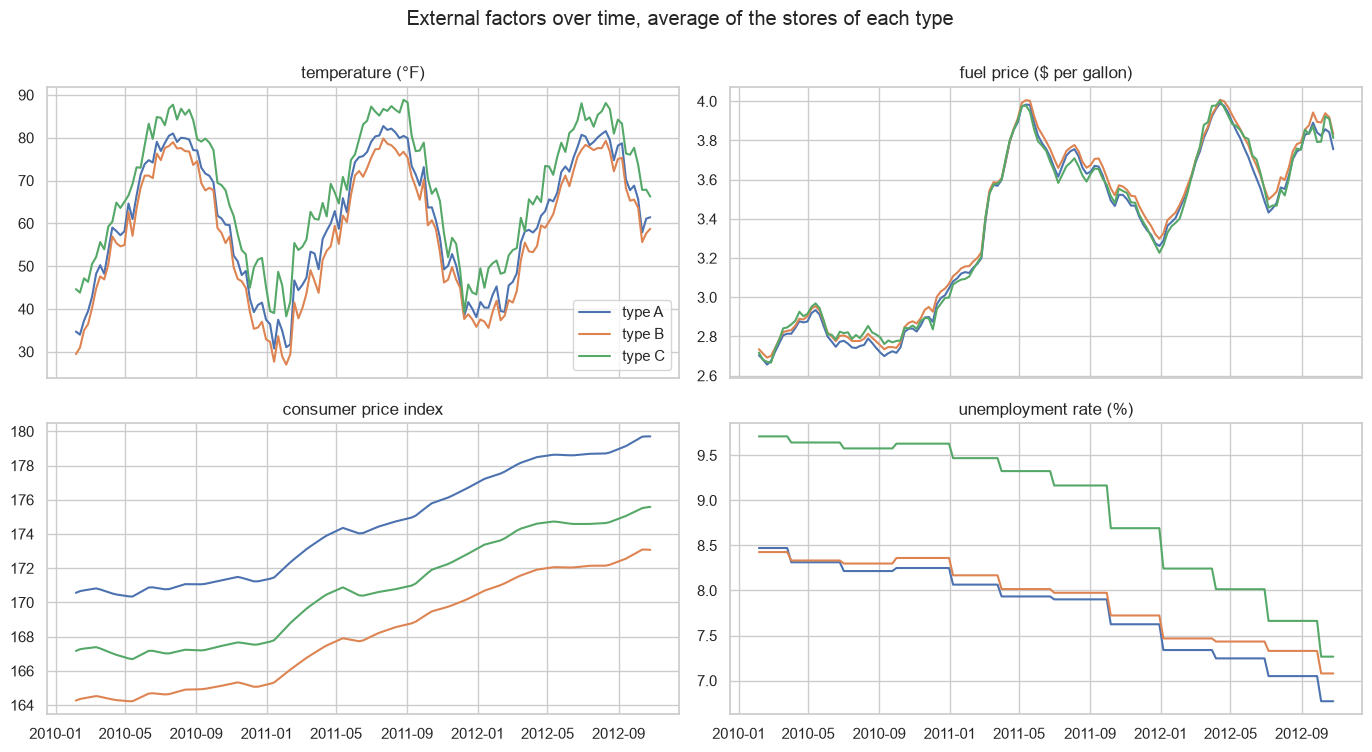

stores with average CPI under 150: 22, over 180: 23 (two price regions)
unemployment change Feb 2010 -> Oct 2012: median -1.46 points, stores where it went up: 1
fuel price: 2.72 -> 3.79 $, CPI: 167.7 -> 176.6


In [25]:
# Chart - 13 visualization code
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True)
labels = {"Temperature": "temperature (°F)", "Fuel_Price": "fuel price ($ per gallon)",
          "CPI": "consumer price index", "Unemployment": "unemployment rate (%)"}
for ax, (col, label) in zip(axes.flat, labels.items()):
    for t, g in store_week.groupby("Type"):
        s = g.groupby("Date")[col].mean()
        ax.plot(s.index, s.values, color=TYPE_COLORS[t], label=f"type {t}")
    ax.set_title(label)
axes[0, 0].legend()
fig.suptitle("External factors over time, average of the stores of each type", y=1.0)
plt.tight_layout()
save_fig(fig, "chart13_external_factors")
plt.show()

cpi_store = store_week.groupby("Store")["CPI"].mean()
print(f"stores with average CPI under 150: {(cpi_store < 150).sum()}, over 180: {(cpi_store > 180).sum()} (two price regions)")
first = store_week[store_week["Date"] == store_week["Date"].min()].set_index("Store")
last = store_week[store_week["Date"] == store_week["Date"].max()].set_index("Store")
print(f"unemployment change Feb 2010 -> Oct 2012: median {(last['Unemployment'] - first['Unemployment']).median():+.2f} points, "
      f"stores where it went up: {((last['Unemployment'] - first['Unemployment']) > 0).sum()}")
print(f"fuel price: {first['Fuel_Price'].mean():.2f} -> {last['Fuel_Price'].mean():.2f} $, "
      f"CPI: {first['CPI'].mean():.1f} -> {last['CPI'].mean():.1f}")

##### 1. Why did you pick the specific chart?

Four small line charts show how each external factor changed over time for each store type, so trends and differences between regions are easy to see.

##### 2. What is/are the insight(s) found from the chart?

Temperature follows the seasons (C stores are in warmer regions). Fuel prices rose from 2.72 $ to 3.79 $ a gallon between Feb 2010 and Oct 2012. CPI rose slowly everywhere, but the stores sit in two price regions: 22 stores have an average CPI under 150 and 23 above 180. Unemployment went down in all but one store, by a median of 1.46 points. None of these factors has a December peak like sales do.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The two CPI regions are a real regional difference that I used later in the store segmentation. Falling unemployment and rising fuel prices are slow trends, so they can only explain slow changes in sales, not the weekly ups and downs. The negative side is that sales hardly grew while unemployment fell, so the economy alone is not a strong lever for this chain.

#### Chart - 14 - Correlation Heatmap

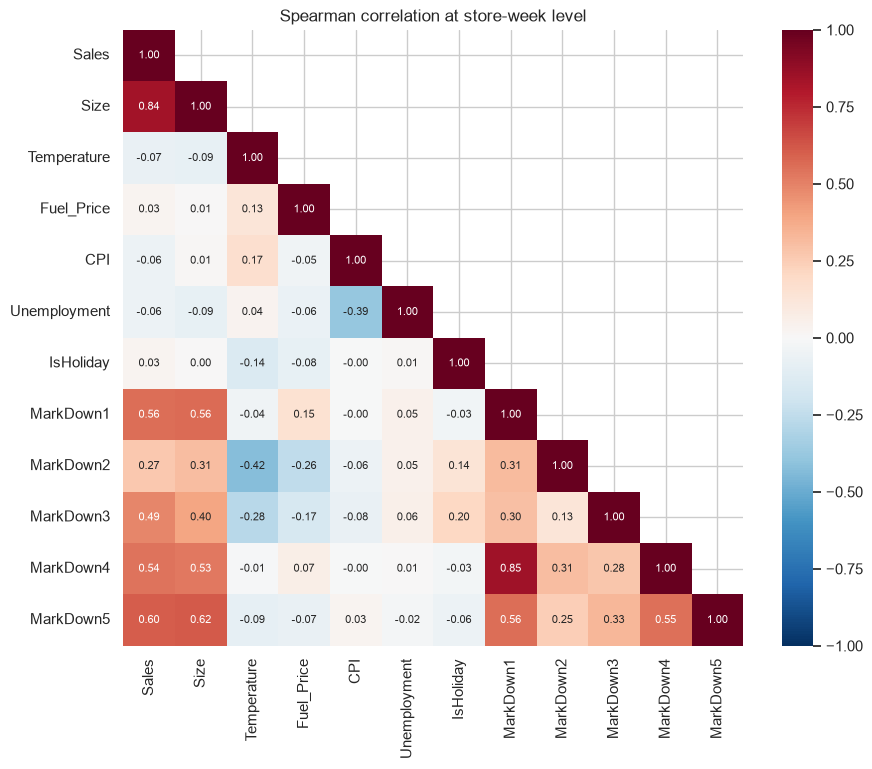

correlation of each variable with store sales:
Size            0.84
MarkDown5       0.60
MarkDown1       0.56
MarkDown4       0.54
MarkDown3       0.49
MarkDown2       0.27
Temperature    -0.07
Unemployment   -0.06
CPI            -0.06
IsHoliday       0.03
Fuel_Price      0.03


In [26]:
# Correlation Heatmap visualization code
# store-week level; markdowns only from the weeks they were recorded (0 = no markdown that week)
cw = store_week.copy()
recorded = cw["Date"] >= MD_START
cw.loc[recorded, MARKDOWN_COLS] = cw.loc[recorded, MARKDOWN_COLS].fillna(0)
corr_cols = ["Sales", "Size", "Temperature", "Fuel_Price", "CPI", "Unemployment", "IsHoliday"] + MARKDOWN_COLS
corr = cw[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"fontsize": 8})
ax.set_title("Spearman correlation at store-week level")
save_fig(fig, "chart14_correlation_heatmap")
plt.show()
print("correlation of each variable with store sales:")
print(corr["Sales"].drop("Sales").sort_values(key=abs, ascending=False).round(2).to_string())

##### 1. Why did you pick the specific chart?

A correlation heatmap shows all pairwise relationships at once. I used Spearman correlation because sales and markdowns are very skewed, and I calculated it at store-week level so store size and regional factors line up with the sales they belong to.

##### 2. What is/are the insight(s) found from the chart?

Store sales are most correlated with store size (0.84). The markdown columns also correlate with sales (0.27 to 0.60), but that is mostly a size effect, since bigger stores also run bigger markdowns. Temperature, unemployment, CPI and fuel price are almost uncorrelated with sales at this level (between -0.07 and 0.03), and so is the holiday flag, because the four holiday weeks are few and two of them barely change sales. Several markdown types are correlated with each other because they run in the same weeks.

#### Chart - 15 - Pair Plot

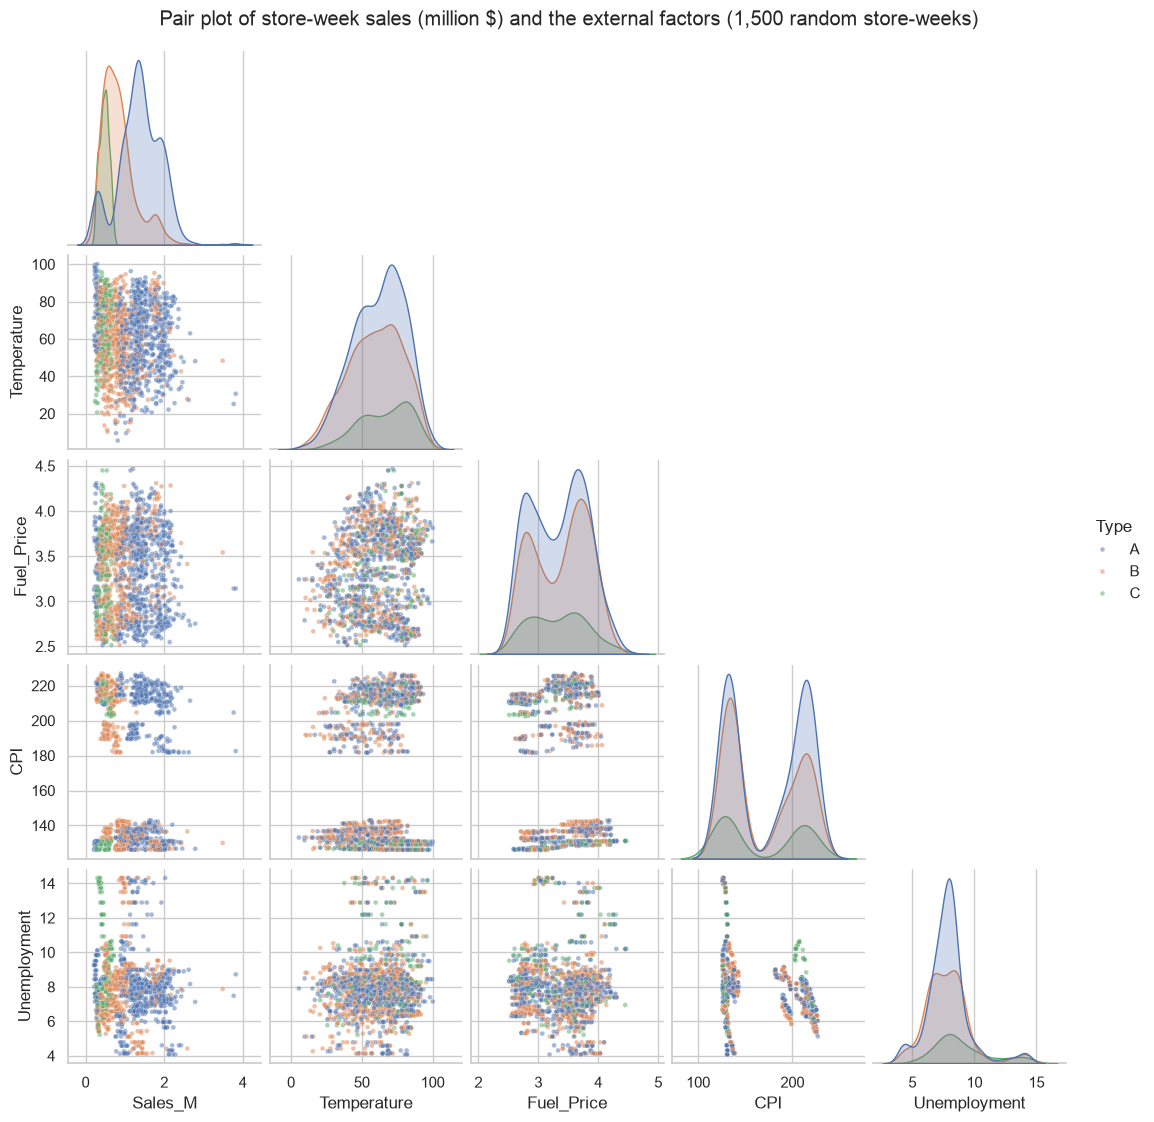

In [27]:
# Pair Plot visualization code
sample = store_week.sample(1500, random_state=SEED)
g = sns.pairplot(sample[["Sales_M", "Temperature", "Fuel_Price", "CPI", "Unemployment", "Type"]],
                 hue="Type", hue_order=["A", "B", "C"], palette=TYPE_COLORS, corner=True, height=2.2,
                 plot_kws={"s": 12, "alpha": 0.5})
g.fig.suptitle("Pair plot of store-week sales (million $) and the external factors (1,500 random store-weeks)", y=1.02)
save_fig(g.fig, "chart15_pair_plot")
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows the distribution of each variable and every pair of variables in one figure, so non-linear relationships and groups (here the store types) become visible. I used 1,500 random store-weeks to keep it readable.

##### 2. What is/are the insight(s) found from the chart?

Sales are clearly separated by store type (A highest, C lowest) but show no clear trend against temperature, fuel price, CPI or unemployment. CPI splits into two groups, the two price regions, and unemployment is mostly between 5% and 10% with a few high-unemployment stores. Fuel price and CPI both drift up over time, so they are correlated with each other. These plots confirm that the external factors explain little of the weekly variation on their own.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

From the charts I picked three statements to test formally:
1. Holiday weeks have higher sales than normal weeks (charts 1 and 4).
2. Sales per square foot is different between store types A, B and C (chart 7).
3. Stores in regions with higher unemployment sell less per square foot (charts 13 and 14).

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null hypothesis (H0): for a store, average sales in holiday weeks are not higher than in normal weeks.
- Alternative hypothesis (H1): a store's average sales are higher in holiday weeks than in normal weeks.

#### 2. Perform an appropriate statistical test.

In [28]:
# Perform Statistical Test to obtain P-Value
# each store's average weekly sales in holiday weeks vs in normal weeks (paired by store)
per_store = store_week.groupby(["Store", "IsHoliday"])["Sales"].mean().unstack()
per_store.columns = ["normal_week", "holiday_week"]
diff = per_store["holiday_week"] - per_store["normal_week"]
stat, p = stats.wilcoxon(per_store["holiday_week"], per_store["normal_week"], alternative="greater")
print(f"stores where the holiday-week average is higher: {(diff > 0).sum()} of {len(diff)}")
print(f"median difference: {diff.median():,.0f} $ per week "
      f"({100 * (per_store['holiday_week'] / per_store['normal_week'] - 1).median():.1f}%)")
print(f"Wilcoxon signed-rank test (one-sided): W = {stat:.1f}, p-value = {p:.2e}")
print("-> reject H0" if p < 0.05 else "-> fail to reject H0", "at the 5% level")

stores where the holiday-week average is higher: 40 of 45
median difference: 78,142 $ per week (7.7%)
Wilcoxon signed-rank test (one-sided): W = 1011.0, p-value = 2.17e-11
-> reject H0 at the 5% level


##### Which statistical test have you done to obtain P-Value?

Wilcoxon signed-rank test (one-sided), on the 45 pairs of store averages. W = 1011, p-value = 2.2e-11, so H0 is rejected: 40 of the 45 stores sell more in holiday weeks, by a median of 78,142 $ per week (7.7%).

##### Why did you choose the specific statistical test?

The data is paired: each store has a holiday average and a normal-week average, and comparing within the store removes the big size differences between stores. The differences are not normally distributed (a few big stores have huge differences), so the Wilcoxon signed-rank test is safer than a paired t-test because it only uses the ranks of the differences.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null hypothesis (H0): sales per square foot have the same distribution in type A, B and C stores.
- Alternative hypothesis (H1): at least one store type has different sales per square foot.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value
# sales per square foot of the 45 stores, compared between store types A, B and C
groups = [store_avg.loc[store_avg["Type"] == t, "Sales_per_SqFt"] for t in ["A", "B", "C"]]
stat, p = stats.kruskal(*groups)
print(store_avg.groupby("Type")["Sales_per_SqFt"].agg(["count", "median", "mean", "std"]).round(2).to_string())
print(f"\nKruskal-Wallis H = {stat:.2f}, p-value = {p:.4f}")
print("-> reject H0" if p < 0.05 else "-> fail to reject H0", "at the 5% level")

      count  median   mean   std
Type                            
A        22    6.97   7.74  1.63
B        17    8.87   8.35  2.76
C         6   11.60  11.66  2.97

Kruskal-Wallis H = 7.61, p-value = 0.0223
-> reject H0 at the 5% level


##### Which statistical test have you done to obtain P-Value?

Kruskal-Wallis H test. H = 7.61, p-value = 0.022, so H0 is rejected at the 5% level. The median sales per square foot are 6.97 $ for A, 8.87 $ for B and 11.60 $ for C stores.

##### Why did you choose the specific statistical test?

It compares three independent groups, and the groups are small (only 6 type C stores) with unequal spreads, so I did not want to assume normal data or equal variances as one-way ANOVA does. Kruskal-Wallis is the rank-based version of ANOVA and works well in this situation.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null hypothesis (H0): there is no monotonic relationship between a store's average unemployment rate and its sales per square foot.
- Alternative hypothesis (H1): there is a monotonic relationship between them.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
# store level: average unemployment of the store's region vs the store's sales per square foot
store_ext = (store_week.groupby("Store")[["Unemployment", "CPI", "Temperature", "Fuel_Price"]].mean()
             .join(store_avg.set_index("Store")["Sales_per_SqFt"]))
rho, p = stats.spearmanr(store_ext["Unemployment"], store_ext["Sales_per_SqFt"])
print(f"Spearman rho (unemployment vs sales per sq ft, 45 stores) = {rho:.3f}, p-value = {p:.4f}")
print("-> reject H0" if p < 0.05 else "-> fail to reject H0", "at the 5% level")
# the other regional factors, for comparison
for col in ["CPI", "Temperature", "Fuel_Price"]:
    r, pv = stats.spearmanr(store_ext[col], store_ext["Sales_per_SqFt"])
    print(f"   {col:12} rho = {r:+.3f}, p = {pv:.3f}")

Spearman rho (unemployment vs sales per sq ft, 45 stores) = -0.013, p-value = 0.9318
-> fail to reject H0 at the 5% level
   CPI          rho = -0.072, p = 0.639
   Temperature  rho = +0.290, p = 0.053
   Fuel_Price   rho = -0.078, p = 0.610


##### Which statistical test have you done to obtain P-Value?

Spearman rank correlation on the 45 stores. rho = -0.013, p-value = 0.93, so I fail to reject H0: regional unemployment is not linked to how much a store sells per square foot. CPI (rho -0.07) and fuel price (-0.08) are not linked either. Temperature is the closest (rho +0.29, p = 0.053), so warmer-region stores tend to sell a bit more per square foot, which matches the type C stores being in warmer places.

##### Why did you choose the specific statistical test?

I wanted to test a relationship between two numeric variables over only 45 stores, without assuming it is linear or that the data is normal. Spearman correlation works on ranks, so a few extreme stores cannot drive the result, and it detects any monotonic relationship.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
# Handling Missing Values & Missing Value Imputation
print("missing markdown values in the merged table:", df[MARKDOWN_COLS].isna().sum().to_dict())
print("negative markdown values in the features file:", (features[MARKDOWN_COLS] < 0).sum().to_dict())
print("missing CPI / Unemployment in the features file:", features[["CPI", "Unemployment"]].isna().sum().to_dict())

# 1. MarkDowns: before Nov 2011 they were not recorded at all, after that an empty cell means no markdown
#    that week. Both become 0, and MarkDown_Recorded (made in data wrangling) tells the models which
#    period a 0 comes from. A markdown can't be negative, so the few negative values also become 0.
for d in (df, store_week, features):
    d[MARKDOWN_COLS] = d[MARKDOWN_COLS].fillna(0).clip(lower=0)

# 2. CPI and Unemployment are only missing in the features file for May-Jul 2013 (future weeks, no sales yet).
#    Both change slowly, so the last known value of the same store is carried forward (needed for the forecast).
features[["CPI", "Unemployment"]] = features.groupby("Store")[["CPI", "Unemployment"]].ffill()

print("\nmissing values left -> merged table:", int(df.isna().sum().sum()), "| features file:", int(features.isna().sum().sum()))

missing markdown values in the merged table: {'MarkDown1': 270889, 'MarkDown2': 310322, 'MarkDown3': 284479, 'MarkDown4': 286603, 'MarkDown5': 270138}
negative markdown values in the features file: {'MarkDown1': 4, 'MarkDown2': 25, 'MarkDown3': 13, 'MarkDown4': 0, 'MarkDown5': 2}
missing CPI / Unemployment in the features file: {'CPI': 585, 'Unemployment': 585}

missing values left -> merged table: 0 | features file: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

I used two techniques, one for each kind of missing value:
- MarkDown1-5: filled with 0. Before 11 Nov 2011 markdowns were not recorded at all, and after that an empty cell means that markdown type was not running that week. In both cases 0 is the right amount for the model, and the MarkDown_Recorded flag (0 before Nov 2011, 1 after) lets the model tell "not recorded" from "no markdown". 44 negative markdown values (impossible for a discount, probably corrections) were also set to 0.
- CPI and Unemployment: only missing for May to July 2013, which are future weeks. Both change very slowly (a few tenths of a point per month), so I carried the last known value of the same store forward. This matters for the future forecast in the last section.

I did not drop rows or use the mean, because dropping would remove all of 2010-2011 and the mean markdown would invent promotions that never happened.

### 2. Handling Outliers

In [32]:
# Handling Outliers & Outlier treatments
# 1. negative weekly sales are returns. For modelling they become 0 (a department can't sell less than nothing);
#    the raw value stays in Weekly_Sales.
df["Sales"] = df["Weekly_Sales"].clip(lower=0)
neg_total = df.loc[df["Is_Return_Week"] == 1, "Weekly_Sales"].sum()
print(f"negative weeks set to 0: {df['Is_Return_Week'].sum():,} (together {neg_total:,.0f} $, "
      f"{100 * abs(neg_total) / df['Weekly_Sales'].sum():.4f}% of all sales)")

# 2. very high weeks: per store-dept series, values above Q3 + 3 x IQR
g = df.groupby(["Store", "Dept"])["Sales"]
q1 = g.transform(lambda x: x.quantile(0.25))
q3 = g.transform(lambda x: x.quantile(0.75))
df["Extreme_High"] = (df["Sales"] > q3 + 3 * (q3 - q1)).astype(int)
ext = df[df["Extreme_High"] == 1]
in_season = (ext["IsHoliday"] == 1) | (ext["PreChristmas"] == 1) | ext["Month"].isin([11, 12])
print(f"\nextreme high weeks (> Q3 + 3 IQR of their own series): {len(ext):,} ({100 * len(ext) / len(df):.1f}% of rows)")
print(f"of these, {100 * in_season.mean():.0f}% are in Nov/Dec or a holiday week")
print("months with the most extreme weeks:", ext["Month"].value_counts().head(5).to_dict())

negative weeks set to 0: 1,285 (together -88,162 $, 0.0013% of all sales)



extreme high weeks (> Q3 + 3 IQR of their own series): 7,089 (1.7% of rows)
of these, 67% are in Nov/Dec or a holiday week
months with the most extreme weeks: {12: 3611, 11: 923, 8: 703, 2: 428, 5: 391}


##### What all outlier treatment techniques have you used and why did you use those techniques?

- Negative weekly sales (1,285 weeks, together -88,162 $, 0.0013% of sales): set to 0 for modelling in a new Sales column, because demand can't be negative. The raw value stays in Weekly_Sales.
- Very high weeks: I flagged values above Q3 + 3 x IQR of their own store-department series. That found 7,089 weeks (1.7%), and 67% of them are in November/December or a holiday week (3,611 in December alone). These are real peaks in demand, which is exactly what the forecast has to learn, so I did not cap or remove them.
- The remaining unusual weeks are handled in ML Model 1: an Isolation Forest finds them, and only the one-off ones (not seasonal and not coming back every year) are replaced in a cleaned copy, which ML Model 3 tests as a training target.

I chose this because in retail an "outlier" is often the most important week of the year. Removing it would make the data look cleaner and the forecasts worse.

### 3. Categorical Encoding

In [33]:
# Encode your categorical columns
# store Type: A stores are the biggest and C the smallest, so an ordinal code keeps that order
df["Type_Code"] = df["Type"].map({"A": 0, "B": 1, "C": 2})
# holiday name: one 0/1 column per holiday (one-hot); "None" is the base
for h in HOLIDAYS:
    df[f"Hol_{h}"] = (df["Holiday"] == h).astype(int)
# Store and Dept stay as integer ids and are passed to LightGBM as categorical features
print(df[["Type", "Type_Code"]].drop_duplicates().sort_values("Type_Code").to_string(index=False))
print(df.groupby("Holiday")[[f"Hol_{h}" for h in HOLIDAYS]].max().to_string())

Type  Type_Code
   A          0
   B          1
   C          2
              Hol_SuperBowl  Hol_LaborDay  Hol_Thanksgiving  Hol_Christmas
Holiday                                                                   
Christmas                 0             0                 0              1
LaborDay                  0             1                 0              0
None                      0             0                 0              0
SuperBowl                 1             0                 0              0
Thanksgiving              0             0                 1              0


#### What all categorical encoding techniques have you used & why did you use those techniques?

- Store Type (A, B, C): ordinal code 0, 1, 2. The types follow store size, A biggest and C smallest, so the order means something.
- Holiday name: one-hot encoding into four 0/1 columns (Hol_SuperBowl, Hol_LaborDay, Hol_Thanksgiving, Hol_Christmas). The holidays have very different effects (chart 4), so one shared flag is not enough, and one-hot does not invent an order between them.
- Store and Dept: kept as integer ids and given to LightGBM as categorical features. LightGBM handles categories itself by grouping the categories with similar sales, which works better than 45 + 81 one-hot columns.

### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [34]:
# Expand Contraction
# not needed here: all columns are numbers, dates or short codes (store type A/B/C)
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 2. Lower Casing

In [35]:
# Lower Casing
# not needed here: all columns are numbers, dates or short codes (store type A/B/C)
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 3. Removing Punctuations

In [36]:
# Remove Punctuations
# not needed here: all columns are numbers, dates or short codes (store type A/B/C)
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 4. Removing URLs & Removing words and digits contain digits.

In [37]:
# Remove URLs & Remove words and digits contain digits
# not needed here: all columns are numbers, dates or short codes (store type A/B/C)
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 5. Removing Stopwords & Removing White spaces

In [38]:
# Remove Stopwords
# not needed here: all columns are numbers, dates or short codes (store type A/B/C)
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


In [39]:
# Remove White spaces
# not needed here: all columns are numbers, dates or short codes (store type A/B/C)
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 6. Rephrase Text

In [40]:
# Rephrase Text
# not needed here: all columns are numbers, dates or short codes (store type A/B/C)
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 7. Tokenization

In [41]:
# Tokenization
# not needed here: all columns are numbers, dates or short codes (store type A/B/C)
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 8. Text Normalization

In [42]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
# not needed here: all columns are numbers, dates or short codes (store type A/B/C)
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


##### Which text normalization technique have you used and why?

Not applicable: there is no text in this dataset.

#### 9. Part of speech tagging

In [43]:
# POS Taging
# not needed here: all columns are numbers, dates or short codes (store type A/B/C)
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 10. Text Vectorization

In [44]:
# Vectorizing Text
# not needed here: all columns are numbers, dates or short codes (store type A/B/C)
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


##### Which text vectorization technique have you used and why?

Not applicable: there is no text in this dataset.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [45]:
# Manipulate Features to minimize feature correlation and create new features
# ---------- store-dept-week features for forecasting ----------
df["MarkDown_Total"] = df[MARKDOWN_COLS].sum(axis=1)
df["Has_MarkDown"] = (df["MarkDown_Total"] > 0).astype(int)


def add_lag(data, weeks, name):
    """Sales of the same store-dept `weeks` weeks earlier, matched by date so a missing week can't shift it."""
    past = data[["Store", "Dept", "Date", "Sales"]].copy()
    past["Date"] = past["Date"] + pd.Timedelta(weeks=weeks)
    return data.merge(past.rename(columns={"Sales": name}), on=["Store", "Dept", "Date"], how="left")


df = add_lag(df, 52, "Lag52")              # same week last year: known even 52 weeks ahead
for k in (1, 2, 3, 4):
    df = add_lag(df, k, f"Lag{k}")         # recent weeks: only known for next-week forecasts
df["Roll4"] = df[["Lag1", "Lag2", "Lag3", "Lag4"]].mean(axis=1)
df = df.drop(columns=["Lag3", "Lag4"]).sort_values(["Store", "Dept", "Date"]).reset_index(drop=True)

# ---------- store-level features for segmentation ----------
sp = store_week.groupby("Store").agg(Type=("Type", "first"), Size=("Size", "first"), Avg_Sales=("Sales", "mean"),
                                     Sales_CV=("Sales", lambda x: x.std() / x.mean()),
                                     Temperature=("Temperature", "mean"), Fuel_Price=("Fuel_Price", "mean"),
                                     CPI=("CPI", "mean"), Unemployment=("Unemployment", "mean"))
sp["Log_Sales"] = np.log(sp["Avg_Sales"])
sp["Sales_per_SqFt"] = sp["Avg_Sales"] / sp["Size"]
hol = store_week.groupby(["Store", "IsHoliday"])["Sales"].mean().unstack()
sp["Holiday_Uplift"] = hol[1] / hol[0] - 1
sp["Q4_Uplift"] = store_week[store_week["Date"].dt.month.isin([11, 12])].groupby("Store")["Sales"].mean() / sp["Avg_Sales"] - 1
# growth: Feb-Oct 2012 against the same 39 weeks of 2010
w10 = store_week[(store_week["Date"] >= "2010-02-05") & (store_week["Date"] <= "2010-10-29")].groupby("Store")["Sales"].sum()
w12 = store_week[(store_week["Date"] >= "2012-02-03") & (store_week["Date"] <= "2012-10-26")].groupby("Store")["Sales"].sum()
sp["Growth"] = w12 / w10 - 1
# markdown intensity: average weekly markdown as a share of weekly sales, since Nov 2011
md_weeks = store_week[store_week["Date"] >= MD_START]
sp["MarkDown_Share"] = md_weeks[MARKDOWN_COLS].sum(axis=1).groupby(md_weeks["Store"]).mean() / md_weeks.groupby("Store")["Sales"].mean()
sp["N_Depts"] = df.groupby("Store")["Dept"].nunique()
store_profile = sp
print("new store-dept-week features:", ["MarkDown_Total", "Has_MarkDown", "Lag52", "Lag1", "Lag2", "Roll4"])
print(f"rows with a value for Lag52: {df['Lag52'].notna().mean():.0%} (the first year has no year-before)")
print("store profile:", store_profile.shape)
display(store_profile.head().round(3))

new store-dept-week features: ['MarkDown_Total', 'Has_MarkDown', 'Lag52', 'Lag1', 'Lag2', 'Roll4']
rows with a value for Lag52: 62% (the first year has no year-before)
store profile: (45, 15)


,Type,Size,Avg_Sales,Sales_CV,Temperature,Fuel_Price,CPI,Unemployment,Log_Sales,Sales_per_SqFt,Holiday_Uplift,Q4_Uplift,Growth,MarkDown_Share,N_Depts
Store,,,,,,,,,,,,,,,
1,A,151315,1555264.398,0.100,68.307,3.220,215.997,7.610,14.257,10.278,0.077,0.117,0.079,0.013,77
2,A,202307,1925751.336,0.123,68.216,3.220,215.646,7.624,14.471,9.519,0.086,0.178,-0.000,0.014,78
3,B,37392,402704.441,0.115,71.434,3.220,219.392,7.177,12.906,10.770,0.094,0.161,0.136,0.016,72
4,A,205863,2094712.961,0.127,62.253,3.217,128.680,5.965,14.555,10.175,0.077,0.173,0.142,0.012,78
5,B,34875,318011.810,0.119,69.410,3.220,216.566,6.295,12.670,9.119,0.142,0.163,0.120,0.024,72


#### 2. Feature Selection

In [46]:
# Select your features wisely to avoid overfitting
CALENDAR = ["Week", "Month", "IsHoliday", "Hol_SuperBowl", "Hol_LaborDay", "Hol_Thanksgiving", "Hol_Christmas", "PreChristmas", "Easter"]
STORE_DEPT = ["Store", "Dept", "Type_Code", "Size"]
EXTERNAL = ["Temperature", "Fuel_Price", "CPI", "Unemployment"] + MARKDOWN_COLS + ["MarkDown_Total", "Has_MarkDown", "MarkDown_Recorded"]
HISTORY_LONG = ["Lag52", "SD_Mean"]        # SD_Mean (store-dept average) is added after the train/test split
HISTORY_SHORT = ["Lag1", "Lag2", "Roll4"]
LONG_FEATURES = STORE_DEPT + CALENDAR + HISTORY_LONG + EXTERNAL     # known in advance -> long-term forecasts
SHORT_FEATURES = LONG_FEATURES + HISTORY_SHORT                       # needs last week's sales -> next week only

# check for features that are near copies of each other (|Spearman| > 0.9)
num = [c for c in LONG_FEATURES + HISTORY_SHORT if c not in ("Store", "Dept", "SD_Mean")]
c = df[num + ["Sales"]].corr(method="spearman")
pairs = [(a, b, round(c.loc[a, b], 3)) for i, a in enumerate(num) for b in num[i + 1:] if abs(c.loc[a, b]) > 0.9]
print("highly correlated pairs:", pairs)
print("\nSpearman correlation with Sales:")
print(c["Sales"].drop("Sales").sort_values(key=abs, ascending=False).round(3).head(12).to_string())
print(f"\nlong-term model: {len(LONG_FEATURES)} features, short-term model: {len(SHORT_FEATURES)} features")

highly correlated pairs: [('Week', 'Month', np.float64(0.996)), ('Lag52', 'Lag1', np.float64(0.978)), ('Lag52', 'Lag2', np.float64(0.973)), ('Lag52', 'Roll4', np.float64(0.976)), ('MarkDown1', 'MarkDown3', np.float64(0.903)), ('MarkDown1', 'MarkDown4', np.float64(0.953)), ('MarkDown1', 'MarkDown5', np.float64(0.968)), ('MarkDown1', 'MarkDown_Total', np.float64(0.985)), ('MarkDown1', 'Has_MarkDown', np.float64(0.965)), ('MarkDown1', 'MarkDown_Recorded', np.float64(0.965)), ('MarkDown3', 'MarkDown5', np.float64(0.906)), ('MarkDown3', 'MarkDown_Total', np.float64(0.919)), ('MarkDown3', 'Has_MarkDown', np.float64(0.902)), ('MarkDown3', 'MarkDown_Recorded', np.float64(0.902)), ('MarkDown4', 'MarkDown5', np.float64(0.924)), ('MarkDown4', 'MarkDown_Total', np.float64(0.946)), ('MarkDown5', 'MarkDown_Total', np.float64(0.978)), ('MarkDown5', 'Has_MarkDown', np.float64(0.968)), ('MarkDown5', 'MarkDown_Recorded', np.float64(0.968)), ('MarkDown_Total', 'Has_MarkDown', np.float64(0.968)), ('MarkDo

##### What all feature selection methods have you used  and why?

I combined three methods:
- Domain logic about what is known when. Features like last week's sales (Lag1, Lag2, Roll4) are only known one week ahead, so they go only into the short-term model. The long-term model only gets features that are known months in advance (calendar, holidays including the week before Christmas and Easter, store and department, same week last year, planned markdowns and the economic data).
- A correlation check (|Spearman| > 0.9) to find near copies. Week and Month (0.996) are kept together because Week alone mixes the holiday weeks of different years. The lag features are very close to each other (0.97-0.98) but each one adds something in different weeks. MarkDown1 is strongly correlated with MarkDown3 and MarkDown4.
- Gain-based feature importance from LightGBM after training, which confirmed what matters (see the last section of ML Model 3).

I also left out Year on purpose: the test period is in 2012, and trees can't extrapolate to a year they have barely seen.

##### Which all features you found important and why?

The most important features are the ones describing the level of each store-department: the store-department average (SD_Mean), the department itself, and sales in the same week last year (Lag52), which has a Spearman correlation of 0.986 with sales. For the short-term model last week's sales (0.987) is just as strong. The holiday features matter for the few weeks where demand jumps, with Thanksgiving the most useful one. Store size matters at store level (0.29). The external factors (CPI, unemployment, temperature, fuel, markdowns) have a small but measurable effect, which I measure separately in section 7.2.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [47]:
# Transform Your data
print(f"skewness of store-dept weekly sales: {df['Sales'].skew():.2f}")
print(f"skewness of average store sales: {store_profile['Avg_Sales'].skew():.2f} "
      f"-> after log: {store_profile['Log_Sales'].skew():.2f}")
# forecasting: no transformation, trees only use the order of values and the error is measured in dollars
# segmentation: log of the average sales (Log_Sales, made above) instead of the raw value

skewness of store-dept weekly sales: 3.26
skewness of average store sales: 0.44 -> after log: -0.36


Not for forecasting. Weekly sales are very skewed (skewness 3.26), but LightGBM splits on the order of the values, so a log transform would not change which splits are possible, and the error that matters to the business is in dollars. Training on the log would make the model care as much about a 100 $ department as a 100,000 $ one. For the store segmentation I used the log of the average weekly sales (Log_Sales) instead of the raw value, because the store averages range from 0.26M to 2.1M $ and the log (skewness -0.36 instead of 0.44) keeps the biggest stores from dominating the distances.

### 6. Data Scaling

In [48]:
# Scaling your data
SEG_ALL = ["Log_Sales", "Sales_per_SqFt", "Size", "Sales_CV", "Holiday_Uplift", "Q4_Uplift", "Growth",
           "MarkDown_Share", "Temperature", "Unemployment", "CPI", "Fuel_Price", "N_Depts"]
print(store_profile[SEG_ALL].describe().loc[["mean", "std", "min", "max"]].round(3).to_string())
scaler_all = StandardScaler()
X_seg_all = scaler_all.fit_transform(store_profile[SEG_ALL])
print("\nafter scaling, every feature has mean", X_seg_all.mean(axis=0).round(2).max(),
      "and standard deviation", X_seg_all.std(axis=0).round(2).max())

      Log_Sales  Sales_per_SqFt        Size  Sales_CV  Holiday_Uplift  Q4_Uplift  Growth  MarkDown_Share  Temperature  Unemployment      CPI  Fuel_Price  N_Depts
mean     13.710           8.491  130287.600     0.133           0.074      0.148   0.027           0.016       60.664         7.999  171.578       3.359   74.022
std       0.582           2.588   63825.272     0.038           0.050      0.092   0.104           0.007        9.801         1.788   39.660       0.149    5.655
min      12.468           4.323   34875.000     0.042          -0.024     -0.061  -0.316           0.003       39.720         4.796  128.680       3.204   61.000
max      14.561          15.424  219622.000     0.230           0.194      0.290   0.258           0.027       76.728        13.116  219.627       3.606   79.000

after scaling, every feature has mean 0.0 and standard deviation 1.0


##### Which method have you used to scale you data and why?

I used StandardScaler (mean 0, standard deviation 1), and only for the store segmentation. KMeans uses distances, and the raw store features have very different units: store size is in the hundred thousands while markdown share is around 0.02, so without scaling the size alone would decide the segments. After scaling every feature counts the same. The forecasting model (LightGBM) and the Isolation Forest split on one feature at a time, so they do not need scaling.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Not for the models. The forecasting model has 26 features and the tree model chooses the useful ones itself, and the segmentation uses only 4 features after tuning. I only used PCA to draw the 45 stores in 2D, to check the store segments visually.

In [49]:
# DImensionality Reduction (If needed)
pca_all = PCA(random_state=SEED).fit(X_seg_all)
print("variance explained by each component (%):", (100 * pca_all.explained_variance_ratio_).round(1))
print(f"first 2 components together: {100 * pca_all.explained_variance_ratio_[:2].sum():.1f}%")
# PCA is only used to draw the store segments in 2D (ML Model 2), not as model input

variance explained by each component (%): [37.9 16.3 12.1  9.4  8.   6.7  3.1  2.4  1.8  1.2  0.8  0.3  0.1]
first 2 components together: 54.2%


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

PCA (principal component analysis) on the standardised store features. The first two components explain 54.2% of the variance of all 13 store features, which is enough for a picture but not to replace the features. It was not used as an input to any model.

### 8. Data Splitting

In [50]:
# Split your data to train and test. Choose Splitting ratio wisely.
# time-based split: the first 104 weeks (two full years) to train, the last 39 weeks to test
TRAIN_END = pd.Timestamp("2012-01-27")
sd_mean = df[df["Date"] <= TRAIN_END].groupby(["Store", "Dept"])["Sales"].mean().rename("SD_Mean")
df = df.merge(sd_mean, on=["Store", "Dept"], how="left")   # store-dept average from training weeks only
train, test = df[df["Date"] <= TRAIN_END], df[df["Date"] > TRAIN_END]
print(f"train: {train['Date'].min().date()} to {train['Date'].max().date()}, {train['Date'].nunique()} weeks, {len(train):,} rows ({100 * len(train) / len(df):.1f}%)")
print(f"test : {test['Date'].min().date()} to {test['Date'].max().date()}, {test['Date'].nunique()} weeks, {len(test):,} rows ({100 * len(test) / len(df):.1f}%)")
print("holidays in test:", sorted(test.loc[test["IsHoliday"] == 1, "Holiday"].unique()))
print("store-dept series in test that never appear in train:", test.loc[test["SD_Mean"].isna(), ["Store", "Dept"]].drop_duplicates().shape[0])

train: 2010-02-05 to 2012-01-27, 104 weeks, 305,982 rows (72.6%)
test : 2012-02-03 to 2012-10-26, 39 weeks, 115,588 rows (27.4%)
holidays in test: ['LaborDay', 'SuperBowl']
store-dept series in test that never appear in train: 25


##### What data splitting ratio have you used and why? 

I used a time-based split and no shuffling. The first 104 weeks (5 Feb 2010 to 27 Jan 2012, two full years, 305,982 rows, 72.6%) are for training, and the last 39 weeks (3 Feb to 26 Oct 2012, 115,588 rows, 27.4%) are for testing.

A random split would let the model see the weeks around a test week, which never happens in real forecasting. Two full years are needed so that every week of the year has been seen at least once with a "same week last year" value, and so that Holt-Winters can estimate a 52-week season. 39 test weeks give a long-term test (up to 9 months ahead) that includes the Super Bowl and Labor Day. The test period has no Thanksgiving or Christmas, so I validated those weeks separately during tuning.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

This is mainly a regression problem, so there is no class imbalance in the usual sense. Two things are rare, though: holiday weeks are only 7.0% of rows, and anomalies are only 1-2% of weeks.

In [51]:
# Handling Imbalanced Dataset (If needed)
print(f"holiday weeks: {100 * df['IsHoliday'].mean():.1f}% of rows (they count 5 times in WMAE)")
print(f"negative-sales weeks: {100 * df['Is_Return_Week'].mean():.2f}% of rows")
print("anomalies are rare by definition (1-2% of weeks), so ML Model 1 is scored with precision, recall and F1, not accuracy")

holiday weeks: 7.0% of rows (they count 5 times in WMAE)
negative-sales weeks: 0.30% of rows
anomalies are rare by definition (1-2% of weeks), so ML Model 1 is scored with precision, recall and F1, not accuracy


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I did not resample anything. For holiday weeks I tried giving them weight 5 in training, the same weight they get in the WMAE metric, and let the tuning decide whether to keep it (ML Model 3). For anomalies I chose metrics that work for rare events (precision, recall and F1 instead of accuracy), and the contamination parameter of the Isolation Forest sets the expected share of anomalies.

## ***7. ML Model Implementation***

### ML Model - 1 - Anomaly detection in sales (Isolation Forest vs z-score rule)

In [52]:
# ML Model - 1 Implementation
# Anomaly detection on store-dept weeks. Every week gets 4 features that say how unusual it is for its own series:
#   z        : (sales - series mean) / series std
#   ratio    : log(sales) - log(9-week rolling median), a spike or drop against the local level
#   chg_prev : log change from the week before
#   chg_next : log change to the week after (a one-off spike goes up and comes straight back down)
A_FEATURES = ["z", "ratio", "chg_prev", "chg_next"]


def anomaly_features(d):
    g = d.groupby(["Store", "Dept"])["Sales"]
    out = pd.DataFrame(index=d.index)
    out["z"] = ((d["Sales"] - g.transform("mean")) / g.transform("std")).fillna(0)
    out["roll_med"] = g.transform(lambda x: x.rolling(9, center=True, min_periods=3).median())
    out["ratio"] = np.log1p(d["Sales"]) - np.log1p(out["roll_med"])
    out["chg_prev"] = np.log1p(d["Sales"]) - np.log1p(g.shift(1).fillna(d["Sales"]))
    out["chg_next"] = np.log1p(d["Sales"]) - np.log1p(g.shift(-1).fillna(d["Sales"]))
    return out


# There is no ground truth for anomalies, so I made a labelled copy of the data: 1% of normal (non-holiday)
# weeks with sales above $1,000 get a fake spike (x2.5 to x4) or drop (down to 5-30%). A good detector finds them.
rng = np.random.default_rng(SEED)
lab = df[["Store", "Dept", "Date", "Sales", "IsHoliday"]].copy()
candidates = lab.index[(lab["IsHoliday"] == 0) & (lab["Sales"] > 1000)]
injected = rng.choice(candidates, size=int(0.01 * len(lab)), replace=False)
spike = rng.random(len(injected)) < 0.5
lab["Injected"] = 0
lab.loc[injected, "Injected"] = 1
lab.loc[injected, "Sales"] *= np.where(spike, rng.uniform(2.5, 4, len(injected)), rng.uniform(0.05, 0.3, len(injected)))
lab_X = anomaly_features(lab)
print(f"injected anomalies: {lab['Injected'].sum():,} ({spike.sum():,} spikes, {(~spike).sum():,} drops)")


def scores(flag, truth=lab["Injected"]):
    return {"precision": precision_score(truth, flag), "recall": recall_score(truth, flag),
            "F1": f1_score(truth, flag), "flagged": int(flag.sum())}


# baseline: the classic z-score rule
zscore_flag = (lab_X["z"].abs() > 3).astype(int)
# model: Isolation Forest, first version with 1% contamination
iso_v1 = IsolationForest(n_estimators=200, contamination=0.01, random_state=SEED, n_jobs=-1)
iso_flag = (iso_v1.fit_predict(lab_X[A_FEATURES]) == -1).astype(int)

m1_results = pd.DataFrame({"z-score rule (|z| > 3)": scores(zscore_flag), "Isolation Forest v1": scores(iso_flag)}).T
display(m1_results.round(3))

injected anomalies: 4,215 (2,117 spikes, 2,098 drops)


,precision,recall,F1,flagged
z-score rule (|z| > 3),0.366,0.607,0.457,6986.0
Isolation Forest v1,0.501,0.501,0.501,4216.0


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

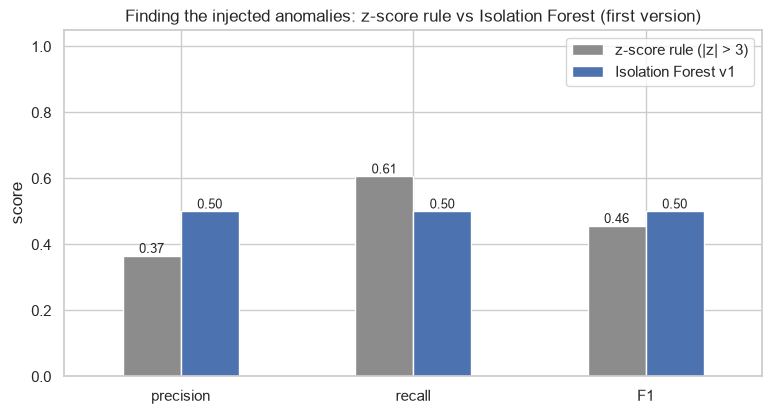

In [53]:
# Visualizing evaluation Metric Score chart
fig, ax = plt.subplots(figsize=(9, 4.5))
m1_results[["precision", "recall", "F1"]].T.plot(kind="bar", ax=ax, color=["#8C8C8C", "#4C72B0"], rot=0)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_title("Finding the injected anomalies: z-score rule vs Isolation Forest (first version)")
ax.set_ylabel("score")
save_fig(fig, "model1_scores_v1")
plt.show()

ML Model 1 finds unusual store-department weeks. Every week gets four features that describe how unusual it is for its own series: the z-score against the series mean, the log ratio to the 9-week rolling median (spike or drop against the local level), and the log change from the week before and to the week after (a one-off spike goes up and comes straight back down).

- The baseline is the classic z-score rule: flag a week if |z| > 3.
- The model is an Isolation Forest. It builds random trees that split the data at random points, and unusual weeks get isolated after only a few splits. It looks at all four features together, so it can see a spike that is normal in size but appears from nowhere.

There are no true anomaly labels, so I made a test set: in a copy of the data, 4,215 normal weeks (1%) got a fake spike (x2.5 to x4) or drop (to 5-30%). A good detector should find those weeks.

| | precision | recall | F1 | weeks flagged |
|---|---|---|---|---|
| z-score rule, |z| > 3 | 0.366 | 0.607 | 0.457 | 6,986 |
| Isolation Forest v1 (1% contamination) | 0.501 | 0.501 | 0.501 | 4,216 |

The z-score rule finds more of the fake anomalies but raises many false alarms, because holiday peaks have a high z-score too. The first Isolation Forest is already better on F1. Precision can never be 1 here, because the real data also has real anomalies that I did not inject.

#### 2. Cross- Validation & Hyperparameter Tuning

Isolation Forest grid search (best 8 of 16):


,features,contamination,max_samples,precision,recall,F1,flagged
0,"z, ratio, chg_prev, chg_next",0.015,256,0.460,0.690,0.552,6324
1,"z, ratio, chg_prev, chg_next",0.020,256,0.406,0.812,0.541,8432
2,"z, ratio, chg_prev, chg_next",0.010,256,0.501,0.501,0.501,4216
3,"z, ratio, chg_prev, chg_next",0.030,256,0.308,0.924,0.462,12648
4,"z, ratio, chg_prev, chg_next",0.020,2048,0.332,0.665,0.443,8432
5,"z, ratio, chg_prev, chg_next",0.030,2048,0.283,0.848,0.424,12648
6,"z, ratio, chg_prev, chg_next",0.015,2048,0.350,0.525,0.420,6324
7,"ratio, chg_prev, chg_next",0.030,256,0.264,0.793,0.396,12648


z-score rule, threshold search:


,threshold,precision,recall,F1,flagged
0,4.0,0.502,0.460,0.480,3865
1,3.5,0.431,0.522,0.472,5113
2,5.0,0.639,0.367,0.466,2420
3,3.0,0.366,0.607,0.457,6986
4,2.5,0.294,0.698,0.414,9998


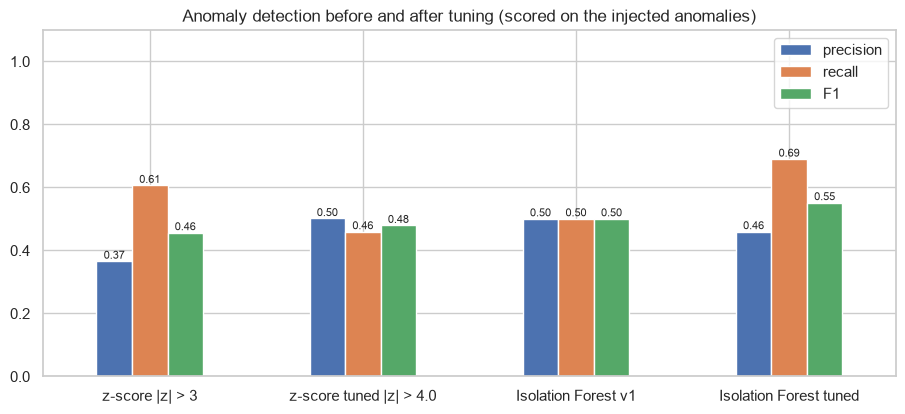

chosen Isolation Forest: features = [z, ratio, chg_prev, chg_next], contamination = 0.015, max_samples = 256, F1 0.501 -> 0.552


In [54]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Grid search. There are no real labels to cross-validate on, so every setting is scored by F1 on the injected anomalies.
FEATURE_CHOICES = {"z, ratio, chg_prev, chg_next": A_FEATURES, "ratio, chg_prev, chg_next": ["ratio", "chg_prev", "chg_next"]}
rows = []
for feat_name, cols in FEATURE_CHOICES.items():
    for contamination in [0.01, 0.015, 0.02, 0.03]:
        for max_samples in [256, 2048]:
            iso = IsolationForest(n_estimators=200, contamination=contamination, max_samples=max_samples,
                                  random_state=SEED, n_jobs=-1)
            flag = (iso.fit_predict(lab_X[cols]) == -1).astype(int)
            rows.append({"features": feat_name, "contamination": contamination, "max_samples": max_samples, **scores(flag)})
m1_grid = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
print("Isolation Forest grid search (best 8 of 16):")
display(m1_grid.head(8).round(3))

# the z-score rule gets the same chance: its best threshold
z_grid = pd.DataFrame([{"threshold": t, **scores((lab_X["z"].abs() > t).astype(int))} for t in [2.5, 3, 3.5, 4, 5]])
z_grid = z_grid.sort_values("F1", ascending=False).reset_index(drop=True)
print("z-score rule, threshold search:")
display(z_grid.round(3))

best_m1, best_z = m1_grid.iloc[0], z_grid.iloc[0]
BEST_A_FEATURES = FEATURE_CHOICES[best_m1["features"]]
BEST_CONTAMINATION, BEST_MAX_SAMPLES = float(best_m1["contamination"]), int(best_m1["max_samples"])
cols = ["precision", "recall", "F1"]
m1_after = pd.DataFrame({"z-score |z| > 3": m1_results.loc["z-score rule (|z| > 3)", cols],
                         f"z-score tuned |z| > {best_z['threshold']}": best_z[cols],
                         "Isolation Forest v1": m1_results.loc["Isolation Forest v1", cols],
                         "Isolation Forest tuned": best_m1[cols]}).T.astype(float)

fig, ax = plt.subplots(figsize=(11, 4.5))
m1_after.plot(kind="bar", ax=ax, rot=0, color=["#4C72B0", "#DD8452", "#55A868"])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
ax.set_ylim(0, 1.1)
ax.set_title("Anomaly detection before and after tuning (scored on the injected anomalies)")
save_fig(fig, "model1_scores_tuned")
plt.show()
print(f"chosen Isolation Forest: features = [{best_m1['features']}], contamination = {BEST_CONTAMINATION}, "
      f"max_samples = {BEST_MAX_SAMPLES}, F1 {m1_results.loc['Isolation Forest v1', 'F1']:.3f} -> {best_m1['F1']:.3f}")

##### Which hyperparameter optimization technique have you used and why?

Grid search. I tried every combination of 2 feature sets (with and without the z-score), 4 contamination values (1%, 1.5%, 2% and 3%) and 2 values of max_samples (256 and 2,048), which is 16 models. Each one was scored by F1 on the injected anomalies. I gave the z-score rule the same chance with 5 thresholds (2.5 to 5). Cross-validation in the usual sense is not possible without labels, so the labelled copy plays the role of the validation set.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. The best Isolation Forest uses all four features, 1.5% contamination and max_samples 256. Its F1 went from 0.501 to 0.552 (precision 0.460, recall 0.690). The best z-score rule (|z| > 4) only reaches F1 0.480. Two details from the grid: without the z-score feature the forest is much worse (best F1 0.396), and small samples (256 weeks per tree) work better than big ones, because an anomaly is easier to isolate in a small sample. The updated chart above compares all four versions.

#### 3. Using the tuned detector on the real data: when and where are the anomalies?

anomalies found: 6,324 (1.5% of store-dept weeks)
spikes: 56%, drops: 43%
in a holiday week, the week before Christmas or Nov/Dec: 33% (those weeks are only 17% of all weeks)
share of store-dept weeks flagged, by holiday (%): {'Christmas': 2.4, 'LaborDay': 1.4, 'None': 1.4, 'SuperBowl': 1.6, 'Thanksgiving': 6.2} | week before Christmas: 15.0
anomalies in weeks with markdowns: 37% (all weeks: 36%)


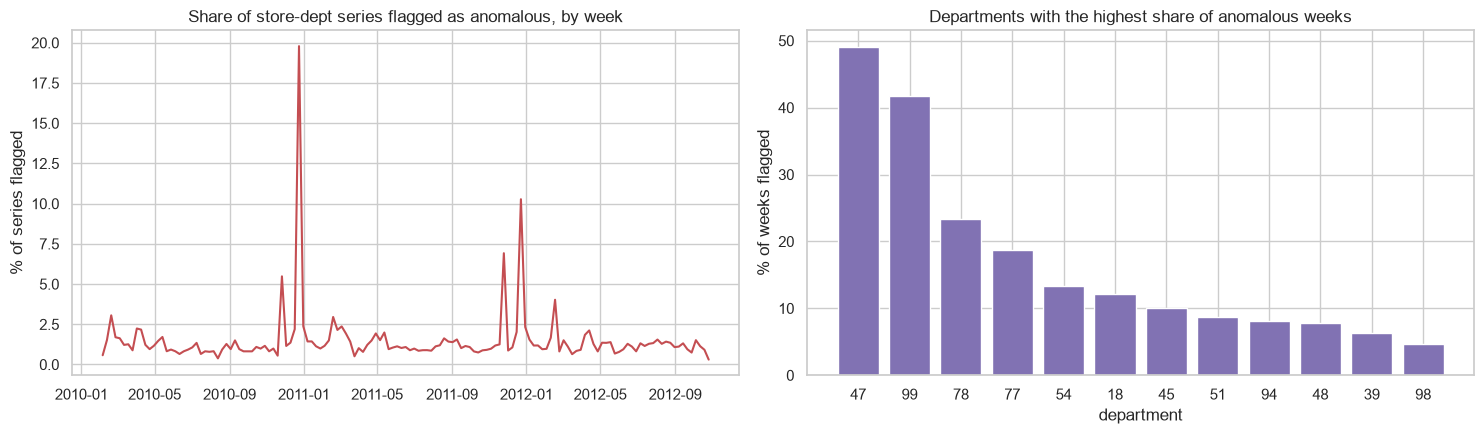

weeks with the highest anomaly rate (%): {'2010-12-24': 19.8, '2011-12-23': 10.3, '2011-11-25': 6.9, '2010-11-26': 5.5, '2012-02-17': 4.0, '2010-02-19': 3.1}
departments with the highest anomaly rate (%): {47: 49.1, 99: 41.8, 78: 23.4, 77: 18.7, 54: 13.4, 18: 12.1}


In [55]:
# fit the tuned Isolation Forest on the real data (no injected values this time)
real_X = anomaly_features(df)
iso_final = IsolationForest(n_estimators=200, contamination=BEST_CONTAMINATION, max_samples=BEST_MAX_SAMPLES,
                            random_state=SEED, n_jobs=-1).fit(real_X[BEST_A_FEATURES])
df["Anomaly"] = (iso_final.predict(real_X[BEST_A_FEATURES]) == -1).astype(int)
df["Anomaly_Score"] = -iso_final.score_samples(real_X[BEST_A_FEATURES])
df["Roll_Med"] = real_X["roll_med"]
df["Season_Week"] = ((df["IsHoliday"] == 1) | (df["PreChristmas"] == 1) | df["Month"].isin([11, 12])).astype(int)

an = df[df["Anomaly"] == 1]
print(f"anomalies found: {len(an):,} ({100 * len(an) / len(df):.1f}% of store-dept weeks)")
print(f"spikes: {(real_X.loc[an.index, 'ratio'] > 0).mean():.0%}, drops: {(real_X.loc[an.index, 'ratio'] < 0).mean():.0%}")
print(f"in a holiday week, the week before Christmas or Nov/Dec: {100 * an['Season_Week'].mean():.0f}% "
      f"(those weeks are only {100 * df['Season_Week'].mean():.0f}% of all weeks)")
rate_hol = an.groupby("Holiday").size() / df.groupby("Holiday").size() * 100
print("share of store-dept weeks flagged, by holiday (%):", rate_hol.round(1).to_dict(),
      f"| week before Christmas: {100 * an['PreChristmas'].sum() / df['PreChristmas'].sum():.1f}")
print(f"anomalies in weeks with markdowns: {100 * an['Has_MarkDown'].mean():.0f}% (all weeks: {100 * df['Has_MarkDown'].mean():.0f}%)")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
rate = (an.groupby("Date").size() / df.groupby("Date").size() * 100).reindex(weekly_total.index, fill_value=0)
axes[0].plot(rate.index, rate.values, color="#C44E52")
axes[0].set_title("Share of store-dept series flagged as anomalous, by week")
axes[0].set_ylabel("% of series flagged")
top_d = (an.groupby("Dept").size() / df.groupby("Dept").size() * 100).sort_values(ascending=False).head(12)
axes[1].bar(top_d.index.astype(str), top_d.values, color="#8172B3")
axes[1].set_title("Departments with the highest share of anomalous weeks")
axes[1].set_xlabel("department")
axes[1].set_ylabel("% of weeks flagged")
plt.tight_layout()
save_fig(fig, "model1_anomalies_real_data")
plt.show()
print("weeks with the highest anomaly rate (%):", {d.date().isoformat(): round(v, 1) for d, v in rate.nlargest(6).items()})
print("departments with the highest anomaly rate (%):", top_d.head(6).round(1).to_dict())

On the real data the tuned detector flags 6,324 store-department weeks (1.5%), 56% spikes and 43% drops. The anomalies are not spread evenly:
- 33% of them are in a holiday week, the week before Christmas or November/December, although those weeks are only 17% of the data. 15% of all store-departments are flagged in the week before Christmas, and 6.2% at Thanksgiving, against 1.4% in a normal week.
- The weeks with the most anomalies are 24 Dec 2010 (19.8% of series flagged), 23 Dec 2011 (10.3%) and the two Thanksgivings.
- Some departments are anomalous much more often: department 47 in 49% of its weeks and 99 in 42%. These are small, irregular departments (47 also has the most negative-sales weeks), followed by 78, 77, 54 and 18.
- Markdowns are not behind the anomalies: 37% of the anomalies are in markdown weeks, about the same as all weeks (36%).

So an anomaly is often a real business event. Holiday peaks are real demand that the forecast must learn, while spikes and drops in normal weeks look like one-off events: a stock-out, a bulk order, a delivery booked in the wrong week.

#### 4. Anomaly handling: cleaning the data for the forecasting model

anomalies kept: 2,445 in the main season or Easter + 1,270 recurring every year = 3,715
weeks replaced: 2,609 (0.62% of rows)
total sales before: 6.7373B $, after: 6.7355B $


median week-to-week variation (CV) of a series: 0.319 -> 0.314
example: store 39, department 18, average 11,335 $ a week, 9 weeks replaced


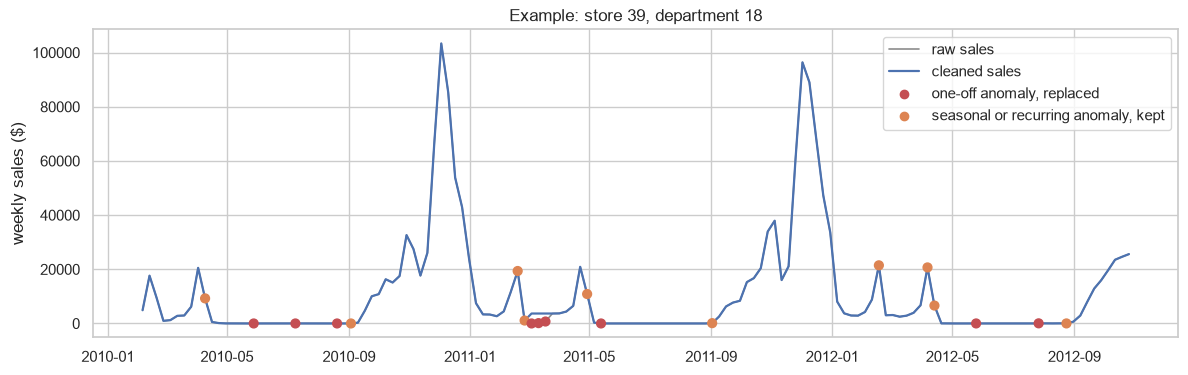

saved outputs/anomalies.csv


In [56]:
# Anomaly handling. An anomaly is kept as real demand when
#  - it is in a holiday week, the week before Christmas, Nov/Dec (the main season) or the Easter week and the week
#    after (Easter moves, so it can't be matched to last year's date), or
#  - the same series had an anomaly within a week of the same date in another year: it comes back every year
#    (Valentine's Day, Easter, back to school), so it is a recurring event and not noise.
# All the other anomalies are one-off spikes or drops (stock-outs, one-time bulk orders, data errors). They are
# replaced by the 9-week rolling median of the same series. Sales keeps the real value; Sales_Clean is the cleaned one.
def seasonal_or_recurring(part, flagged):
    easter = part["Date"].isin(EASTER) | part["Date"].isin(EASTER + pd.Timedelta(weeks=1))
    season = ((part["IsHoliday"] == 1) | (part["PreChristmas"] == 1) | part["Month"].isin([11, 12]) | easter).values
    keys = part.loc[flagged, ["Store", "Dept", "Date"]]
    other_years = pd.concat([keys.assign(Date=keys["Date"] + pd.Timedelta(weeks=w)) for w in (-53, -52, -51, 51, 52, 53)])
    other_years = set(zip(other_years["Store"], other_years["Dept"], other_years["Date"]))
    recurring = flagged & np.array([k in other_years for k in zip(part["Store"], part["Dept"], part["Date"])])
    return season, recurring


flagged = (df["Anomaly"] == 1).values
season, recurring = seasonal_or_recurring(df, flagged)
to_fix = flagged & ~season & ~recurring
df["Anomaly_Kept"] = (flagged & (season | recurring)).astype(int)
df["Sales_Clean"] = np.where(to_fix, df["Roll_Med"], df["Sales"])
print(f"anomalies kept: {(flagged & season).sum():,} in the main season or Easter + {(flagged & recurring & ~season).sum():,} recurring "
      f"every year = {df['Anomaly_Kept'].sum():,}")
print(f"weeks replaced: {to_fix.sum():,} ({100 * to_fix.mean():.2f}% of rows)")
print(f"total sales before: {df['Sales'].sum() / 1e9:.4f}B $, after: {df['Sales_Clean'].sum() / 1e9:.4f}B $")
cv = df.groupby(["Store", "Dept"])[["Sales", "Sales_Clean"]].agg(lambda x: x.std() / x.mean() if x.mean() > 0 else 0)
print(f"median week-to-week variation (CV) of a series: {cv['Sales'].median():.3f} -> {cv['Sales_Clean'].median():.3f}")

# an example: of the series that sell more than $5,000 a week on average, the one with the most replaced weeks
big_series = df.groupby(["Store", "Dept"])["Sales"].transform("mean") > 5000
ex = df[to_fix & big_series].groupby(["Store", "Dept"]).size().idxmax()
s = df[(df["Store"] == ex[0]) & (df["Dept"] == ex[1])]
print(f"example: store {ex[0]}, department {ex[1]}, average {s['Sales'].mean():,.0f} $ a week, "
      f"{int((to_fix & big_series)[s.index].sum())} weeks replaced")
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(s["Date"], s["Sales"], color="#8C8C8C", lw=1.2, label="raw sales")
ax.plot(s["Date"], s["Sales_Clean"], color="#4C72B0", lw=1.6, label="cleaned sales")
flag = s[s["Anomaly"] == 1]
ax.scatter(flag["Date"], flag["Sales"], color=np.where(flag["Anomaly_Kept"] == 1, "#DD8452", "#C44E52"), s=40, zorder=3)
ax.scatter([], [], color="#C44E52", label="one-off anomaly, replaced")
ax.scatter([], [], color="#DD8452", label="seasonal or recurring anomaly, kept")
ax.set_title(f"Example: store {ex[0]}, department {ex[1]}")
ax.set_ylabel("weekly sales ($)")
ax.legend()
save_fig(fig, "model1_cleaning_example")
plt.show()

os.makedirs("outputs", exist_ok=True)
an_cols = ["Store", "Dept", "Date", "Weekly_Sales", "Roll_Med", "Anomaly_Score", "Holiday", "Anomaly_Kept"]
df.loc[df["Anomaly"] == 1, an_cols].sort_values("Anomaly_Score", ascending=False).to_csv("outputs/anomalies.csv", index=False)
print("saved outputs/anomalies.csv")

My handling strategy keeps the business meaning of each anomaly:
- Anomalies in the main season (holiday weeks, the week before Christmas, November/December) and in the Easter week and the week after are real seasonal demand. 2,445 of them are kept.
- Anomalies that come back every year, meaning the same series had an anomaly within a week of the same date in another year (for example Valentine's Day peaks), are recurring events and not noise. 1,270 more are kept.
- The other 2,609 anomalies (0.62% of rows) are one-off spikes or drops. They are replaced by the 9-week rolling median of the same series in a separate Sales_Clean column. The raw sales stay in the data.

This changes only 0.03% of total sales (6.7373B to 6.7355B $) and makes the series a bit smoother (median coefficient of variation 0.319 to 0.314). The example (store 39, department 18, a seasonal department) shows why the keep rules matter: its Valentine's and Easter peaks are kept (orange), and only short drops to zero in its quiet months are replaced (red). My first version only protected November and December, and it wrongly removed those Valentine's and Easter peaks. Checking the chart showed me the mistake.

ML Model 3 tests whether training on the cleaned sales helps the forecast. It did not: in cross-validation the cleaned target was slightly worse (WMAE 1,818 against 1,805), so the final forecast is trained on the real sales. The anomaly flags are still useful for reporting, and they are all saved in outputs/anomalies.csv so they can be checked with the stores.

### ML Model - 2 - Store segmentation (KMeans)

In [57]:
# ML Model - 2 Implementation
# Store segmentation with KMeans. First version: all 13 store features from feature engineering, k = 4
km_v1 = KMeans(n_clusters=4, n_init=20, random_state=SEED)
labels_v1 = km_v1.fit_predict(X_seg_all)
m2_v1 = {"silhouette": silhouette_score(X_seg_all, labels_v1),
         "davies_bouldin": davies_bouldin_score(X_seg_all, labels_v1),
         "calinski_harabasz": calinski_harabasz_score(X_seg_all, labels_v1)}
print("segment sizes:", np.bincount(labels_v1).tolist())
print({k: round(v, 3) for k, v in m2_v1.items()})

segment sizes: [8, 14, 11, 12]
{'silhouette': 0.198, 'davies_bouldin': 1.522, 'calinski_harabasz': 14.701}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

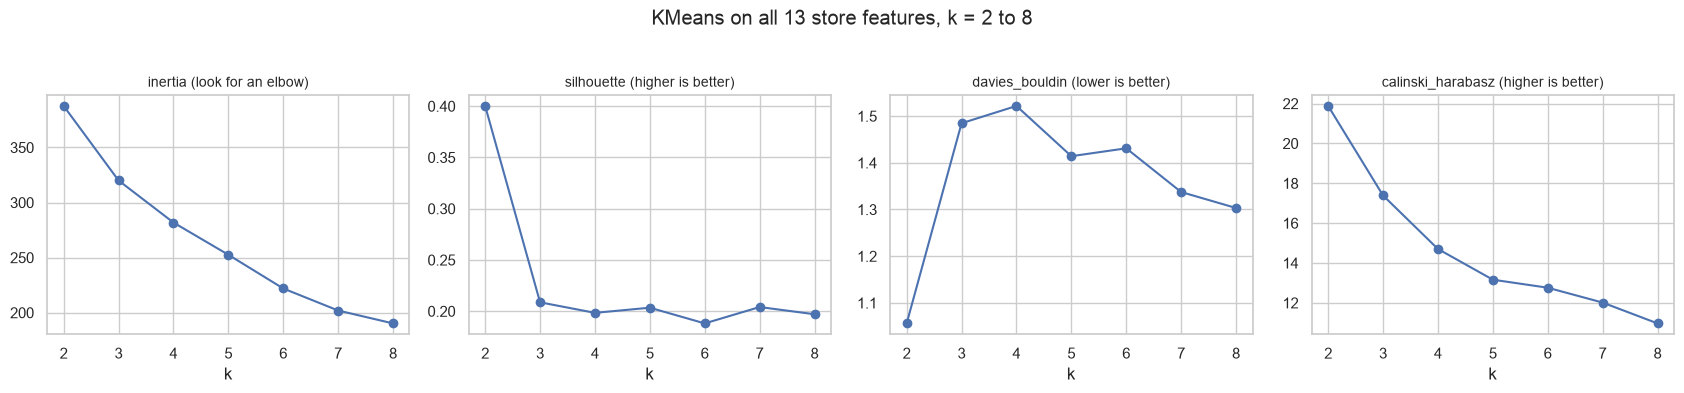

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,387.718,0.400,1.056,21.880
3,320.037,0.209,1.485,17.386
4,281.835,0.198,1.522,14.701
5,252.590,0.203,1.414,13.160
6,221.965,0.188,1.431,12.757
7,201.960,0.204,1.337,12.012
8,190.258,0.197,1.303,10.967


In [58]:
# Visualizing evaluation Metric Score chart
rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=20, random_state=SEED).fit(X_seg_all)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_seg_all, km.labels_),
                 "davies_bouldin": davies_bouldin_score(X_seg_all, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(X_seg_all, km.labels_)})
k_scan = pd.DataFrame(rows).set_index("k")
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col, hint in zip(axes, k_scan.columns, ["look for an elbow", "higher is better", "lower is better", "higher is better"]):
    ax.plot(k_scan.index, k_scan[col], marker="o")
    ax.set_title(f"{col} ({hint})", fontsize=10)
    ax.set_xlabel("k")
fig.suptitle("KMeans on all 13 store features, k = 2 to 8", y=1.03)
plt.tight_layout()
save_fig(fig, "model2_k_scan_v1")
plt.show()
display(k_scan.round(3))

ML Model 2 groups the 45 stores into segments with KMeans. KMeans puts every store in the group whose centre is closest and moves the centres until they stop changing. The first version used all 13 store features from feature engineering (sales level, sales per sq ft, size, volatility, holiday and Q4 uplift, growth, markdown share, temperature, unemployment, CPI, fuel price and number of departments) with k = 4.

The result is weak: segment sizes 8, 14, 11 and 12, silhouette 0.198, Davies-Bouldin 1.522 and Calinski-Harabasz 14.7. The scan over k shows the same picture. Only k = 2 reaches a silhouette of 0.40, and that split just separates the small stores from the rest. For every other k the silhouette stays around 0.2, so the stores do not form clear groups when all 13 features are used. Many of the features carry little information about how a store should be managed, and with 45 stores they mostly add noise to the distances.

#### 2. Cross- Validation & Hyperparameter Tuning

silhouette by feature set (rows) and k (columns):


k,2,3,4,5,6
features,,,,,
all 13 features,0.400,0.209,0.198,0.203,0.188
sales pattern + markdowns + all regional,0.356,0.236,0.236,0.236,0.258
volume + seasonality + growth + region (CPI),0.326,0.335,0.371,0.363,0.335
volume + seasonality + markdowns,0.606,0.510,0.497,0.440,0.428
volume + seasonality + markdowns + region (CPI),0.484,0.393,0.415,0.429,0.452
volume + volatility + growth + markdowns + CPI,0.349,0.287,0.299,0.326,0.337


Davies-Bouldin:


k,2,3,4,5,6
features,,,,,
all 13 features,1.056,1.485,1.522,1.414,1.431
sales pattern + markdowns + all regional,1.175,1.445,1.325,1.335,1.217
volume + seasonality + growth + region (CPI),1.386,1.109,0.949,0.898,0.988
volume + seasonality + markdowns,0.472,0.724,0.669,0.781,0.810
volume + seasonality + markdowns + region (CPI),0.784,1.007,0.840,0.825,0.737
volume + volatility + growth + markdowns + CPI,1.315,1.282,1.173,1.026,0.974


stability of the chosen features for k = 2..6: {2: 1.0, 3: 0.77, 4: 0.82, 5: 0.83, 6: 0.86}


,silhouette,davies_bouldin,same segments as KMeans (ARI)
KMeans,0.415,0.840,1.000
Agglomerative (Ward),0.417,0.797,0.874
Gaussian Mixture,0.417,0.797,0.874


,silhouette,davies_bouldin,stability (ARI)
"v1: 13 features, k=4",0.198,1.522,0.521
"tuned: 4 features, k=4",0.415,0.840,0.816


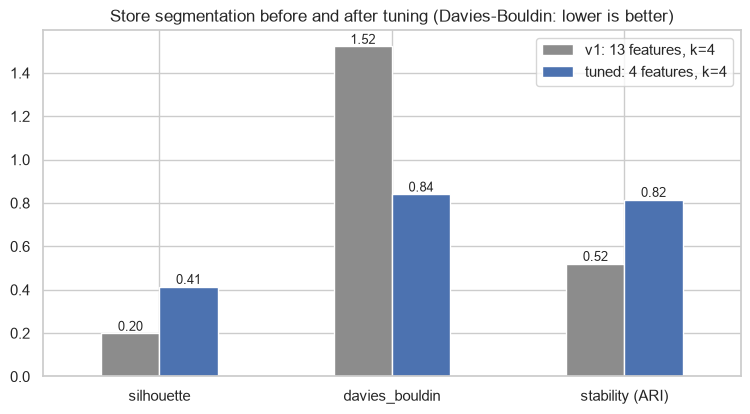

In [59]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Grid search over the feature set and k. There are no labels, so the scores are silhouette and Davies-Bouldin,
# plus how stable the segments stay when the stores are resampled (bootstrap, adjusted Rand index).
FEATURE_SETS = {
    "all 13 features": SEG_ALL,
    "volume + seasonality + markdowns + region (CPI)": ["Log_Sales", "Q4_Uplift", "MarkDown_Share", "CPI"],
    "volume + seasonality + markdowns": ["Log_Sales", "Q4_Uplift", "MarkDown_Share"],
    "volume + seasonality + growth + region (CPI)": ["Log_Sales", "Q4_Uplift", "Growth", "CPI"],
    "volume + volatility + growth + markdowns + CPI": ["Log_Sales", "Sales_CV", "Growth", "MarkDown_Share", "CPI"],
    "sales pattern + markdowns + all regional": ["Log_Sales", "Q4_Uplift", "Growth", "MarkDown_Share", "Unemployment", "CPI", "Temperature"],
}


def bootstrap_stability(X, k, n_boot=30):
    """Average ARI between the segments on all stores and the segments learned from bootstrap samples."""
    base = KMeans(k, n_init=10, random_state=SEED).fit(X)
    rng_b = np.random.default_rng(SEED)
    aris = []
    for b in range(n_boot):
        idx = rng_b.choice(len(X), len(X), replace=True)
        boot = KMeans(k, n_init=10, random_state=b).fit(X[idx])
        aris.append(adjusted_rand_score(base.labels_, boot.predict(X)))
    return float(np.mean(aris))


rows = []
for name, cols in FEATURE_SETS.items():
    X = StandardScaler().fit_transform(store_profile[cols])
    for k in range(2, 7):
        l = KMeans(k, n_init=20, random_state=SEED).fit_predict(X)
        rows.append({"features": name, "k": k, "silhouette": silhouette_score(X, l),
                     "davies_bouldin": davies_bouldin_score(X, l), "smallest_segment": int(np.bincount(l).min())})
m2_grid = pd.DataFrame(rows)
print("silhouette by feature set (rows) and k (columns):")
display(m2_grid.pivot(index="features", columns="k", values="silhouette").round(3))
print("Davies-Bouldin:")
display(m2_grid.pivot(index="features", columns="k", values="davies_bouldin").round(3))

# chosen: one feature for each part of the brief (sales pattern, markdowns, regional), k = 4 (reasons below)
SEG_FEATURES = ["Log_Sales", "Q4_Uplift", "MarkDown_Share", "CPI"]
K_SEG = 4
seg_scaler = StandardScaler()
X_seg = seg_scaler.fit_transform(store_profile[SEG_FEATURES])
print("stability of the chosen features for k = 2..6:",
      {k: round(bootstrap_stability(X_seg, k), 2) for k in range(2, 7)})

# three algorithms on the chosen features
algos = {"KMeans": KMeans(K_SEG, n_init=20, random_state=SEED).fit_predict(X_seg),
         "Agglomerative (Ward)": AgglomerativeClustering(K_SEG).fit_predict(X_seg),
         "Gaussian Mixture": GaussianMixture(K_SEG, n_init=5, random_state=SEED).fit(X_seg).predict(X_seg)}
algo_scores = pd.DataFrame({n: {"silhouette": silhouette_score(X_seg, l), "davies_bouldin": davies_bouldin_score(X_seg, l),
                                "same segments as KMeans (ARI)": adjusted_rand_score(algos["KMeans"], l)}
                            for n, l in algos.items()}).T
display(algo_scores.round(3))

km_final = KMeans(K_SEG, n_init=20, random_state=SEED).fit(X_seg)
m2_after = pd.DataFrame({
    "v1: 13 features, k=4": {"silhouette": m2_v1["silhouette"], "davies_bouldin": m2_v1["davies_bouldin"],
                             "stability (ARI)": bootstrap_stability(X_seg_all, 4)},
    "tuned: 4 features, k=4": {"silhouette": silhouette_score(X_seg, km_final.labels_),
                               "davies_bouldin": davies_bouldin_score(X_seg, km_final.labels_),
                               "stability (ARI)": bootstrap_stability(X_seg, K_SEG)}}).T
display(m2_after.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
m2_after.T.plot(kind="bar", ax=ax, rot=0, color=["#8C8C8C", "#4C72B0"])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=9)
ax.set_title("Store segmentation before and after tuning (Davies-Bouldin: lower is better)")
save_fig(fig, "model2_scores_tuned")
plt.show()

##### Which hyperparameter optimization technique have you used and why?

Grid search over the feature set and k. I tried 6 feature sets (from all 13 features down to 3), each with k from 2 to 6, and scored them with the silhouette and the Davies-Bouldin index. For the chosen set I also measured stability with a bootstrap: KMeans was refit on 30 resampled sets of stores, and the adjusted Rand index measures how much the segments of the original stores stay the same. Finally I compared KMeans with two other algorithms (Ward agglomerative clustering and a Gaussian mixture) on the same features.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a lot. I chose four features, one for each part of the brief: sales volume (Log_Sales), seasonality (Q4_Uplift), markdown intensity (MarkDown_Share) and the regional price level (CPI), with k = 4:

| | silhouette | Davies-Bouldin | stability (ARI) |
|---|---|---|---|
| v1: 13 features, k = 4 | 0.198 | 1.522 | 0.52 |
| tuned: 4 features, k = 4 | 0.415 | 0.840 | 0.82 |

The silhouette doubled, the Davies-Bouldin index almost halved (lower is better) and the segments became much more stable. Ward clustering and the Gaussian mixture find almost the same segments (silhouette 0.417, adjusted Rand 0.87 against KMeans), so the structure is real and not an accident of one algorithm.

I did not simply take the highest score. Volume + seasonality + markdowns with k = 2 has a silhouette of 0.61, but two segments (small stores vs the rest) are not useful for planning, and that set leaves out the regional factor the brief asks for. k = 4 with four features scores well, is stable (0.82) and gives segments that each need a different plan.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- Silhouette (how much closer a store is to its own segment than to the next one): a high value means the stores in a segment really are alike, so one plan for the segment fits all its stores.
- Davies-Bouldin (average similarity between each segment and its closest neighbour): a low value means the segments are clearly different, so it is worth having different strategies for them.
- Bootstrap stability (adjusted Rand index): a high value means the segments don't change just because one store is added or removed. A segmentation that changes every quarter can't be used to plan budgets, assortments and staff.

The business impact is that the chain can manage 4 groups instead of 45 single stores. Markdown budgets, stock buffers, assortment and staffing can be set per segment, which is simpler and less error-prone than per-store guesses, and more accurate than one plan for the whole chain.

#### 4. Segment profiles and segment-specific trends

In [60]:
# number the segments by average store sales (1 = biggest), so the numbers stay the same on every run
seg_raw = pd.Series(km_final.labels_, index=store_profile.index)
seg_order = store_profile["Avg_Sales"].groupby(seg_raw).mean().sort_values(ascending=False).index
store_profile["Segment"] = seg_raw.map({old: new for new, old in enumerate(seg_order, start=1)})

prof = store_profile.groupby("Segment").agg(
    stores=("Size", "size"),
    type_mix=("Type", lambda x: " ".join(f"{t}:{n}" for t, n in x.value_counts().sort_index().items())),
    avg_weekly_sales_M=("Avg_Sales", lambda x: x.mean() / 1e6), size_thousand_sqft=("Size", lambda x: x.mean() / 1000),
    sales_per_sqft=("Sales_per_SqFt", "mean"), q4_uplift_pct=("Q4_Uplift", lambda x: 100 * x.mean()),
    holiday_uplift_pct=("Holiday_Uplift", lambda x: 100 * x.mean()), markdown_share_pct=("MarkDown_Share", lambda x: 100 * x.mean()),
    cpi=("CPI", "mean"), unemployment=("Unemployment", "mean"), temperature=("Temperature", "mean"),
    growth_pct=("Growth", lambda x: 100 * x.mean()), sales_cv=("Sales_CV", "mean"))
display(prof.T)
for s, g in store_profile.groupby("Segment"):
    print(f"segment {s}: stores {sorted(g.index.tolist())}")

Segment,1,2,3,4
stores,11,16,10,8
type_mix,A:11,A:9 B:7,B:10,A:2 C:6
avg_weekly_sales_M,1.520072,1.322342,0.57661,0.433633
size_thousand_sqft,191.866455,156.230063,92.988,40.35625
sales_per_sqft,7.932891,8.703306,6.971672,10.73213
q4_uplift_pct,16.672902,17.430583,22.128662,-2.105527
holiday_uplift_pct,6.984086,9.272845,11.197902,-0.532126
markdown_share_pct,1.63248,1.790075,2.182698,0.484026
cpi,209.186785,133.021699,192.406762,170.944786
unemployment,7.471106,8.228251,7.608264,8.755622


segment 1: stores [1, 2, 6, 8, 11, 14, 20, 31, 32, 39, 41]
segment 2: stores [4, 10, 12, 13, 17, 18, 19, 22, 23, 24, 26, 27, 28, 34, 35, 40]
segment 3: stores [3, 5, 7, 9, 15, 16, 21, 25, 29, 45]
segment 4: stores [30, 33, 36, 37, 38, 42, 43, 44]


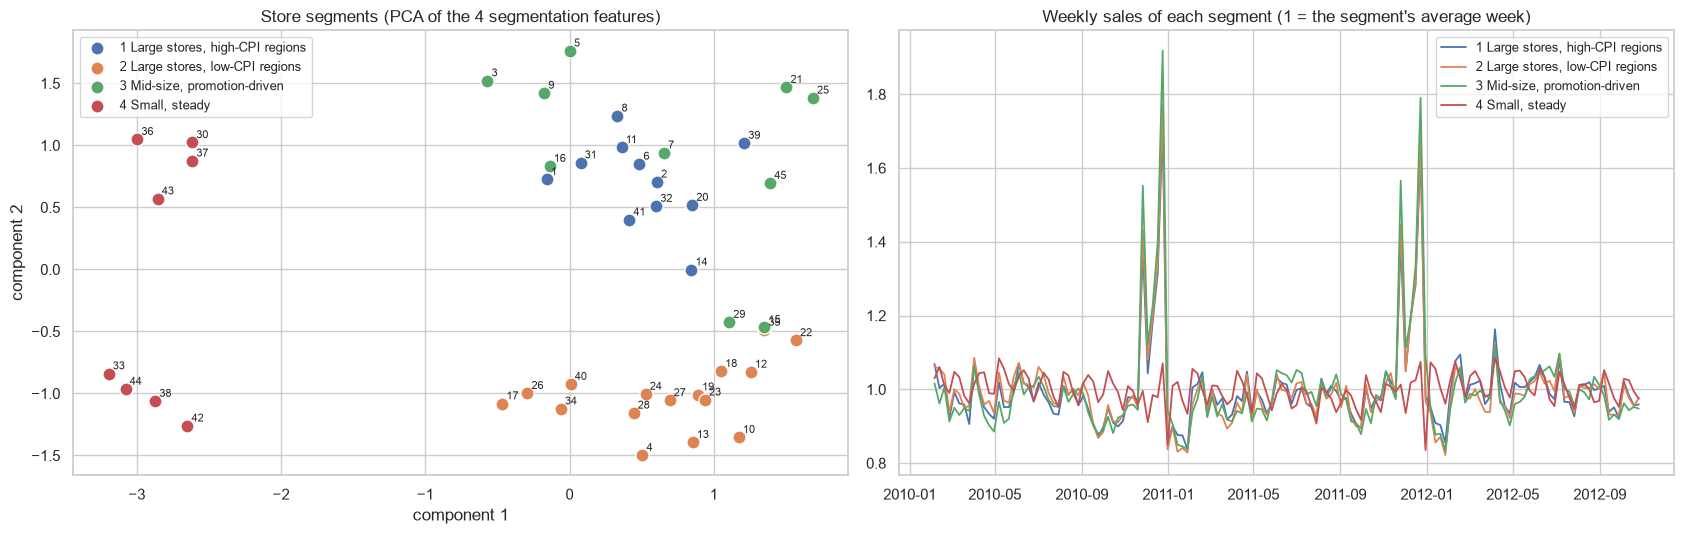

growth Feb-Oct 2012 vs Feb-Oct 2010 (%): {'1 Large stores, high-CPI regions': 5.0, '2 Large stores, low-CPI regions': 0.5, '3 Mid-size, promotion-driven': 4.8, '4 Small, steady': 1.4}
biggest week vs average week: {'1 Large stores, high-CPI regions': 1.72, '2 Large stores, low-CPI regions': 1.77, '3 Mid-size, promotion-driven': 1.92, '4 Small, steady': 1.08}


In [61]:
SEGMENT_NAMES = {1: "1 Large stores, high-CPI regions", 2: "2 Large stores, low-CPI regions",
                 3: "3 Mid-size, promotion-driven", 4: "4 Small, steady"}
SEG_COLORS = {1: "#4C72B0", 2: "#DD8452", 3: "#55A868", 4: "#C44E52"}
store_profile["Segment_Name"] = store_profile["Segment"].map(SEGMENT_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
pts = PCA(2, random_state=SEED).fit_transform(X_seg)
for s, name in SEGMENT_NAMES.items():
    m = (store_profile["Segment"] == s).values
    axes[0].scatter(pts[m, 0], pts[m, 1], s=90, color=SEG_COLORS[s], label=name, edgecolor="white")
for (x, y), st in zip(pts, store_profile.index):
    axes[0].annotate(st, (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[0].set_title("Store segments (PCA of the 4 segmentation features)")
axes[0].set_xlabel("component 1")
axes[0].set_ylabel("component 2")
axes[0].legend(fontsize=9)

seg_week = (store_week.merge(store_profile[["Segment"]], left_on="Store", right_index=True)
            .groupby(["Segment", "Date"])["Sales"].sum().unstack(0))
seg_index = seg_week / seg_week.mean()
for s in seg_index.columns:
    axes[1].plot(seg_index.index, seg_index[s], color=SEG_COLORS[s], lw=1.3, label=SEGMENT_NAMES[s])
axes[1].set_title("Weekly sales of each segment (1 = the segment's average week)")
axes[1].legend(fontsize=9)
plt.tight_layout()
save_fig(fig, "model2_segments")
plt.show()

growth_seg = store_profile.groupby("Segment_Name")["Growth"].mean() * 100
print("growth Feb-Oct 2012 vs Feb-Oct 2010 (%):", growth_seg.round(1).to_dict())
print("biggest week vs average week:", (seg_index.max()).round(2).rename(SEGMENT_NAMES).to_dict())

The four segments (numbered by store size) are easy to describe:

| Segment | Stores | What makes it different |
|---|---|---|
| 1 Large stores, high-CPI regions | 11 (all type A) | biggest stores (192k sq ft, 1.52M $ a week), CPI about 209, Q4 uplift 17%, growth +5.0% |
| 2 Large stores, low-CPI regions | 16 (9 A, 7 B) | large (156k sq ft, 1.32M $), in the low-price region (CPI 133), cooler (56 °F), highest unemployment of the big stores (8.2%), almost no growth (+0.5%) |
| 3 Mid-size, promotion-driven | 10 (all type B) | 93k sq ft, 0.58M $ a week, the strongest season (Q4 +22%, holiday weeks +11%) and the highest markdown share (2.2% of sales), most volatile, growth +4.8% |
| 4 Small, steady | 8 (6 C, 2 small A) | 40k sq ft, 0.43M $ a week, but the highest sales per sq ft (10.7 $), no Christmas peak at all (Q4 -2%), few markdowns (0.5%), the warmest (69 °F) and highest unemployment (8.8%) |

The segment trend chart shows the difference clearly. Segment 3's biggest week is 1.92 times its average week, segments 1 and 2 about 1.7 to 1.8 times, and segment 4 only 1.08 times. The small stores sell the same every week, while the promotion-driven stores depend heavily on the holidays. Stores 33 and 36, the two small type A stores from chart 8, end up in segment 4 with the C stores, which shows the segments follow the real sales pattern and not the type letter.

#### 5. Segmentation quality evaluation: homogeneity and separation

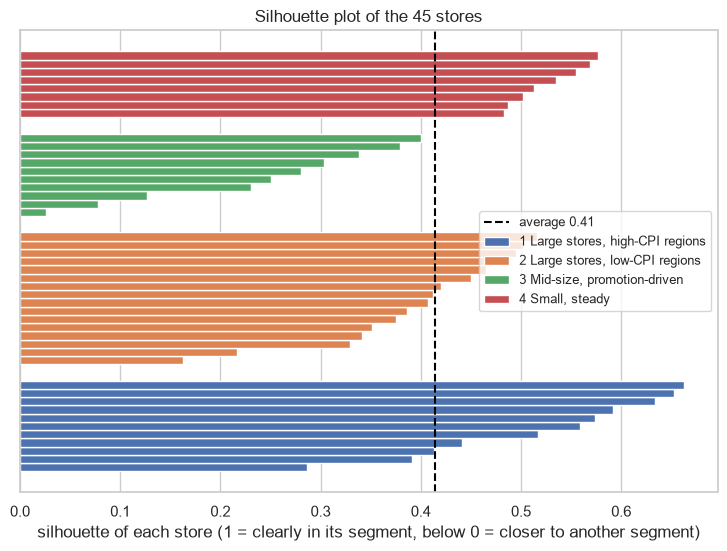

homogeneity (within-segment std / overall std) and silhouette per segment:


,Log_Sales,Q4_Uplift,MarkDown_Share,CPI,silhouette,stores below 0
Segment,,,,,,
1,0.43,0.33,0.42,0.30,0.52,0
2,0.51,0.54,0.68,0.11,0.39,0
3,0.48,0.56,0.59,0.82,0.24,0
4,0.52,0.25,0.26,1.14,0.53,0


distance between segment centres:


,1,2,3,4
1,0.00,1.98,2.03,3.62
2,1.98,0.00,2.22,3.64
3,2.03,2.22,0.00,3.79
4,3.62,3.64,3.79,0.00


average distance of a store to its own centre: {1: 0.69, 2: 0.92, 3: 1.13, 4: 1.23}
closest pair of centres: 1.98 vs largest within-segment distance: 1.23
   Growth          differs between segments: p = 0.4751
   Sales_CV        differs between segments: p = 0.0008
   Unemployment    differs between segments: p = 0.3393
   Temperature     differs between segments: p = 0.0161
   Sales_per_SqFt  differs between segments: p = 0.0355


In [62]:
from scipy.spatial.distance import cdist

seg_labels = store_profile["Segment"].values
sil = silhouette_samples(X_seg, seg_labels)
store_profile["Silhouette"] = sil

fig, ax = plt.subplots(figsize=(9, 6))
y0 = 0
for s in sorted(SEGMENT_NAMES):
    v = np.sort(sil[seg_labels == s])
    ax.barh(range(y0, y0 + len(v)), v, color=SEG_COLORS[s], height=1.0, label=SEGMENT_NAMES[s])
    y0 += len(v) + 2
ax.axvline(sil.mean(), color="black", ls="--", label=f"average {sil.mean():.2f}")
ax.set_yticks([])
ax.set_xlabel("silhouette of each store (1 = clearly in its segment, below 0 = closer to another segment)")
ax.set_title("Silhouette plot of the 45 stores")
ax.legend(fontsize=9)
save_fig(fig, "model2_silhouette_plot")
plt.show()

# homogeneity: spread of each feature inside a segment, divided by its spread over all stores (below 1 = tighter)
homog = store_profile.groupby("Segment")[SEG_FEATURES].std() / store_profile[SEG_FEATURES].std()
homog["silhouette"] = store_profile.groupby("Segment")["Silhouette"].mean()
homog["stores below 0"] = store_profile.groupby("Segment")["Silhouette"].apply(lambda x: int((x < 0).sum()))
print("homogeneity (within-segment std / overall std) and silhouette per segment:")
display(homog.round(2))

# separation: distance between segment centres vs average distance of stores to their own centre (standardised units)
centres = pd.DataFrame(X_seg).groupby(seg_labels).mean()
between = pd.DataFrame(cdist(centres, centres), index=centres.index, columns=centres.index)
within = pd.Series([np.linalg.norm(X_seg[seg_labels == s] - centres.loc[s].values, axis=1).mean() for s in centres.index],
                   index=centres.index)
print("distance between segment centres:")
display(between.round(2))
print("average distance of a store to its own centre:", within.round(2).to_dict())
print(f"closest pair of centres: {between.replace(0, np.nan).min().min():.2f} vs largest within-segment distance: {within.max():.2f}")

# do the segments also differ on things they were NOT built from? (Kruskal-Wallis across segments)
for col in ["Growth", "Sales_CV", "Unemployment", "Temperature", "Sales_per_SqFt"]:
    h, pv = stats.kruskal(*[g[col] for _, g in store_profile.groupby("Segment")])
    print(f"   {col:15} differs between segments: p = {pv:.4f}")

Homogeneity (stores in a segment are alike):
- Every store has a positive silhouette, so no store would fit better in another segment. The average is 0.415: segment 4 is the tightest (0.53), then segment 1 (0.52), segment 2 (0.39) and segment 3 (0.24).
- Inside the segments the spread of the features is much smaller than over all stores (ratio below 1). Log sales has a ratio of 0.43-0.52 and Q4 uplift 0.25-0.56. The exception is CPI in segments 3 and 4 (0.82 and 1.14): those segments are defined by size, season and markdowns, and they include stores from both price regions.

Separation (segments are different from each other):
- The closest pair of segment centres is 1.98 standardised units apart, while the stores are on average at most 1.23 from their own centre. So the gap between segments is bigger than the spread inside them. Segment 4 is far from all the others (3.6 to 3.8).

An extra check: the segments also differ on things they were not built from. Sales volatility (p = 0.0008), temperature (p = 0.016) and sales per sq ft (p = 0.036) differ significantly between segments, while growth (p = 0.48) and unemployment (p = 0.34) do not. So the segments carry real information about how the stores behave, beyond the four inputs. The weak point is segment 3 (silhouette 0.24), which sits between the large and the small stores. Its plans should be reviewed most often.

### ML Model - 3 - Demand forecasting (Holt-Winters and LightGBM)

In [63]:
# ML Model - 3 Implementation
# Demand forecasting: weekly sales of every store-dept for the 39 test weeks (Feb to Oct 2012)
train = df[df["Date"] <= TRAIN_END].copy()
test = df[df["Date"] > TRAIN_END].copy()
CAT = ["Store", "Dept"]


# 1. Holt-Winters (classic time-series model): one model per store-dept series that has all 104 training weeks
#    and all 39 test weeks. Additive trend (damped) and additive yearly seasonality (52 weeks).
def holt_winters(y, horizon=39):
    warnings.filterwarnings("ignore")   # runs in separate worker processes, so the filter is set here too
    try:
        model = ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="add", seasonal_periods=52).fit()
        return np.clip(model.forecast(horizon), 0, None)
    except Exception:
        return np.full(horizon, np.mean(y[-52:]))   # fall back to last year's average


n_tr, n_te = train.groupby(CAT).size(), test.groupby(CAT).size()
full_keys = n_tr[n_tr == 104].index.intersection(n_te[n_te == 39].index)
hw_groups = list(train.set_index(CAT).loc[full_keys].groupby(level=[0, 1])["Sales"])
hw_out = Parallel(n_jobs=-1)(delayed(holt_winters)(s.values) for _, s in hw_groups)
test_dates = np.sort(test["Date"].unique())
hw_df = pd.DataFrame({"Store": np.repeat([k[0] for k, _ in hw_groups], 39),
                      "Dept": np.repeat([k[1] for k, _ in hw_groups], 39),
                      "Date": np.tile(test_dates, len(hw_groups)),
                      "Holt-Winters": np.concatenate(hw_out)})
test = test.merge(hw_df, on=["Store", "Dept", "Date"], how="left")
print(f"Holt-Winters models fitted: {len(hw_groups):,} series")

# 2. seasonal naive baseline: the same week last year (store-dept average if there is none)
test["Seasonal naive"] = test["Lag52"].fillna(test["SD_Mean"]).fillna(0)

# 3. LightGBM: one global model for all store-depts
LGB_PARAMS = dict(n_estimators=600, learning_rate=0.05, num_leaves=127, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, random_state=SEED, n_jobs=-1, deterministic=True, force_row_wise=True, verbose=-1)
# long-term: only features that are known in advance, so it forecasts all 39 weeks in one go
lgb_long = lgb.LGBMRegressor(**LGB_PARAMS).fit(train[LONG_FEATURES], train["Sales"], categorical_feature=CAT)
test["LightGBM long-term"] = lgb_long.predict(test[LONG_FEATURES]).clip(0)
# short-term: also uses the last weeks' sales, so it can only forecast the next week
lgb_short = lgb.LGBMRegressor(**LGB_PARAMS).fit(train[SHORT_FEATURES], train["Sales"], categorical_feature=CAT)
test["LightGBM short-term (1 week ahead)"] = lgb_short.predict(test[SHORT_FEATURES]).clip(0)


def evaluate(frame, cols):
    out = {}
    for c in cols:
        y, p = frame["Sales"].values, frame[c].values
        out[c] = {"WMAE": wmae(y, p, frame["IsHoliday"]), "MAE": np.mean(np.abs(y - p)),
                  "RMSE": np.sqrt(np.mean((y - p) ** 2)), "R2": 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)}
    return pd.DataFrame(out).T


MODELS_V1 = ["Seasonal naive", "Holt-Winters", "LightGBM long-term", "LightGBM short-term (1 week ahead)"]
subset = test[test["Holt-Winters"].notna()]
m3_subset = evaluate(subset, MODELS_V1)
m3_all = evaluate(test, [m for m in MODELS_V1 if m != "Holt-Winters"])
print(f"series with full history, all 4 models ({len(subset):,} test rows):")
display(m3_subset.round(3))
print(f"all {len(test):,} test rows (Holt-Winters can't be used on series with gaps):")
display(m3_all.round(3))

Holt-Winters models fitted: 2,660 series


series with full history, all 4 models (103,740 test rows):


,WMAE,MAE,RMSE,R2
Seasonal naive,1945.689,1940.063,4021.327,0.969
Holt-Winters,1802.744,1808.011,3770.723,0.973
LightGBM long-term,1665.485,1652.324,3246.783,0.980
LightGBM short-term (1 week ahead),1408.065,1375.199,2844.463,0.984


all 115,588 test rows (Holt-Winters can't be used on series with gaps):


,WMAE,MAE,RMSE,R2
Seasonal naive,1807.408,1806.987,3870.194,0.970
LightGBM long-term,1545.613,1535.510,3104.023,0.980
LightGBM short-term (1 week ahead),1300.424,1272.176,2714.919,0.985


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

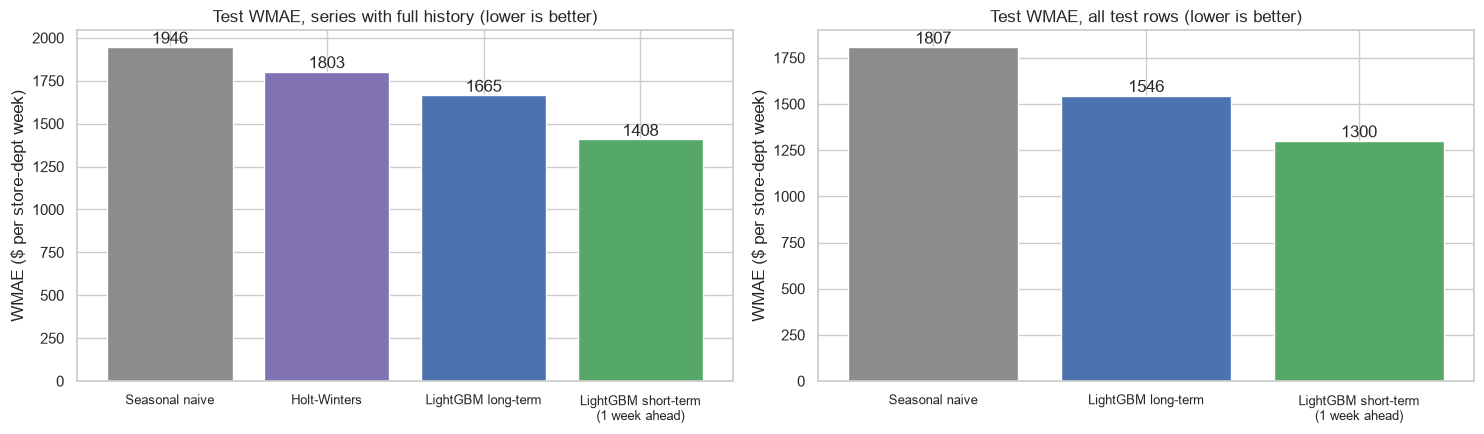

In [64]:
# Visualizing evaluation Metric Score chart
MODEL_COLORS = {"Seasonal naive": "#8C8C8C", "Holt-Winters": "#8172B3", "LightGBM long-term": "#4C72B0",
                "LightGBM short-term (1 week ahead)": "#55A868"}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (title, table) in zip(axes, [("series with full history", m3_subset), ("all test rows", m3_all)]):
    names = [n.replace(" (1 week ahead)", "\n(1 week ahead)") for n in table.index]
    bars = ax.bar(names, table["WMAE"], color=[MODEL_COLORS[n] for n in table.index])
    ax.bar_label(bars, fmt="%.0f")
    ax.set_title(f"Test WMAE, {title} (lower is better)")
    ax.set_ylabel("WMAE ($ per store-dept week)")
    ax.tick_params(axis="x", labelsize=9)
plt.tight_layout()
save_fig(fig, "model3_scores_v1")
plt.show()

ML Model 3 forecasts weekly sales for every store and department for the 39 test weeks (Feb to Oct 2012), comparing four approaches:
- Seasonal naive (baseline): the same week last year.
- Holt-Winters exponential smoothing: a classic time-series model fitted separately to each of the 2,660 series with full history. It has a damped trend and an additive 52-week seasonal pattern.
- LightGBM long-term: one gradient-boosted tree model for all store-departments together. It only uses features that are known in advance (store and department, size and type, calendar, holidays and Easter, same week last year, the store-department average, markdowns and the economic data), so it forecasts all 39 weeks on 27 January.
- LightGBM short-term: the same model plus last week's sales, the week before and the 4-week average, so it can only forecast one week ahead.

| | WMAE (full-history series) | WMAE (all test rows) | R² (all) |
|---|---|---|---|
| Seasonal naive | 1,946 | 1,807 | 0.970 |
| Holt-Winters | 1,803 | - | - |
| LightGBM long-term | 1,665 | 1,546 | 0.980 |
| LightGBM short-term | 1,408 | 1,300 | 0.985 |

The R² looks very high for every model because the big differences between departments are easy to predict. WMAE, in dollars per store-department week with holiday weeks counted 5 times, is the fair comparison. Holt-Winters beats the naive baseline by 7%, and the long-term LightGBM beats Holt-Winters by another 8%, because it learns from all series at once and uses holidays, Easter and the external factors. The short-term model is the most accurate (28% better than the naive baseline), but it only works one week ahead.

#### 2. Cross- Validation & Hyperparameter Tuning

step 1, grid search on the raw target:


,num_leaves,holiday_weight,cleaned_target,fold1_WMAE,fold2_WMAE,mean_WMAE,trees
3,255,True,False,1445.4,2164.8,1805.1,1422
2,255,False,False,1460.1,2214.6,1837.4,1241
0,127,False,False,1459.3,2249.4,1854.3,1214
1,127,True,False,1501.6,2230.6,1866.1,1073


step 2, raw vs cleaned target with the best setting:


,num_leaves,holiday_weight,cleaned_target,fold1_WMAE,fold2_WMAE,mean_WMAE,trees
0,255,True,False,1445.4,2164.8,1805.1,1422
1,255,True,True,1436.6,2199.0,1817.8,876


chosen: num_leaves = 255, holiday weight = True, cleaned target = False, trees = 1564 (weeks cleaned in training: 1,920)


,WMAE,MAE,RMSE,R2
Seasonal naive,1807.408,1806.987,3870.194,0.970
LightGBM long-term,1545.613,1535.510,3104.023,0.980
LightGBM long-term tuned,1533.419,1527.991,3124.062,0.980
LightGBM short-term (1 week ahead),1300.424,1272.176,2714.919,0.985
LightGBM short-term tuned,1308.889,1283.013,2771.314,0.984


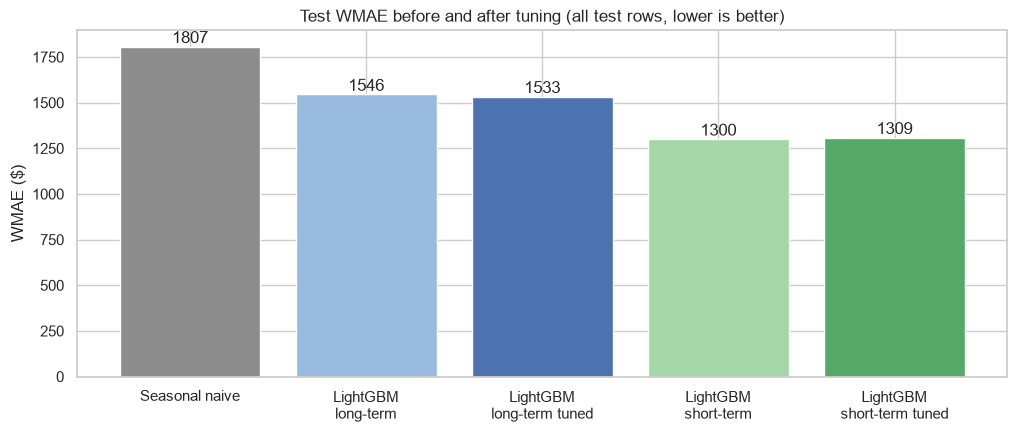

In [65]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Time-series cross-validation with 2 folds inside the training weeks (a shuffled K-fold would let the model learn
# from the future):
#   fold 1: fit on Feb 2010 - Jul 2011, validate on 5 Aug - 28 Oct 2011  (normal weeks, like the test period)
#   fold 2: fit on Feb 2010 - Oct 2011, validate on 4 Nov 2011 - 27 Jan 2012 (Thanksgiving and Christmas)
# The score is the mean validation WMAE. Early stopping on each fold picks the number of trees.
FOLDS = [(pd.Timestamp("2011-08-05"), pd.Timestamp("2011-10-28")), (pd.Timestamp("2011-11-04"), TRAIN_END)]


def make_fold(v_start, v_end):
    fit = train[train["Date"] < v_start].drop(columns="SD_Mean")
    val = train[(train["Date"] >= v_start) & (train["Date"] <= v_end)].drop(columns="SD_Mean")
    fit_mean = fit.groupby(CAT)["Sales"].mean().rename("SD_Mean")     # averages from the fitting weeks only
    return fit.merge(fit_mean, on=CAT, how="left"), val.merge(fit_mean, on=CAT, how="left")


def clean_target(part):
    """Anomaly-cleaned sales for a training period: detector refit on that period only, same keep rules as ML Model 1."""
    X = anomaly_features(part)
    iso = IsolationForest(n_estimators=200, contamination=BEST_CONTAMINATION, max_samples=BEST_MAX_SAMPLES,
                          random_state=SEED, n_jobs=-1)
    flagged = iso.fit_predict(X[BEST_A_FEATURES]) == -1
    season, recurring = seasonal_or_recurring(part, flagged)
    fix = flagged & ~season & ~recurring
    return np.where(fix, X["roll_med"], part["Sales"]), int(fix.sum())


folds = [make_fold(a, b) for a, b in FOLDS]
fold_clean = [clean_target(fit)[0] for fit, _ in folds]


def cv_score(leaves, hol_weight, cleaned):
    wm, trees = [], []
    for (fit, val), y_clean in zip(folds, fold_clean):
        params = {**LGB_PARAMS, "n_estimators": 3000, "num_leaves": leaves, "metric": "l1"}
        m = lgb.LGBMRegressor(**params).fit(
            fit[LONG_FEATURES], y_clean if cleaned else fit["Sales"],
            sample_weight=np.where(fit["IsHoliday"] == 1, 5, 1) if hol_weight else None, categorical_feature=CAT,
            eval_set=[(val[LONG_FEATURES], val["Sales"])], eval_sample_weight=[np.where(val["IsHoliday"] == 1, 5, 1)],
            callbacks=[lgb.early_stopping(50, verbose=False)])
        wm.append(wmae(val["Sales"], m.predict(val[LONG_FEATURES]).clip(0), val["IsHoliday"]))
        trees.append(m.best_iteration_)
    return {"num_leaves": leaves, "holiday_weight": hol_weight, "cleaned_target": cleaned, "fold1_WMAE": wm[0],
            "fold2_WMAE": wm[1], "mean_WMAE": np.mean(wm), "trees": int(np.mean(trees))}


# step 1: tree size x holiday weight (holiday weeks count 5 times in training, as they do in WMAE)
m3_grid = pd.DataFrame([cv_score(l, w, False) for l in [127, 255] for w in [False, True]]).sort_values("mean_WMAE")
print("step 1, grid search on the raw target:")
display(m3_grid.round(1))
best3 = m3_grid.iloc[0]
# step 2: the best setting trained on the anomaly-cleaned target (anomaly handling from ML Model 1)
m3_clean = pd.DataFrame([best3.to_dict(), cv_score(int(best3["num_leaves"]), bool(best3["holiday_weight"]), True)])
print("step 2, raw vs cleaned target with the best setting:")
display(m3_clean.round(1))
best3 = m3_clean.sort_values("mean_WMAE").iloc[0]

BEST_LEAVES, BEST_HOL_WEIGHT, BEST_CLEAN = int(best3["num_leaves"]), bool(best3["holiday_weight"]), bool(best3["cleaned_target"])
FINAL_PARAMS = {**LGB_PARAMS, "num_leaves": BEST_LEAVES, "n_estimators": int(best3["trees"] * 1.1)}   # a bit more data -> a few more trees

# refit on all 104 training weeks with the chosen settings, then test once on the 39 test weeks
train_clean, n_fixed_train = clean_target(train)
y_train = train_clean if BEST_CLEAN else train["Sales"].values
w_train = np.where(train["IsHoliday"] == 1, 5, 1) if BEST_HOL_WEIGHT else None
lgb_tuned = lgb.LGBMRegressor(**FINAL_PARAMS).fit(train[LONG_FEATURES], y_train, sample_weight=w_train, categorical_feature=CAT)
test["LightGBM long-term tuned"] = lgb_tuned.predict(test[LONG_FEATURES]).clip(0)
lgb_short_tuned = lgb.LGBMRegressor(**FINAL_PARAMS).fit(train[SHORT_FEATURES], y_train, sample_weight=w_train, categorical_feature=CAT)
test["LightGBM short-term tuned"] = lgb_short_tuned.predict(test[SHORT_FEATURES]).clip(0)

m3_after = evaluate(test, ["Seasonal naive", "LightGBM long-term", "LightGBM long-term tuned",
                           "LightGBM short-term (1 week ahead)", "LightGBM short-term tuned"])
print(f"chosen: num_leaves = {BEST_LEAVES}, holiday weight = {BEST_HOL_WEIGHT}, cleaned target = {BEST_CLEAN}, "
      f"trees = {FINAL_PARAMS['n_estimators']} (weeks cleaned in training: {n_fixed_train:,})")
display(m3_after.round(3))

fig, ax = plt.subplots(figsize=(12, 4.5))
names = [n.replace(" (1 week ahead)", "").replace("LightGBM ", "LightGBM\n") for n in m3_after.index]
bars = ax.bar(names, m3_after["WMAE"], color=["#8C8C8C", "#9ABBE0", "#4C72B0", "#A5D6A7", "#55A868"])
ax.bar_label(bars, fmt="%.0f")
ax.set_title("Test WMAE before and after tuning (all test rows, lower is better)")
ax.set_ylabel("WMAE ($)")
save_fig(fig, "model3_scores_tuned")
plt.show()

##### Which hyperparameter optimization technique have you used and why?

Time-series cross-validation with a grid search. Inside the 104 training weeks I made two folds that only look forward in time: fold 1 trains on Feb 2010 to Jul 2011 and validates on Aug to Oct 2011 (normal weeks like the test period), and fold 2 trains until Oct 2011 and validates on Nov 2011 to Jan 2012 (Thanksgiving and Christmas). The score is the mean WMAE of the two folds, and early stopping on each fold picks the number of trees. Step 1 searched tree size (127 or 255 leaves) and holiday weighting (holiday weeks count 5 times in training, as in WMAE). Step 2 took the best setting and compared training on the raw sales with training on the anomaly-cleaned sales from ML Model 1.

I used this instead of a random K-fold because a random fold would put future weeks into training. My first attempt validated only on the Nov-Jan weeks with a higher learning rate, and it chose settings that made the test error worse (about 1,594). That taught me the validation period has to look like the period being forecast, so I added the normal-weeks fold.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a small but real improvement for the long-term model:
- Cross-validation: mean WMAE 1,854 with the default 127 leaves and no holiday weight, and 1,805 with 255 leaves and holiday weighting. The holiday weight mainly helped the Christmas fold (2,249 to 2,165).
- The anomaly-cleaned target did not help: it improved fold 1 (1,445 to 1,437) but made the Christmas fold worse (2,165 to 2,199), so the mean went up to 1,818 and the final model is trained on the real sales.
- Test (39 weeks, never used for tuning): WMAE 1,546 to 1,533 and MAE 1,536 to 1,528. RMSE went up a little (3,104 to 3,124), so the tuned model is better on typical weeks and slightly worse on a few big misses.
- The same settings did not help the short-term model (WMAE 1,300 to 1,309). The settings found for the 39-week forecast don't carry over to the one-week forecast, so for weekly replenishment I would keep the untuned short-term model.

The updated chart above shows all versions. The gain from tuning is modest because most of the accuracy comes from the features. Adding the Easter flag, for example, did more (1,573 to 1,546 before tuning) than all the tree settings together.

#### 3. Short-term vs long-term forecasts, and where the errors are

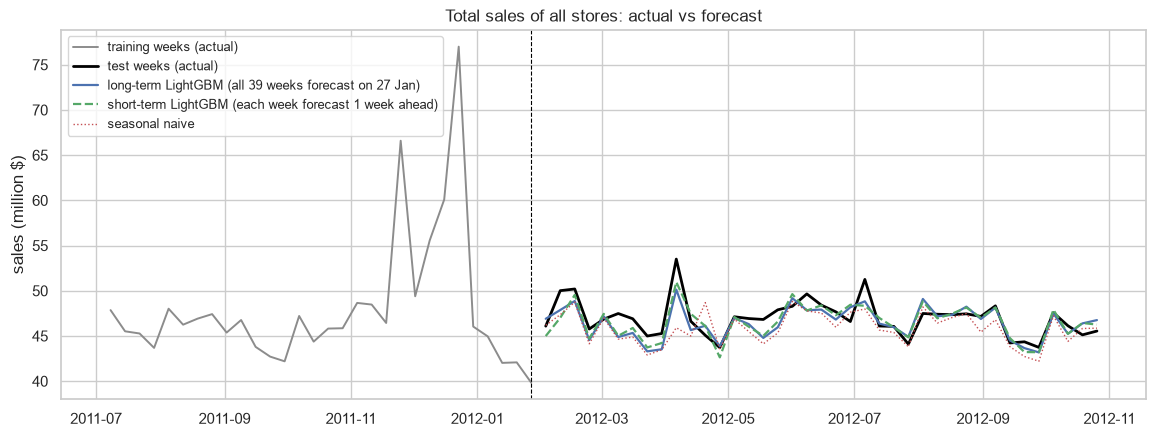

Seasonal naive               error of the chain total per week: mean -2.27%, mean absolute 3.08%
LightGBM long-term tuned     error of the chain total per week: mean -0.98%, mean absolute 2.21%
LightGBM short-term tuned    error of the chain total per week: mean -0.81%, mean absolute 2.17%


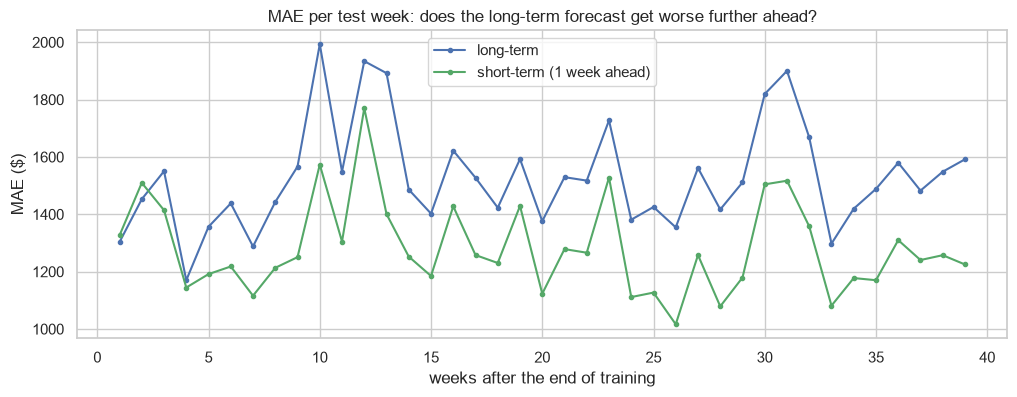

long-term MAE, first 13 weeks: 1,534, middle 13: 1,490, last 13: 1,560


MAE long-term  MAE short-term  avg sales  long-term error % of sales
by week type     holiday week                             1559.7          1434.2    16480.8                         9.5
                 normal week                              1526.3          1274.8    15808.3                         9.7
by store segment 1 Large stores, high-CPI regions         1982.3          1649.0    21500.3                         9.2
                 2 Large stores, low-CPI regions          1755.9          1521.7    18672.8                         9.4
                 3 Mid-size, promotion-driven             1027.8           848.5     8604.3                        11.9
                 4 Small, steady                           827.4           615.4     8831.1                         9.4

In [66]:
FINAL_LONG, FINAL_SHORT = "LightGBM long-term tuned", "LightGBM short-term tuned"
tot = test.groupby("Date")[["Sales", "Seasonal naive", FINAL_LONG, FINAL_SHORT]].sum() / 1e6
history = weekly_total.loc[(weekly_total.index > "2011-07-01") & (weekly_total.index <= TRAIN_END), "Sales"] / 1e6

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(history.index, history.values, color="#8C8C8C", lw=1.4, label="training weeks (actual)")
ax.plot(tot.index, tot["Sales"], color="black", lw=2, label="test weeks (actual)")
ax.plot(tot.index, tot[FINAL_LONG], color="#4C72B0", lw=1.6, label="long-term LightGBM (all 39 weeks forecast on 27 Jan)")
ax.plot(tot.index, tot[FINAL_SHORT], color="#55A868", lw=1.6, ls="--", label="short-term LightGBM (each week forecast 1 week ahead)")
ax.plot(tot.index, tot["Seasonal naive"], color="#C44E52", lw=1, ls=":", label="seasonal naive")
ax.axvline(TRAIN_END, color="black", lw=0.8, ls="--")
ax.set_title("Total sales of all stores: actual vs forecast")
ax.set_ylabel("sales (million $)")
ax.legend(fontsize=9, loc="upper left")
save_fig(fig, "model3_total_forecast")
plt.show()
for c in ["Seasonal naive", FINAL_LONG, FINAL_SHORT]:
    err = 100 * (tot[c] - tot["Sales"]) / tot["Sales"]
    print(f"{c:28} error of the chain total per week: mean {err.mean():+.2f}%, mean absolute {err.abs().mean():.2f}%")

# error by how far ahead the week is, and holiday vs normal weeks
test["Weeks_Ahead"] = test["Date"].rank(method="dense").astype(int)
by_h = test.groupby("Weeks_Ahead").apply(lambda g: pd.Series({c: np.mean(np.abs(g["Sales"] - g[c])) for c in [FINAL_LONG, FINAL_SHORT]}))
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(by_h.index, by_h[FINAL_LONG], marker="o", ms=3, color="#4C72B0", label="long-term")
ax.plot(by_h.index, by_h[FINAL_SHORT], marker="o", ms=3, color="#55A868", label="short-term (1 week ahead)")
ax.set_title("MAE per test week: does the long-term forecast get worse further ahead?")
ax.set_xlabel("weeks after the end of training")
ax.set_ylabel("MAE ($)")
ax.legend()
save_fig(fig, "model3_error_by_horizon")
plt.show()
print(f"long-term MAE, first 13 weeks: {by_h[FINAL_LONG].iloc[:13].mean():,.0f}, middle 13: {by_h[FINAL_LONG].iloc[13:26].mean():,.0f}, "
      f"last 13: {by_h[FINAL_LONG].iloc[26:].mean():,.0f}")

seg_of_store = store_profile["Segment_Name"]
test["Segment_Name"] = test["Store"].map(seg_of_store)
err_table = pd.concat({
    "by week type": test.groupby(np.where(test["IsHoliday"] == 1, "holiday week", "normal week")).apply(
        lambda g: pd.Series({"MAE long-term": np.mean(np.abs(g["Sales"] - g[FINAL_LONG])), "MAE short-term": np.mean(np.abs(g["Sales"] - g[FINAL_SHORT])),
                             "avg sales": g["Sales"].mean()})),
    "by store segment": test.groupby("Segment_Name").apply(
        lambda g: pd.Series({"MAE long-term": np.mean(np.abs(g["Sales"] - g[FINAL_LONG])), "MAE short-term": np.mean(np.abs(g["Sales"] - g[FINAL_SHORT])),
                             "avg sales": g["Sales"].mean()}))})
err_table["long-term error % of sales"] = 100 * err_table["MAE long-term"] / err_table["avg sales"]
display(err_table.round(1))

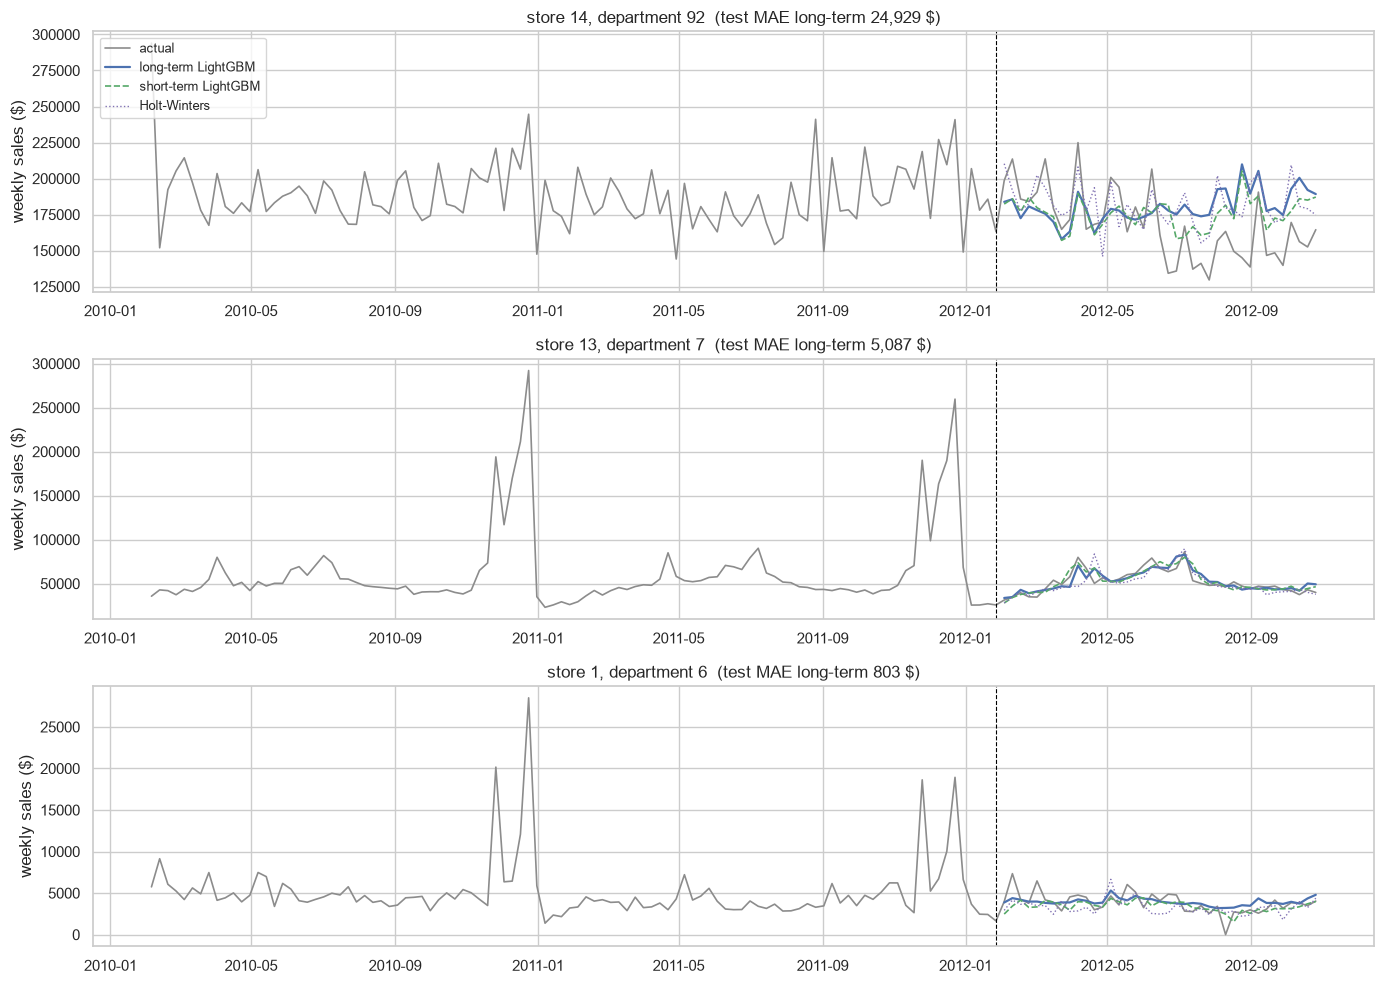

In [67]:
# three example series: the biggest one, a strongly seasonal one and a small one
sizes = df.groupby(CAT)["Sales"].sum()
seasonal_dept = swing.index[0]
examples = [sizes.idxmax(),
            df[df["Dept"] == seasonal_dept].groupby(CAT)["Sales"].sum().idxmax(),
            sizes[(sizes > sizes.quantile(0.4)) & (sizes < sizes.quantile(0.5))].index[0]]
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
for ax, (st, dp) in zip(axes, examples):
    hist = df[(df["Store"] == st) & (df["Dept"] == dp)]
    fc = test[(test["Store"] == st) & (test["Dept"] == dp)]
    ax.plot(hist["Date"], hist["Sales"], color="#8C8C8C", lw=1.2, label="actual")
    ax.plot(fc["Date"], fc[FINAL_LONG], color="#4C72B0", lw=1.6, label="long-term LightGBM")
    ax.plot(fc["Date"], fc[FINAL_SHORT], color="#55A868", lw=1.2, ls="--", label="short-term LightGBM")
    if fc["Holt-Winters"].notna().all():
        ax.plot(fc["Date"], fc["Holt-Winters"], color="#8172B3", lw=1, ls=":", label="Holt-Winters")
    ax.axvline(TRAIN_END, color="black", lw=0.8, ls="--")
    ax.set_title(f"store {st}, department {dp}  (test MAE long-term {np.mean(np.abs(fc['Sales'] - fc[FINAL_LONG])):,.0f} $)")
    ax.set_ylabel("weekly sales ($)")
axes[0].legend(fontsize=9, loc="upper left")
plt.tight_layout()
save_fig(fig, "model3_example_series")
plt.show()

For the chain as a whole the forecasts are close: the total weekly sales are off by 2.21% on average for the long-term model, 2.17% for the short-term model and 3.08% for the seasonal naive. All three slightly under-forecast (the long-term model by 0.98% on average) because 2012 grew a bit compared with 2011.

The long-term model does not get worse further ahead. The MAE is 1,534 in the first 13 weeks, 1,490 in the middle 13 and 1,560 in the last 13, because it relies on last year's same week and the calendar, not on the most recent weeks. The worst single week is still week 10, 6 Apr 2012, the Easter week. The Easter flag lowered the overall error, but the model has only seen two Easters, which is not enough to learn the Easter effect of every department. Late April (weeks 12-13) and the end of August (weeks 30-31, back to school) are the other weak spots.

Errors by type of week and store segment (long-term model):
- Holiday weeks: MAE 1,560 (9.5% of the average sales), normal weeks 1,526 (9.7%), so the holiday weighting did its job.
- The promotion-driven segment 3 is the hardest to forecast (11.9% of sales), while the other segments are at 9.2-9.4%. This matches the segmentation: volatile stores need bigger safety stocks.

The three example series show the forecast follows the level and the seasonal shape well: the biggest series (store 14, department 92, MAE about 24,900 $ on sales of around 180,000 $ a week), a strongly seasonal department (store 13, department 7, MAE 5,087 $) and a small one (store 1, department 6, MAE 803 $).

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

- Forecasting: WMAE (mean absolute error in dollars, with holiday weeks counted 5 times) as the main metric, with MAE, RMSE and the error of the chain total as extra checks. Dollars are what the business loses when it over-stocks or runs out, and the biggest departments matter most, so a percentage error would not fit. Holiday weeks get more weight because an error there costs the most in lost sales or left-over stock.
- Anomaly detection: precision (how many alerts are real), recall (how many problems are found) and F1. Too many alerts and nobody checks them, too few and the problems are missed.
- Segmentation: silhouette, Davies-Bouldin and bootstrap stability, because segments need to be clearly different and stay stable to be used for planning.
- Market basket: support, confidence and lift, because a cross-selling idea is only worth it if the link is frequent, reliable and stronger than chance.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

- Forecasting: the tuned long-term LightGBM (255 leaves, holiday weeks weighted 5 times, trained on the real sales). It had the lowest error of the models that can forecast months ahead: test WMAE 1,533 on all test rows against 1,807 for the seasonal naive, and on the series with full history the long-term LightGBM also beat Holt-Winters (1,665 against 1,803). One global model covers all 3,331 series, including new and incomplete ones that Holt-Winters can't handle, and it uses the holidays, Easter and the external factors. For next week's replenishment the untuned short-term LightGBM (WMAE 1,300) is the better tool, used next to it.
- Anomaly detection: the tuned Isolation Forest (F1 0.552 against 0.480 for the best z-score rule).
- Segmentation: KMeans with 4 segments on 4 features (silhouette 0.415, stability 0.82).

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

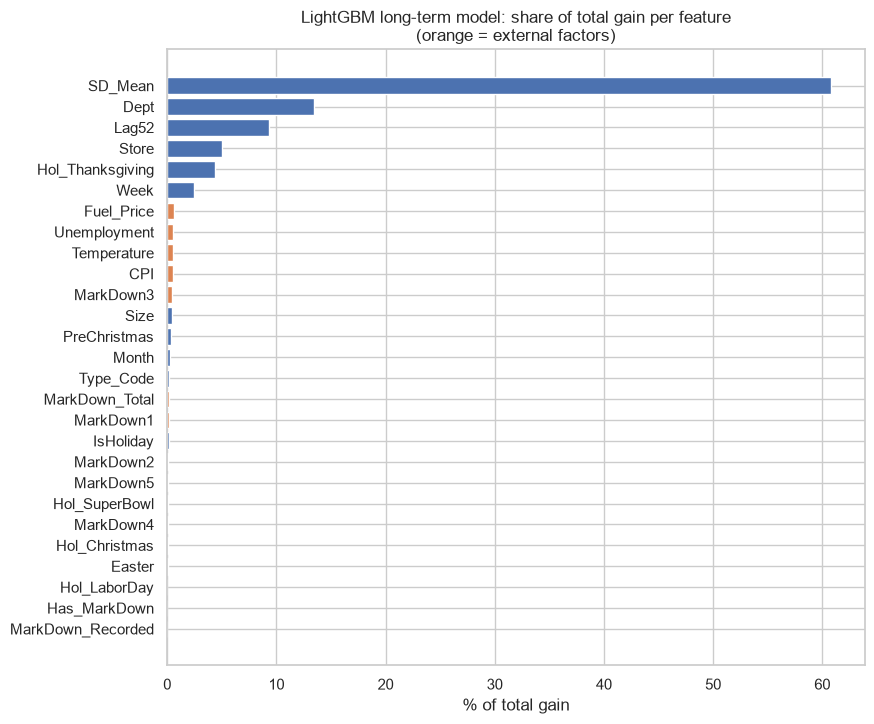

SD_Mean             60.84
Dept                13.48
Lag52                9.36
Store                4.98
Hol_Thanksgiving     4.34
Week                 2.43
Fuel_Price           0.61
Unemployment         0.56
Temperature          0.53
CPI                  0.51

external factors together: 3.2% of the gain


In [68]:
# feature importance of the final long-term model: total gain (how much each feature lowered the error)
imp = pd.Series(lgb_tuned.booster_.feature_importance(importance_type="gain"), index=LONG_FEATURES)
imp = (100 * imp / imp.sum()).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 8))
colors = ["#DD8452" if f in EXTERNAL else "#4C72B0" for f in imp.index]
ax.barh(imp.index, imp.values, color=colors)
ax.set_title("LightGBM long-term model: share of total gain per feature\n(orange = external factors)")
ax.set_xlabel("% of total gain")
save_fig(fig, "model3_feature_importance")
plt.show()
print(imp.sort_values(ascending=False).round(2).head(10).to_string())
print(f"\nexternal factors together: {imp[[f for f in imp.index if f in EXTERNAL]].sum():.1f}% of the gain")

LightGBM is an ensemble of decision trees built one after the other, each new tree correcting the errors left by the previous ones. One model learns from all store-departments together, so a small department can borrow the seasonal pattern of similar ones, and Store and Dept are treated as categories.

Feature importance (share of the total gain, chart above):
- SD_Mean, the normal level of the store-department, is the most important (61%). The first thing a forecast needs is how big the department is in that store.
- Dept (13.5%) and Lag52, the same week last year (9.4%), bring the seasonal shape.
- Hol_Thanksgiving (4.3%) and Week (2.4%) handle the timing of the peaks.
- The external factors together give 3.2% of the gain, led by fuel price, unemployment, temperature and CPI.

Permutation importance on the test weeks (section 7.2) gives the same order: shuffling SD_Mean raises the MAE by about 10,800 $, Lag52 by 5,100 $ and Dept by 1,200 $, while temperature (83 $), unemployment (41 $), the Easter flag (39 $) and CPI (24 $) have small but real effects. So the model mostly says "this department in this store, shaped like the same week last year, adjusted for holidays", with small corrections for the economy and the weather, which is a sensible logic for a store manager to trust.

## ***7.1 Market Basket Analysis (inferred product associations)***

There is no customer transaction data (no receipts), so a classic market basket analysis is not possible. I used the weekly department sales instead:
- Each store-week is treated as a "basket" (6,435 baskets).
- A department is "in the basket" when it took a bigger share of the store's sales than usual that week, meaning it was in the top 25% of its own weeks in that store. I used the share and not the raw sales, because in December the whole store is busy and every department would look hot at once.
- Apriori then finds groups of departments that are often hot together, and association rules measure each link: support (how often the group is hot together), confidence (when A is hot, how often B is hot too) and lift (how much more often than if they were independent).

This shows which departments gain together, which is the closest available signal to "customers buy these together". It is an inference from sales patterns and not proof that the same customers bought both.

In [69]:
# Each store-week is a "basket". A department is in the basket when it took a bigger share of the store's sales
# than usual (top 25% of its own weeks in that store). Using the share, not the sales, removes the effect of the
# whole store being busy (e.g. in December lifts every department), so what is left are departments that gain together.
sd_wide = df.pivot_table(index=["Store", "Date"], columns="Dept", values="Sales")
dept_share_wk = sd_wide.div(sd_wide.sum(axis=1), axis=0)
q75 = dept_share_wk.groupby(level="Store").transform(lambda c: c.quantile(0.75))
hot = (dept_share_wk > q75) & dept_share_wk.notna()
hot = hot.loc[:, hot.mean() > 0.05]            # drop departments that are almost never in a basket
hot.columns = [f"D{c}" for c in hot.columns]
print(f"baskets (store-weeks): {hot.shape[0]:,}, departments: {hot.shape[1]}, "
      f"average hot departments per basket: {hot.sum(axis=1).mean():.1f}")

baskets (store-weeks): 6,435, departments: 74, average hot departments per basket: 16.4


In [70]:
itemsets = apriori(hot, min_support=0.10, use_colnames=True, max_len=3)
rules = association_rules(itemsets, metric="lift", min_threshold=1.5)
rules = rules[rules["confidence"] >= 0.6].sort_values("lift", ascending=False).reset_index(drop=True)
rules["rule"] = (rules["antecedents"].apply(lambda s: " + ".join(sorted(s))) + "  ->  "
                 + rules["consequents"].apply(lambda s: " + ".join(sorted(s))))
print(f"frequent itemsets: {len(itemsets)}, rules with lift >= 1.5 and confidence >= 0.6: {len(rules)}")

# peak month of each department, to understand why two departments move together
dept_peak = df.groupby(["Dept", "Month"])["Sales"].mean().unstack().idxmax(axis=1)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
rules["peak months"] = rules.apply(lambda r: ", ".join(f"{d}:{MONTHS[dept_peak[int(d[1:])] - 1]}"
                                                       for d in sorted(r["antecedents"] | r["consequents"])), axis=1)
display(rules[["rule", "support", "confidence", "lift", "peak months"]].head(15).round(3))
rules[["rule", "support", "confidence", "lift", "peak months"]].to_csv("outputs/association_rules.csv", index=False)
print("saved outputs/association_rules.csv")

frequent itemsets: 179, rules with lift >= 1.5 and confidence >= 0.6: 17


,rule,support,confidence,lift,peak months
0,D31 + D33 -> D24,0.108,0.884,4.176,"D24:Dec, D31:Aug, D33:Dec"
1,D24 + D31 -> D33,0.108,0.852,4.041,"D24:Dec, D31:Aug, D33:Dec"
2,D24 -> D33,0.160,0.756,3.586,"D24:Dec, D33:Dec"
3,D33 -> D24,0.160,0.759,3.586,"D24:Dec, D33:Dec"
4,D5 + D72 -> D55,0.102,0.747,3.407,"D5:Dec, D55:Dec, D72:Nov"
5,D55 + D72 -> D5,0.102,0.811,3.267,"D5:Dec, D55:Dec, D72:Nov"
6,D91 + D92 -> D90,0.101,0.822,3.266,"D90:Dec, D91:Feb, D92:Nov"
7,D90 + D91 -> D92,0.101,0.758,3.009,"D90:Dec, D91:Feb, D92:Nov"
8,D5 + D55 -> D72,0.102,0.683,2.887,"D5:Dec, D55:Dec, D72:Nov"
9,D18 -> D1,0.140,0.715,2.839,"D1:Dec, D18:Dec"


saved outputs/association_rules.csv


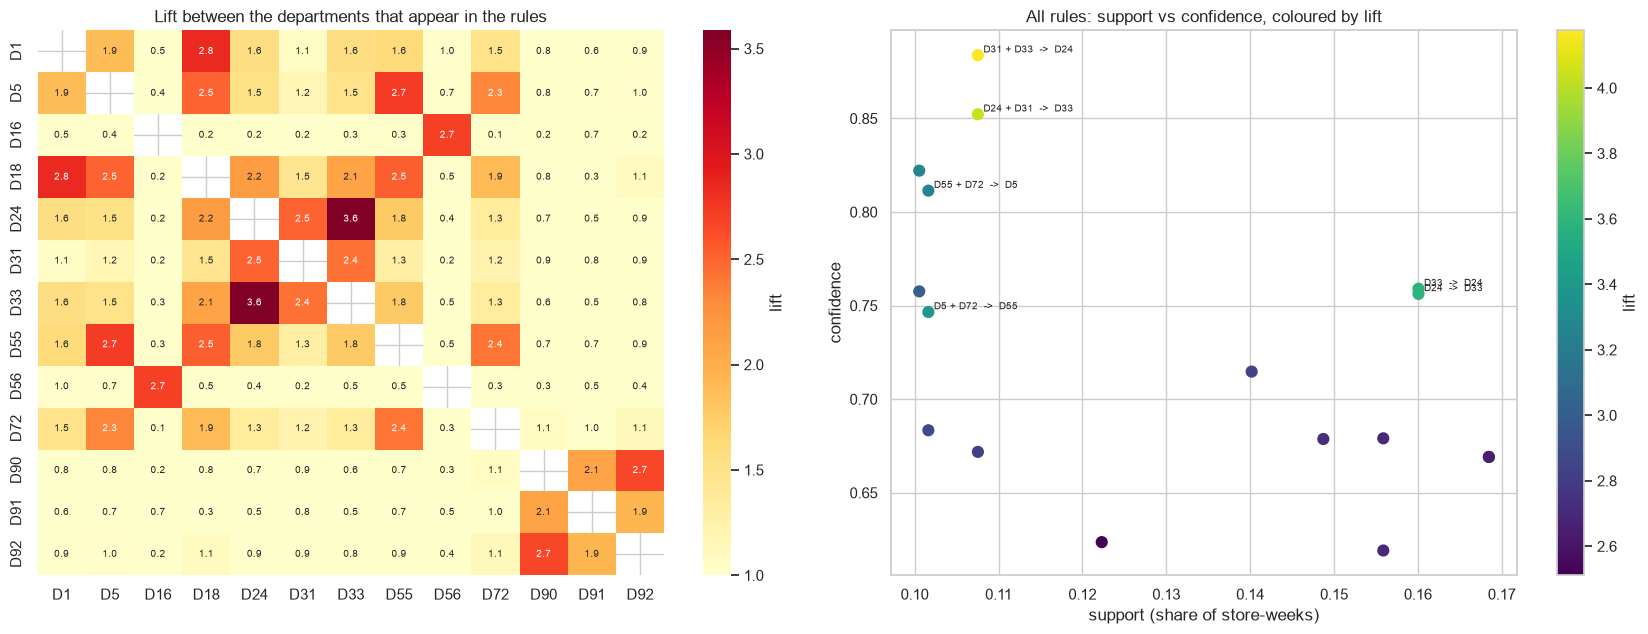

In [71]:
# lift between every pair of departments that appears in a rule (1 = no link, above 1 = hot together more than chance)
in_rules = sorted({d for s in rules["antecedents"] for d in s} | {d for s in rules["consequents"] for d in s},
                  key=lambda d: int(d[1:]))
p = hot[in_rules].mean()
both = hot[in_rules].astype(int).T.dot(hot[in_rules].astype(int)) / len(hot)
lift_pairs = (both / np.outer(p, p)).mask(np.eye(len(in_rules), dtype=bool))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(lift_pairs, cmap="YlOrRd", vmin=1, annot=True, fmt=".1f", annot_kws={"fontsize": 7}, ax=axes[0],
            cbar_kws={"label": "lift"})
axes[0].set_title("Lift between the departments that appear in the rules")
sc = axes[1].scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=60)
for _, r in rules.head(6).iterrows():
    axes[1].annotate(r["rule"], (r["support"], r["confidence"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
plt.colorbar(sc, ax=axes[1], label="lift")
axes[1].set_xlabel("support (share of store-weeks)")
axes[1].set_ylabel("confidence")
axes[1].set_title("All rules: support vs confidence, coloured by lift")
plt.tight_layout()
save_fig(fig, "market_basket_rules")
plt.show()

With minimum support 10%, confidence 60% and lift 1.5, there are 17 rules, forming five groups of departments:
- 24, 33 and 31: the strongest group. When 31 and 33 are hot, 24 is hot 88% of the time (lift 4.2). 24 and 33 peak in December and 31 in August, so this group is linked all year, not only at Christmas.
- 5, 55 and 72: when 55 and 72 are hot, 5 is hot 81% of the time (lift 3.3). All three peak in November-December, and 72 is one of the biggest departments (4.5% of sales).
- 90, 91 and 92: when 91 and 92 are hot, 90 is hot 82% of the time (lift 3.3). These are three of the biggest and steadiest departments (92 alone is 7.2% of sales), so this looks like a core everyday basket.
- 18 and 1: when 18 is hot, 1 is hot 72% of the time (lift 2.8).
- 16 and 56: they peak in June and May (lift 2.7), a spring and summer group.

Cross-selling strategies from these links:
- Put linked departments next to each other or on the same end-cap and in the same flyer, for example 24 with 33, and 5 with 55 and 72 before the holidays.
- Promote one department of a group and use the link to pull the others: a discount on the high-traffic 92 can bring shoppers to 90 and 91 without discounting all three.
- Plan stock for a group together. When the first department of a group starts to rise, raise the orders for the others too (for 16 and 56 from April).
- Avoid giving markdowns to two departments of the same group in the same week, since they already sell together.

The department names are anonymised, so these strategies are described by number. With real transaction data the same method would give customer-level rules.

## ***7.2 Impact of External Factors***

In [72]:
# 1. ablation: the tuned long-term model trained again with and without the external factors
ECON_WEATHER = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]
MD_FEATURES = MARKDOWN_COLS + ["MarkDown_Total", "Has_MarkDown", "MarkDown_Recorded"]
NO_EXTERNAL = [f for f in LONG_FEATURES if f not in ECON_WEATHER + MD_FEATURES]
variants = {"no external factors": NO_EXTERNAL, "+ economy and weather": NO_EXTERNAL + ECON_WEATHER,
            "+ markdowns": NO_EXTERNAL + MD_FEATURES, "+ all external factors (final model)": LONG_FEATURES}
rows = []
for name, feats in variants.items():
    if feats is LONG_FEATURES:
        pred = test[FINAL_LONG].values
    else:
        m = lgb.LGBMRegressor(**FINAL_PARAMS).fit(train[feats], y_train, sample_weight=w_train, categorical_feature=CAT)
        pred = m.predict(test[feats]).clip(0)
    hol = test["IsHoliday"].values == 1
    rows.append({"model": name, "test WMAE": wmae(test["Sales"], pred, test["IsHoliday"]),
                 "MAE holiday weeks": np.mean(np.abs(test["Sales"].values[hol] - pred[hol])),
                 "MAE normal weeks": np.mean(np.abs(test["Sales"].values[~hol] - pred[~hol]))})
ablation = pd.DataFrame(rows).set_index("model")
ablation["change vs no external (%)"] = 100 * (ablation["test WMAE"] / ablation.loc["no external factors", "test WMAE"] - 1)
display(ablation.round(2))

,test WMAE,MAE holiday weeks,MAE normal weeks,change vs no external (%)
model,,,,
no external factors,1620.70,1701.66,1598.66,0.00
+ economy and weather,1563.89,1663.72,1536.72,-3.50
+ markdowns,1542.41,1560.67,1537.44,-4.83
+ all external factors (final model),1533.42,1559.71,1526.26,-5.39


MAE increase ($) when a feature is shuffled, top 12:
SD_Mean         10823.0
Lag52            5142.4
Dept             1216.1
Store             395.3
Week              187.3
Temperature        83.0
Unemployment       41.3
Easter             39.4
CPI                24.2
Size               18.8
Type_Code          17.8
Fuel_Price          9.7

external factors:
Temperature          83.0
Unemployment         41.3
CPI                  24.2
Fuel_Price            9.7
MarkDown5             4.8
MarkDown1             4.0
MarkDown4             2.5
MarkDown3             0.7
MarkDown2             0.5
MarkDown_Total        0.5
Has_MarkDown          0.0
MarkDown_Recorded     0.0


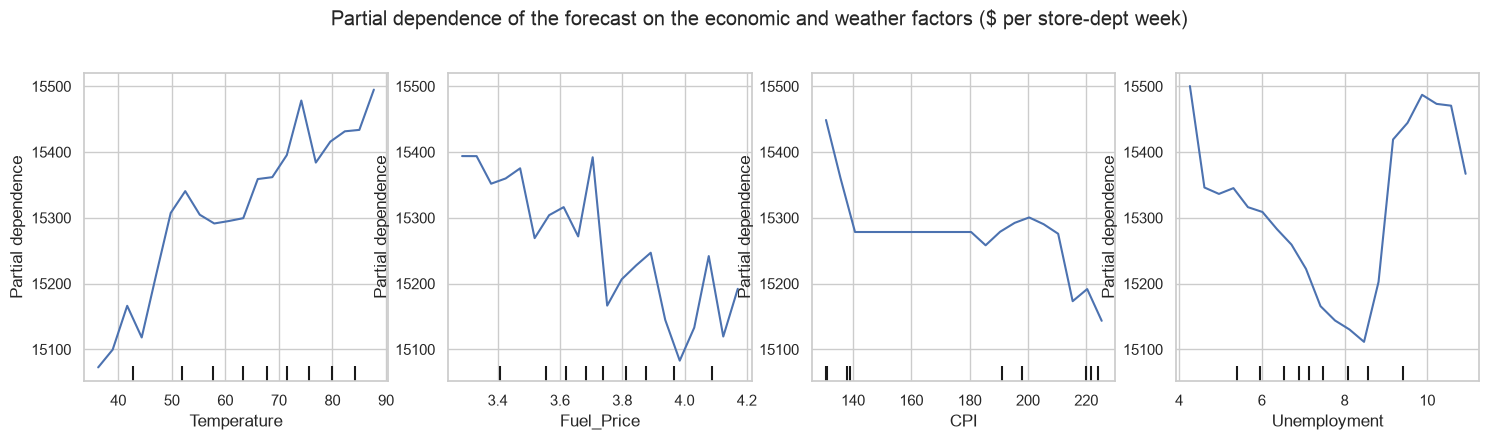

In [73]:
# 2. permutation importance on 20,000 test rows: how much worse the forecast gets when one feature is shuffled
sample_te = test.sample(20000, random_state=SEED)
perm = permutation_importance(lgb_tuned, sample_te[LONG_FEATURES], sample_te["Sales"], scoring="neg_mean_absolute_error",
                              n_repeats=3, random_state=SEED, n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=LONG_FEATURES).sort_values(ascending=False)
print("MAE increase ($) when a feature is shuffled, top 12:")
print(perm_imp.head(12).round(1).to_string())
print("\nexternal factors:")
print(perm_imp[[f for f in perm_imp.index if f in EXTERNAL]].round(1).to_string())

# 3. partial dependence: average forecast while one external factor moves and everything else stays the same
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
PartialDependenceDisplay.from_estimator(lgb_tuned, sample_te[LONG_FEATURES].sample(3000, random_state=SEED),
                                        ECON_WEATHER, kind="average", grid_resolution=20, ax=axes)
fig.suptitle("Partial dependence of the forecast on the economic and weather factors ($ per store-dept week)", y=1.04)
save_fig(fig, "external_partial_dependence")
plt.show()

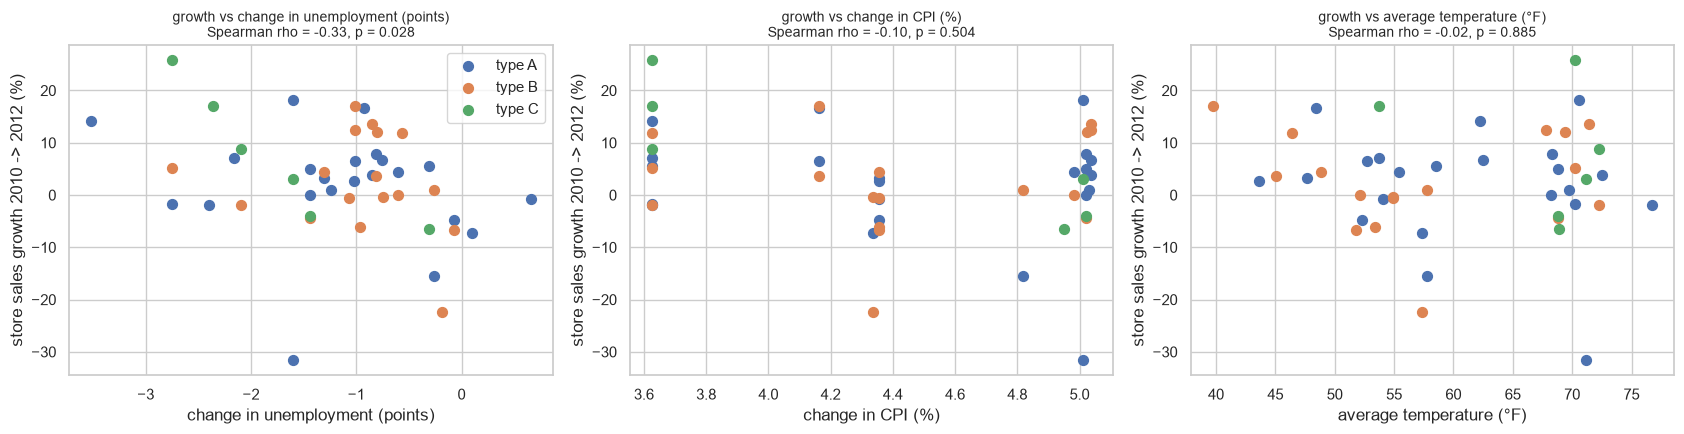

In [74]:
# 4. regional view: did stores in regions where unemployment fell (or prices rose) grow more?
first_39 = store_week[(store_week["Date"] >= "2010-02-05") & (store_week["Date"] <= "2010-10-29")].groupby("Store")
last_39 = store_week[(store_week["Date"] >= "2012-02-03") & (store_week["Date"] <= "2012-10-26")].groupby("Store")
regional = pd.DataFrame({"Growth_%": 100 * store_profile["Growth"],
                         "Unemp_Change": last_39["Unemployment"].mean() - first_39["Unemployment"].mean(),
                         "CPI_Change_%": 100 * (last_39["CPI"].mean() / first_39["CPI"].mean() - 1),
                         "Temperature": store_profile["Temperature"], "Type": store_profile["Type"]})
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, label in zip(axes, ["Unemp_Change", "CPI_Change_%", "Temperature"],
                          ["change in unemployment (points)", "change in CPI (%)", "average temperature (°F)"]):
    for t, g in regional.groupby("Type"):
        ax.scatter(g[col], g["Growth_%"], color=TYPE_COLORS[t], label=f"type {t}", s=50)
    rho, pv = stats.spearmanr(regional[col], regional["Growth_%"])
    ax.set_title(f"growth vs {label}\nSpearman rho = {rho:.2f}, p = {pv:.3f}", fontsize=10)
    ax.set_xlabel(label)
    ax.set_ylabel("store sales growth 2010 -> 2012 (%)")
axes[0].legend()
plt.tight_layout()
save_fig(fig, "external_regional_growth")
plt.show()

How the external factors affect sales:
- In the forecast (ablation): with no external factors the tuned long-term model has a test WMAE of 1,621. Adding the economy and weather (temperature, fuel, CPI, unemployment) lowers it to 1,564 (-3.5%), adding the markdowns lowers it to 1,542 (-4.8%), and the final model with all of them reaches 1,533 (-5.4%). The markdowns help most in holiday weeks (MAE 1,702 to 1,561), and the economy and weather in normal weeks (1,599 to 1,537).
- Importance: shuffling temperature raises the MAE by 83 $, unemployment by 41 $, CPI by 24 $ and fuel price by 10 $. Each markdown column adds 5 $ or less. Together the external factors are 3.2% of the model's gain.
- Direction (partial dependence): the forecast rises by about 3% from cold to hot weeks, falls by about 2% when fuel prices are high, and is about 1% lower in the highest-CPI areas. Unemployment has a U-shape, which comes from a few specific high-unemployment stores rather than a general rule.
- Between regions: stores whose region's unemployment fell the most grew the most (Spearman rho -0.33, p = 0.028). The change in CPI (rho -0.10) and the temperature (rho -0.02) are not linked to growth. Combined with Hypothesis 3, unemployment does not set the level of a store's sales, but changes in unemployment move its growth.

All these insights are already built into the forecasting model: the economic, weather and markdown features stay in the final model because they improve it by about 5%. They are secondary drivers, though. Store, department, season and holidays explain far more than the economy, so in a downturn the chain should expect slower growth, not a different seasonal pattern.

## ***7.3 Personalization and Inventory Strategies***

In [75]:
# 1. do markdowns work the same way in every segment? (Feb-Oct 2012, normal weeks, growth vs same week last year)
mdp = md_period.merge(store_profile[["Segment_Name"]], left_on="Store", right_index=True)
resp = mdp.groupby(["Segment_Name", "MD_Level"], observed=True)["YoY_Growth"].median().unstack()
resp["highest - lowest (points)"] = resp["highest 25%"] - resp["lowest 25%"]
print("median year-over-year growth (%) by markdown level within the store:")
display(resp.round(2))

# which markdown type goes with growth, per segment (Spearman of the within-store rank of each markdown with growth)
corr_md = {}
for seg, g in mdp.groupby("Segment_Name"):
    corr_md[seg] = {c: stats.spearmanr(g.groupby("Store")[c].rank(pct=True), g["YoY_Growth"])[0] for c in MARKDOWN_COLS}
display(pd.DataFrame(corr_md).T.round(3))

median year-over-year growth (%) by markdown level within the store:


MD_Level,lowest 25%,25-50%,50-75%,highest 25%,highest - lowest (points)
Segment_Name,,,,,
"1 Large stores, high-CPI regions",2.92,4.20,4.65,2.85,-0.07
"2 Large stores, low-CPI regions",1.44,2.82,3.50,2.02,0.58
"3 Mid-size, promotion-driven",1.01,3.69,3.80,3.17,2.16
"4 Small, steady",3.23,4.46,4.43,2.79,-0.44


,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
"1 Large stores, high-CPI regions",0.036,-0.090,0.023,0.057,0.100
"2 Large stores, low-CPI regions",0.042,-0.057,0.012,0.024,0.144
"3 Mid-size, promotion-driven",0.148,-0.063,0.074,0.037,0.058
"4 Small, steady",-0.037,0.108,-0.014,-0.151,0.037


In [76]:
# 2. department mix of each segment: which departments sell more (index > 1) than in the chain as a whole
seg_dept = (df.merge(store_profile[["Segment_Name"]], left_on="Store", right_index=True)
              .groupby(["Segment_Name", "Dept"])["Sales"].sum())
seg_share = seg_dept / seg_dept.groupby(level=0).transform("sum")
chain_share = df.groupby("Dept")["Sales"].sum() / df["Sales"].sum()
mix_index = seg_share.unstack(0).div(chain_share, axis=0)
big = chain_share[chain_share > 0.005].index          # departments with at least 0.5% of chain sales
for seg in mix_index.columns:
    col = mix_index.loc[big, seg].sort_values(ascending=False)
    print(f"{seg:36} over-index: {', '.join(f'D{d} ({v:.2f})' for d, v in col.head(4).items())} | "
          f"under-index: {', '.join(f'D{d} ({v:.2f})' for d, v in col.tail(3).items())}")

1 Large stores, high-CPI regions     over-index: D93 (1.32), D98 (1.28), D94 (1.25), D91 (1.24) | under-index: D24 (0.84), D38 (0.84), D23 (0.82)
2 Large stores, low-CPI regions      over-index: D33 (1.21), D26 (1.21), D24 (1.21), D23 (1.19) | under-index: D98 (0.81), D93 (0.78), D94 (0.78)
3 Mid-size, promotion-driven         over-index: D38 (1.66), D11 (1.49), D9 (1.48), D25 (1.46) | under-index: D93 (0.05), D94 (0.05), D80 (0.03)
4 Small, steady                      over-index: D96 (3.15), D94 (2.72), D80 (2.56), D98 (2.40) | under-index: D24 (0.00), D33 (0.00), D34 (0.00)


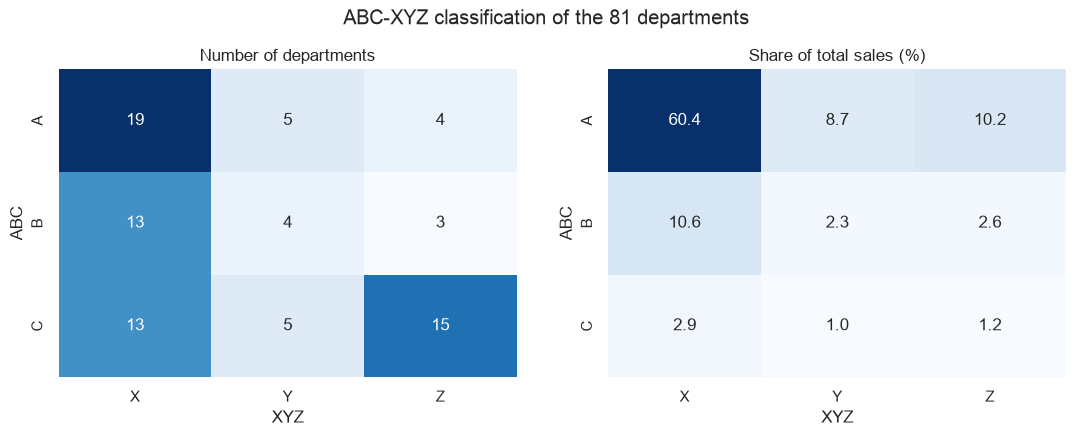

AX: 19 departments, e.g. [92, 95, 38, 90, 40, 2, 91, 13]
AY:  5 departments, e.g. [23, 9, 1, 82, 14]
AZ:  4 departments, e.g. [72, 7, 5, 16]
BZ:  3 departments, e.g. [3, 55, 18]
CZ: 15 departments, e.g. [6, 56, 36, 41, 59, 48, 54, 99]


In [77]:
# 3. ABC-XYZ classification of the departments for inventory planning
#    ABC = how much of the sales (A = top 80%, B = next 15%, C = last 5%)
#    XYZ = how predictable the weekly sales are (coefficient of variation: X < 0.25, Y < 0.5, Z above)
dept_week = df.groupby(["Date", "Dept"])["Sales"].sum().unstack().fillna(0)
abc = pd.DataFrame({"total": dept_week.sum(), "cv": dept_week.std() / dept_week.mean()}).sort_values("total", ascending=False)
abc["cum_share"] = abc["total"].cumsum() / abc["total"].sum()
abc["ABC"] = np.where(abc["cum_share"] <= 0.80, "A", np.where(abc["cum_share"] <= 0.95, "B", "C"))
abc["XYZ"] = pd.cut(abc["cv"], [-np.inf, 0.25, 0.5, np.inf], labels=["X", "Y", "Z"]).astype(str)
abc["class"] = abc["ABC"] + abc["XYZ"]
count = pd.crosstab(abc["ABC"], abc["XYZ"])
share = abc.pivot_table(index="ABC", columns="XYZ", values="total", aggfunc="sum").fillna(0) / abc["total"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(count, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Number of departments")
sns.heatmap(share, annot=True, fmt=".1f", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set_title("Share of total sales (%)")
fig.suptitle("ABC-XYZ classification of the 81 departments", y=1.03)
save_fig(fig, "inventory_abc_xyz")
plt.show()
for cls in ["AX", "AY", "AZ", "BZ", "CZ"]:
    depts = abc.index[abc["class"] == cls].tolist()
    print(f"{cls}: {len(depts):2} departments, e.g. {depts[:8]}")
abc.round(3).to_csv("outputs/department_abc_xyz.csv")

Markdowns by segment: in normal weeks, the growth in a store's highest-markdown weeks compared with its lowest-markdown weeks is:
- +2.2 points in segment 3 (mid-size, promotion-driven), the only segment with a clear positive response. MarkDown1 has the strongest link there (rho 0.15).
- +0.6 points in segment 2.
- about zero or negative in segment 1 (-0.1) and segment 4 (-0.4).
Across the segments, medium markdown weeks do better than the biggest ones, and MarkDown5 is the most positive type for the large stores (rho 0.10 and 0.14), while MarkDown2 is slightly negative in three of the four segments.

Department mix by segment (index = share in the segment / share in the chain):
- Segment 1 sells more of departments 93, 98, 94 and 91 (1.24-1.32).
- Segment 2 sells more of 33, 26, 24 and 23 (about 1.2), the Christmas group.
- Segment 3 sells much more of 38 (1.66), 11, 9 and 25 (about 1.5), and almost none of 93, 94 and 80.
- Segment 4 sells far more of 96 (3.15), 94 (2.72), 80 and 98, and does not carry 24, 33 and 34 at all.

ABC-XYZ inventory classes of the 81 departments:
- AX: 19 departments with 60.4% of sales that are big and steady (92, 95, 38, 90, 40, 2, 91, 13, ...).
- AY: 5 departments (8.7%), big with a medium swing (23, 9, 1, 82, 14).
- AZ: 4 departments (10.2%), big but very seasonal (72, 7, 5, 16).
- CZ: 15 departments (1.2%), small and erratic (6, 56, 36, 41, 59, 48, 54, 99, ...).

Personalised marketing and inventory strategies per segment:

| Segment | Marketing | Inventory |
|---|---|---|
| 1 Large, high-CPI | cut the biggest markdowns (no extra growth), keep medium MarkDown5-type promotions, feature 91-98 | big holiday build-up (Q4 +17%), automatic replenishment for AX departments |
| 2 Large, low-CPI | price-sensitive region: everyday low prices on the 90-92 core basket, Christmas promotions for the 23/24/33 group | high Christmas buffer for 23, 24 and 33, watch the flat growth (+0.5%) before adding space |
| 3 Mid-size, promotion-driven | the segment where markdowns work: keep them, especially MarkDown1, and focus them on 38, 9, 11 and 25 | largest safety stocks (most volatile, 12% forecast error), pre-build for Thanksgiving and Christmas (Q4 +22%) |
| 4 Small, steady | very few markdowns are needed, so spend the budget elsewhere | lean, steady stock with no Christmas build-up, an assortment tuned to 96, 94, 80 and 98, and skip departments the segment never sells |

For every store: AX departments on automatic replenishment with small safety stock, AZ departments pre-built from the long-term forecast before their peak, and CZ departments kept at minimum stock or ordered on demand.

## ***7.4 Real-World Strategy and Implementation Challenges***

**Strategy**

1. Inventory management:
   - Use the long-term forecast (about 2.2% error on the chain total) for the season plan 3 to 9 months ahead: holiday stock, staffing and supplier contracts.
   - Use the short-term forecast every week for replenishment.
   - Set safety stock by ABC-XYZ class and segment: low for AX departments, a pre-built peak for AZ departments, and minimum stock for CZ departments.
   - Plan the busy weeks by the holiday calendar, not by week number. Thanksgiving week (+43%) and the week before Christmas (+70%) need the build-up. The flagged Christmas week itself is below normal, and Easter moves every year.
2. Marketing:
   - Move markdown money from the segments where it does not add growth (1 and 4) to segment 3, where it does.
   - Prefer medium markdowns over the biggest ones.
   - Use the department groups from the basket analysis for joint displays and promotions, for example 24/33/31 and 5/55/72 before Christmas, and 16/56 in spring.
3. Store optimization:
   - The small stores sell the most per square foot (C stores 11.7 $ against 7.7 $ for A), so small formats are worth considering for new stores.
   - Large stores should review slow departments to use their space better.
   - Tailor the assortment by segment using the department mix index.
4. Monitoring: run the anomaly detector every week. Calendar anomalies go into next year's plan, and store-specific ones (like store 23 in autumn 2010) are checked with the store manager.

**Real-world challenges**

- Data limits: there is no customer transaction data and the department names are hidden, so the basket links and cross-selling ideas need to be confirmed with real receipts. The markdown history is only one year long.
- Correlation vs cause: markdowns were not given at random, so the markdown effects are correlations. Before cutting markdowns the chain should run a controlled test, for example lower markdowns in some segment 1 stores and compare them with similar stores.
- The economy can't be forecast perfectly. The long-term model used the real CPI, unemployment and fuel values for the test weeks, while in practice these would be forecasts too. Their effect is small (about 5%), but a sudden shock like a recession would hurt the forecast.
- Moving holidays and calendar shifts (Easter, the Christmas weekday) caused the biggest errors. The Easter flag I added lowered the error, but the Easter week is still the worst week, because there are only two Easters in the training data. A production version should add more history and days-to-holiday features.
- Operations: supplier lead times, minimum order sizes and shelf space limit how closely stock can follow a forecast, and store managers need to trust the numbers. Simple segment-level rules are easier to adopt than 3,331 individual forecasts.
- Maintenance: the models need to be retrained regularly (for example monthly), checked against new data, and watched for drift, such as new stores, new departments or a change in markdown policy.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [78]:
# Save the File
# final forecaster: the tuned long-term LightGBM, refit on all 143 weeks with the same settings
sd_mean_all = df.groupby(CAT)["Sales"].mean().rename("SD_Mean")
full = df.drop(columns="SD_Mean").merge(sd_mean_all, on=CAT, how="left")
y_full = full["Sales_Clean"] if BEST_CLEAN else full["Sales"]
w_full = np.where(full["IsHoliday"] == 1, 5, 1) if BEST_HOL_WEIGHT else None
final_model = lgb.LGBMRegressor(**FINAL_PARAMS).fit(full[LONG_FEATURES], y_full, sample_weight=w_full, categorical_feature=CAT)

joblib.dump({"model": final_model, "features": LONG_FEATURES, "sd_mean": sd_mean_all}, "models/lgbm_long_term_forecaster.joblib")
joblib.dump({"scaler": seg_scaler, "kmeans": km_final, "features": SEG_FEATURES, "segment_names": SEGMENT_NAMES,
             "label_map": {old: new for new, old in enumerate(seg_order, start=1)}}, "models/store_segmentation.joblib")
joblib.dump({"model": iso_final, "features": BEST_A_FEATURES}, "models/isolation_forest_anomaly.joblib")
store_profile.round(4).to_csv("outputs/store_segments.csv")
for f in sorted(os.listdir("models")):
    print(f"models/{f}: {os.path.getsize(f'models/{f}') / 1e6:.1f} MB")

models/isolation_forest_anomaly.joblib: 1.4 MB
models/lgbm_long_term_forecaster.joblib: 35.3 MB
models/store_segmentation.joblib: 0.0 MB


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


forecast rows: 119,691 (3,069 store-depts x 39 weeks), missing inputs: 4756 (Lag52/SD_Mean gaps are allowed)


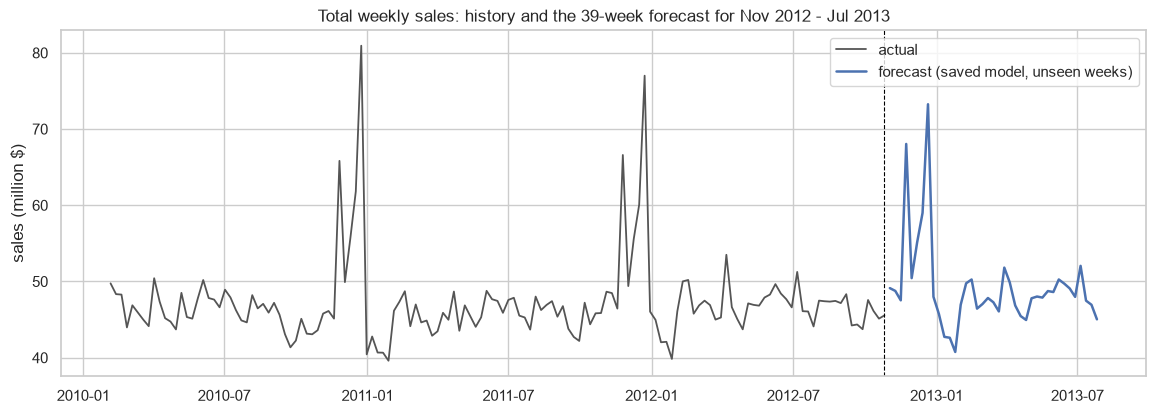

forecast Nov 2012 - Jan 2013 (13 weeks): 671.0M $ vs same weeks a year earlier: 667.1M $
biggest forecast weeks: {'2012-12-21': 73.3, '2012-11-23': 68.0, '2012-12-14': 59.0}
saved outputs/forecast_nov2012_jul2013.csv


In [79]:
# Load the File and predict unseen data.
saved = joblib.load("models/lgbm_long_term_forecaster.joblib")

# unseen weeks: 2 Nov 2012 to 26 Jul 2013 are in the features file but have no sales yet
future_dates = np.sort(features.loc[features["Date"] > df["Date"].max(), "Date"].unique())
active = df[df["Date"] > df["Date"].max() - pd.Timedelta(weeks=8)][CAT].drop_duplicates()   # still selling lately
fut = active.merge(pd.DataFrame({"Date": future_dates}), how="cross")
fut = fut.merge(features, on=["Store", "Date"], how="left").merge(stores, on="Store", how="left")
fut["Year"], fut["Month"] = fut["Date"].dt.year, fut["Date"].dt.month
fut["Week"] = fut["Date"].dt.isocalendar().week.astype(int)
fut["IsHoliday"] = fut["IsHoliday"].astype(int)
fut["Holiday"] = holiday_name(fut["Date"])
for h in HOLIDAYS:
    fut[f"Hol_{h}"] = (fut["Holiday"] == h).astype(int)
fut["PreChristmas"] = fut["Date"].isin(PRE_CHRISTMAS).astype(int)
fut["Easter"] = fut["Date"].isin(EASTER).astype(int)
fut["Type_Code"] = fut["Type"].map({"A": 0, "B": 1, "C": 2})
fut["MarkDown_Total"] = fut[MARKDOWN_COLS].sum(axis=1)
fut["Has_MarkDown"] = (fut["MarkDown_Total"] > 0).astype(int)
fut["MarkDown_Recorded"] = 1
with_hist = add_lag(pd.concat([df[CAT + ["Date", "Sales"]], fut]), 52, "Lag52")
fut = with_hist[with_hist["Date"] > df["Date"].max()].drop(columns="Sales")
fut = fut.merge(saved["sd_mean"], on=CAT, how="left")
fut["Forecast"] = saved["model"].predict(fut[saved["features"]]).clip(0)
print(f"forecast rows: {len(fut):,} ({active.shape[0]:,} store-depts x {len(future_dates)} weeks), "
      f"missing inputs: {int(fut[saved['features']].isna().sum().sum())} (Lag52/SD_Mean gaps are allowed)")

fut_total = fut.groupby("Date")["Forecast"].sum() / 1e6
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(weekly_total.index, weekly_total["Sales"] / 1e6, color="#555555", lw=1.3, label="actual")
ax.plot(fut_total.index, fut_total.values, color="#4C72B0", lw=1.8, label="forecast (saved model, unseen weeks)")
ax.axvline(df["Date"].max(), color="black", ls="--", lw=0.8)
ax.set_title("Total weekly sales: history and the 39-week forecast for Nov 2012 - Jul 2013")
ax.set_ylabel("sales (million $)")
ax.legend()
save_fig(fig, "future_forecast")
plt.show()

same_weeks_ly = weekly_total.loc[weekly_total.index >= "2011-11-04", "Sales"].iloc[:13].sum() / 1e6
print(f"forecast Nov 2012 - Jan 2013 (13 weeks): {fut_total.iloc[:13].sum():,.1f}M $ "
      f"vs same weeks a year earlier: {same_weeks_ly:,.1f}M $")
print("biggest forecast weeks:", {d.date().isoformat(): round(v, 1) for d, v in fut_total.nlargest(3).items()})
fut[CAT + ["Date", "Forecast"]].round(2).to_csv("outputs/forecast_nov2012_jul2013.csv", index=False)
print("saved outputs/forecast_nov2012_jul2013.csv")

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

I built a complete analytics workflow for a 45-store retail chain on 143 weeks of sales, and the main findings are:

1. Sales are driven by a short, predictable season. The year is flat at around 46M $ a week, then Thanksgiving (+43%) and the week before Christmas (+70%) dominate. The flagged Christmas week is actually below normal, and growth was only about 3% in almost three years.
2. Anomalies are often business events, not errors. The time-based analysis found Easter and the Christmas calendar shift as chain-wide anomalies, plus some store-specific events. The tuned Isolation Forest (F1 0.55 on injected anomalies, against 0.48 for the best z-score rule) flags 1.5% of weeks. More than half of them are seasonal or come back every year, so I kept those as real demand. Cleaning the one-off anomalies did not improve the forecast, so the final model is trained on the real sales.
3. Four store segments (silhouette 0.415, stability 0.82) need different plans: large stores in high-CPI regions, large stores in low-CPI regions, mid-size promotion-driven stores and small steady stores.
4. Departments move in groups (24/33/31, 5/55/72, 90/91/92, 18/1, 16/56), which gives cross-selling and joint stock planning ideas even without receipts.
5. The tuned long-term LightGBM forecasts 39 weeks ahead with a WMAE of 1,533 $ (15% better than the seasonal naive and better than Holt-Winters), and the short-term model reaches 1,300 $ for next week. The chain total is within about 2.2%.
6. External factors matter but are secondary. Together they improve the forecast by about 5%, temperature and unemployment matter most, falling unemployment went with faster store growth, and the biggest markdowns did not bring extra growth except in the promotion-driven segment.

The most valuable retail insight for me is that timing matters more than anything else. Getting the right stock into the right week (the real peak week, the moving Easter week, the segment that reacts to promotions) is worth more than any economic indicator. Next steps would be customer transaction data for real basket analysis, more history and days-to-holiday features for the moving holidays, controlled markdown tests, and regular retraining so the system can run in production.

The notebook, data, saved models, figures and output files are in the GitHub repository.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***